![Logo](LogoCab.png)

<div style="font-size: 12px;">
  <p style="margin: 0 0 8px 0; font-weight: bold; color: #FFF;">Group 55</p>
  <table style="border-collapse: collapse; margin: 0;">
    <tr><th style="text-align: left; padding: 4px 24px 4px 0; border-bottom: 1px solid #FFF;"> Name </th><th style="text-align: left; padding: 4px 0; border-bottom: 1px solid ##FFF;"> Student Number </th></tr>
    <tr><td style="padding: 4px 24px 4px 0;">Afonso Domingos</td><td>20260679</td></tr>
    <tr><td style="padding: 4px 24px 4px 0;">Mariana Silva</td><td>20260582</td></tr>
    <tr><td style="padding: 4px 24px 4px 0;">Miguel Santos</td><td>20260513</td></tr>
  </table>
</div>


# 1. Business Understanding

Amazing Creative Desk Coworking (ACDC) operates in a competitive coworking market with a diverse member base, where customers can differ considerably in terms of their membership plans, usage patterns, and engagement with the available services. Understanding these differences is important for identifying distinct customer groups and developing strategies that better respond to their needs.

This project focuses on the analysis of ACDC’s membership and space-usage data collected over a three-year period. By exploring customer characteristics, membership information, and behavioural patterns, the aim is to identify meaningful segments within the customer base. These insights can then be used to support a more targeted marketing strategy, helping ACDC improve customer satisfaction, retention, and overall business performance.

The analysis follows a data-driven approach to customer segmentation, considering different perspectives such as customer value and usage behaviour. The results of this analysis will provide the basis for the subsequent clustering process and the development of actionable business recommendations.

# Setup

## Libraries

The helper functions are in two files in the same folder as this notebook: `cleaning.py` (category spelling and the IQR outlier summary) and `charts.py` (all the charts, the project colours, the plan order and the list of add-on columns).

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from pathlib import Path
from matplotlib.lines import Line2D
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Reload cleaning.py and charts.py automatically when they are edited, without restarting the kernel
%load_ext autoreload
%autoreload 2

from cleaning import (
    normalize_country,
    normalize_gender,
    normalize_industry,
    normalize_plan_tier,
    iqr_summary,
)
from charts import (
    MAIN_COLOR,
    TIER_ORDER,
    TIER_COLORS,
    ADDON_COLUMNS,
    plot_histograms,
    chart_view,
    plot_category_shares,
    plot_addon_adoption,
    plot_plan_overview,
    plot_addons_by_plan,
    plot_usage_patterns,
    dormant_members,
    plot_profile_vs_plan,
)

# For better resolution plots
%config InlineBackend.figure_format = 'retina'

# Set theme for seaborn
sns.set_theme(style="whitegrid")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Constants

In [96]:
# Data files: the original file is kept untouched in data/raw, the cleaned dataset is written to data/clean
RAW_DATA_PATH = Path("../data/raw/acdc_dataset.csv")
CLEAN_DATA_PATH = Path("../data/clean/acdc_dataset_clean.csv")

# Data extraction date: no event in the data can happen after it
EXTRACTION_DATE = pd.Timestamp("2024-01-01")

# Average length of a month in days (365.25 days a year / 12 months), used for every "per month" value
DAYS_PER_MONTH = 30.44

# Minimum membership length (days) before a monthly value is trusted: very short stays inflate it
MIN_TENURE_DAYS = 30

# 2. Data Understanding

## 2.1 Load the Data

In this section, we load the coworking dataset from the CSV file using semicolons as column separators. 

In [97]:
dataset = pd.read_csv(RAW_DATA_PATH, sep=";", index_col="member_id")
n_rows_original = len(dataset)   # used in the cleaning summary

## 2.2 Metadata

In this section, we outline the variables included in the ACDC dataset. A clear understanding of the definition, type, and nature of each attribute is crucial for correctly interpreting customer behaviors, guiding feature engineering, and supporting the subsequent segmentation process.
This information is taken directly from the annex of the guidelines document.

In [98]:
metadata_dict = {
    "member_id": "Unique identifier of each member",
    "age": "Age of the member at the extraction date",
    "gender": "Gender of the member",
    "country": "The country where the member (or their associated company) is based",
    "industry": "The industry sector the member works in",
    "is_team_account": "Whether the membership is held by a team/company account rather than an individual",
    "n_colleagues_on_account": "Number of colleagues sharing the account",
    "plan_tier": "Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)",
    "plan_days_per_week": "Number of days per week the member's plan entitles them to use the space",
    "membership_start": "Date the membership first began",
    "membership_end": "Date the membership first ended",
    "last_badge_swipe": "Date of the member's most recent physical entry to the space",
    "days_since_last_visit": "Number of days since the member's last recorded visit",
    "total_visits": "Total number of visits the member made over the whole membership",
    "avg_weekly_visits": "Average number of visits per week over the membership",
    "entitled_visits_last_period": "Number of visits the member's plan entitled them to during the last period of their membership",
    "actual_visits_last_period": "Number of visits the member actually made during the last period of their membership",
    "meeting_room_hours": "Hours of meeting-room usage recorded for the member",
    "event_space_hours": "Hours of event-space usage recorded for the member",
    "guest_passes_issued": "Number of guest passes the member issued",
    "uses_meeting_rooms": "Whether the member ever used the meeting-room add-on",
    "uses_event_space": "Whether the member ever used the event-space add-on",
    "uses_guest_passes": "Whether the member ever used the guest-pass add-on",
    "uses_print": "Whether the member used the print add-on",
    "uses_mail_handling": "Whether the member used the mail-handling add-on",
    "uses_phone_booths": "Whether the member used the phone-booth add-on",
    "uses_day_passes": "Whether the member used the day-pass add-on",
    "uses_storage": "Whether the member used the storage add-on",
    "uses_bike_locker": "Whether the member used the bike-locker add-on",
    "n_renewals": "Number of times the membership was renewed",
    "lifetime_value": "Total revenue attributed to the member over the whole membership"
}

# convert the metadata dictionary to a DataFrame for better visualization
df_meta = pd.DataFrame(list(metadata_dict.items()), columns=["Variable", "Description"]).set_index("Variable")

# Set pandas display options to show all rows and columns without truncation
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

df_meta

,Description
Variable,
member_id,Unique identifier of each member
age,Age of the member at the extraction date
gender,Gender of the member
country,The country where the member (or their associated company) is based
industry,The industry sector the member works in
is_team_account,Whether the membership is held by a team/company account rather than an individual
n_colleagues_on_account,Number of colleagues sharing the account
plan_tier,Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)
plan_days_per_week,Number of days per week the member's plan entitles them to use the space


## 2.3 First Look at the Dataset

In [99]:
print('Dataset shape:', dataset.shape)

Dataset shape: (15465, 30)


In [100]:
dataset.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74


In [101]:
dataset.tail()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,2023-07-01,2023-06-28,3,74,2.55,26.09,21,0.0,0.0,0.0,False,False,False,1,True,True,False,False,False,0,1422.36
CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,2023-10-06,2023-10-04,2,407,3.71,43.48,31,30.1,17.6,0.0,True,True,False,1,False,True,True,True,False,4,11834.5
CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,2022-04-19,2022-02-12,66,5,0.45,26.09,4,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,435.82


In [102]:
dataset.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object')

The dataset has 15465 members and 30 variables, covering their profile, plan, visits, add-on usage and value. At first glance there are already some warning signs, such as categories written in different ways, dates in two formats and an end date of 1970-01-01, which we look at in detail in the next section.

## 2.4 Data Quality Assessment

In [103]:
df_meta["Data Type"] = dataset.dtypes
df_meta

,Description,Data Type
Variable,,
member_id,Unique identifier of each member,NaN
age,Age of the member at the extraction date,float64
gender,Gender of the member,object
country,The country where the member (or their associated company) is based,object
industry,The industry sector the member works in,object
is_team_account,Whether the membership is held by a team/company account rather than an individual,bool
n_colleagues_on_account,Number of colleagues sharing the account,int64
plan_tier,Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office),object
plan_days_per_week,Number of days per week the member's plan entitles them to use the space,int64


In [104]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

In this section, we review the data types (`dtypes`) of each feature to ensure they are correctly formatted for subsequent exploratory analysis and clustering algorithms. Based on our structural inspection (`df.info()`), several discrepancies and necessary type conversions have been identified:

- date variables (`membership_ends`, `membership_starts` and `last_badge_swipe`) are currently cast as String(`object`) but should be cast to `dateTime`.
- `age` and `guest_passes_issued` are currently stored as float64 due to the presence of missing values. Since both represent a discrete value,  these variables should be converted to integer (`int`) after handling the missing values.
- `entitled_visits_last_period` is stored as a float rather than an integer, likely because it is a calculated value. This needs further inspection.
- `uses_print` represents binary usage but is currently stored as numeric integer (`int64`). It should be cast to boolean (`bool`) to match the other binary flags in the dataset.
- Lifetime Value (`lifetime_value`): Currently stored as an object (`string`) instead of a numeric type. This hints at the presence of formatting characters (such as currency symbols or spaces) that must be cleaned, parsed, and converted to `float` to correctly measure the economic contribution of each member.

In [105]:
temp_df = dataset.copy()
temp_df.drop(columns=["uses_print"]).describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


The descriptive statistics (`describe()`) already show several values that cannot be real. `age` ranges from 1 to 149, `n_colleagues_on_account` and `plan_days_per_week` take values that match no account or plan (-1, 0 and 9), and counts and hours such as `total_visits`, `n_renewals`, `meeting_room_hours` and `days_since_last_visit` have negative values. These are not outliers but errors, and they are corrected in Section 3.
There are also values that are possible but extreme, such as `total_visits` up to 6,530 or `meeting_room_hours` far above the 75th percentile. These are examined as outliers in Section 3.7. Finally, members make on average about half of the visits their plan allows (13.8 actual against 27.5 entitled in the last period), a first sign that many members use much less than they pay for.

In [106]:
dataset.describe(include='object').T

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


`gender` has 12 different values where there should only be 3, so the same category is written in several ways. Most members are based in Portugal. 3,956 memberships end on 1970-01-01, the default date many systems use for an empty field, so these are probably members who are still active. `lifetime_value` has almost 12000 different values, so it is a number stored as text. 1725 members have a value of 0, which is looked at in Section 3.

In [107]:
summary = pd.DataFrame({
    "Non-null values": dataset.count(),
    "Unique values": dataset.nunique(),
    "Missing count": dataset.isnull().sum(),
    "Missing %": dataset.isnull().mean() * 100,
    "Negative values": (dataset.select_dtypes(include=[np.number]) < 0).sum(),
})

summary

,Non-null values,Unique values,Missing count,Missing %,Negative values
actual_visits_last_period,15465,61,0,0.000000,0.0
age,14907,84,558,3.608147,0.0
avg_weekly_visits,15465,616,0,0.000000,0.0
country,15035,33,430,2.780472,NaN
days_since_last_visit,15465,430,0,0.000000,56.0
entitled_visits_last_period,15465,1876,0,0.000000,0.0
event_space_hours,15465,824,0,0.000000,8.0
gender,14935,12,530,3.427093,NaN
guest_passes_issued,14194,205,1271,8.218558,7.0
industry,15465,43,0,0.000000,NaN


The table above tells us how many unique values, how many missing and, if numeric, how many negatives each feature has. We have to keep in mind that there might be missing values in other forms for example a country that doesn't exist.

### Unique Values

In [108]:
for column in dataset.columns:
    unique_values = dataset[column].unique()
    print(f"Unique values on the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

Unique values on the column 'age': [ 38.  43.  45.  39.  23.  33.  30.  44.  37. 131.  20.  40.  32.  21.
  29.  25.  28.  51.  41.  nan  31.  42.  34.  36.  50.  24.  19.  47.
  54.  26.  53.  27.  46.  18.  48.  63.  35.  22.  59.  49.   4.   3.
  58.  72.   9.   8.  57.  52.  73. 132.  60.  55. 144.  61.   1.   6.
 141.   2.   7. 137.  66. 147. 140. 142.  56.  62. 145.   5.  65.  83.
  14. 138. 136. 146. 134.  70.  74.  93.  92. 143. 139.  91.  64. 149.
 135.]
-----------------------------------

Unique values on the column 'gender': ['Female' 'Male' 'F' 'Other' nan ' Female' 'M' 'male' ' Male' 'other'
 ' Other' 'female' 'O']
-----------------------------------

Unique values on the column 'industry': ['Information Technology' 'Education' 'Legal' 'Health' 'Unknown' 'Other'
 'Consulting' 'Design & Creative' 'information technology' 'Finance'
 'Marketing & PR' 'EDUCATION' 'DESIGN & CREATIVE' 'Marketing and PR'
 'Real Estate' 'other' 'consulting' 'MARKETING & PR'
 'Information technolo

The dates mix two formats, YYYY-MM-DD and DD/MM/YYYY. The text columns have the same category written in several ways (“HOT_DESK”, “hot_desk”, “hotdesk”, “Portugal”, “portugal”, “PT”), so the number of unique values is inflated. age has impossible values, from 1 to 14 and from 131 to 149.

### Value Counts

In [109]:
for column in dataset.columns:
    unique_values = dataset[column].value_counts()
    print(f"The number of the distinct values in the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

The number of the distinct values in the column 'age': age
34.0     710
31.0     679
32.0     658
36.0     655
35.0     650
33.0     647
38.0     637
37.0     626
30.0     619
29.0     597
39.0     588
40.0     546
28.0     528
41.0     516
42.0     474
27.0     450
26.0     449
43.0     422
25.0     420
24.0     372
44.0     357
23.0     333
45.0     303
22.0     290
21.0     269
46.0     250
47.0     242
20.0     214
48.0     187
49.0     175
19.0     169
50.0     124
51.0     109
52.0     105
53.0      80
18.0      73
54.0      64
55.0      36
3.0       26
4.0       26
56.0      26
58.0      25
57.0      22
59.0      14
61.0      11
9.0       11
60.0      10
141.0      9
2.0        8
7.0        8
131.0      7
63.0       7
8.0        6
6.0        6
62.0       5
5.0        4
140.0      4
83.0       4
134.0      4
72.0       3
135.0      3
66.0       3
132.0      3
144.0      2
93.0       2
142.0      2
65.0       2
1.0        2
136.0      2
64.0       2
146.0      2
73.0       1
145.0

### Duplicates

In [110]:
#Check how many duplicates exist
print(f"number of duplicates: {dataset.duplicated().sum()}")

#check the percentage of duplicates in our DataFrame
print(f"percentage of duplicates: {dataset.duplicated().sum() / len(dataset) * 100:.2f}%")

print(f"number of duplicate indices: {dataset.index.duplicated().sum()}")

number of duplicates: 182
percentage of duplicates: 1.18%
number of duplicate indices: 15


With `member_id` as the index, `duplicated()` compares the 30 feature columns and finds 182 repeated rows. Checking the index separately shows 15 repeated IDs, all exact copies of an earlier row. The remaining 182-15=167 rows are identical to another member in every field, including dates and lifetime value, but have a different ID. They are most likely the same member registered twice. We remove all 182, keeping the first occurrence, so that no member counts twice in the clustering.

Duplicates are removed already here, before the raw distributions, so that repeated members don't distort the counts below. All the other problems are only identified in this section and fixed in Section 3 (Data Preparation).

In [111]:
#we drop the duplicates from the DataFrame with index
dataset.drop_duplicates(inplace= True)

# Check that the duplicates were removed
dataset.duplicated().sum()

np.int64(0)

## 2.5 Format Standardisation

In CRISP-DM, fixing formats is a Data Preparation task. We do it here, before the exploration, because the charts below need real dates, numeric values and one spelling per category. The values themselves are only cleaned in Section 3.

Before plotting anything we sort out the formats. The same plan shows up as "HOT_DESK", "hotdesk" and "Hot Desk", the dates come in two different formats, and `lifetime_value` is stored as text. None of this changes what the data says, it only makes it readable, so it makes sense to do it first. Fixing the actual values (impossible ages, placeholders, negatives) is left for the cleaning section, after the plots.

In [112]:
dataset_raw = dataset.copy()  # keep a copy of the raw data for later comparison

In [113]:
# The file mixes two date formats (YYYY-MM-DD and DD/MM/YYYY), so each one is read with its own format.
# Reading each format explicitly guarantees that no date is read with the day and month swapped.
for column in ["membership_start", "membership_end", "last_badge_swipe"]:
    iso_dates = pd.to_datetime(dataset[column], format="%Y-%m-%d", errors="coerce")
    european_dates = pd.to_datetime(dataset[column], format="%d/%m/%Y", errors="coerce")
    dataset[column] = iso_dates.fillna(european_dates)

In [114]:
dataset["uses_print"] = dataset["uses_print"].astype(bool)

In [115]:
dataset["country"] = dataset["country"].apply(normalize_country)
dataset["gender"] = dataset["gender"].apply(normalize_gender)
dataset["industry"] = dataset["industry"].apply(normalize_industry)
dataset["plan_tier"] = dataset["plan_tier"].apply(normalize_plan_tier)

In [116]:
dataset["lifetime_value"] = pd.to_numeric(dataset["lifetime_value"].str.replace(",", "").str.replace("€", "").str.strip(), errors='coerce')

In [117]:
# Quick check that each category now has a single spelling
for column in ["plan_tier", "gender", "country", "industry"]:
    print(f"{column}: {sorted(dataset[column].dropna().unique())}\n")

plan_tier: ['dedicated desk', 'flex', 'full time', 'hot desk', 'private office']

gender: ['female', 'male', 'other']

country: ['france', 'germany', 'ireland', 'netherlands', 'other (europe)', 'portugal', 'spain', 'united kingdom']

industry: ['consulting', 'design & creative', 'education', 'finance', 'health', 'information technology', 'legal', 'marketing & pr', 'other', 'real estate', 'unknown']



## 2.6 Exploratory Data Analysis

We start with the distribution of each numeric variable, mostly to spot problems. Then we cross variables with each other to see what kind of members are behind the numbers. The values are not cleaned yet, so every chart simply leaves out the values we already know are impossible.

### 2.6.1 Distributions of the Raw Data

Before cleaning, we look at the distribution of each numeric variable to find problems (placeholders, impossible values and extreme values), which are fixed in Section 3. The full exploration is done on the clean data in Section 4.

The y-axis uses a log scale so that values held by only a few members are still visible. lifetime_value is left out for now, because a few values of millions of euros would squeeze the rest of the histogram into one bar.

#### Histograms - Descriptive Statistics and Numerical Distributions

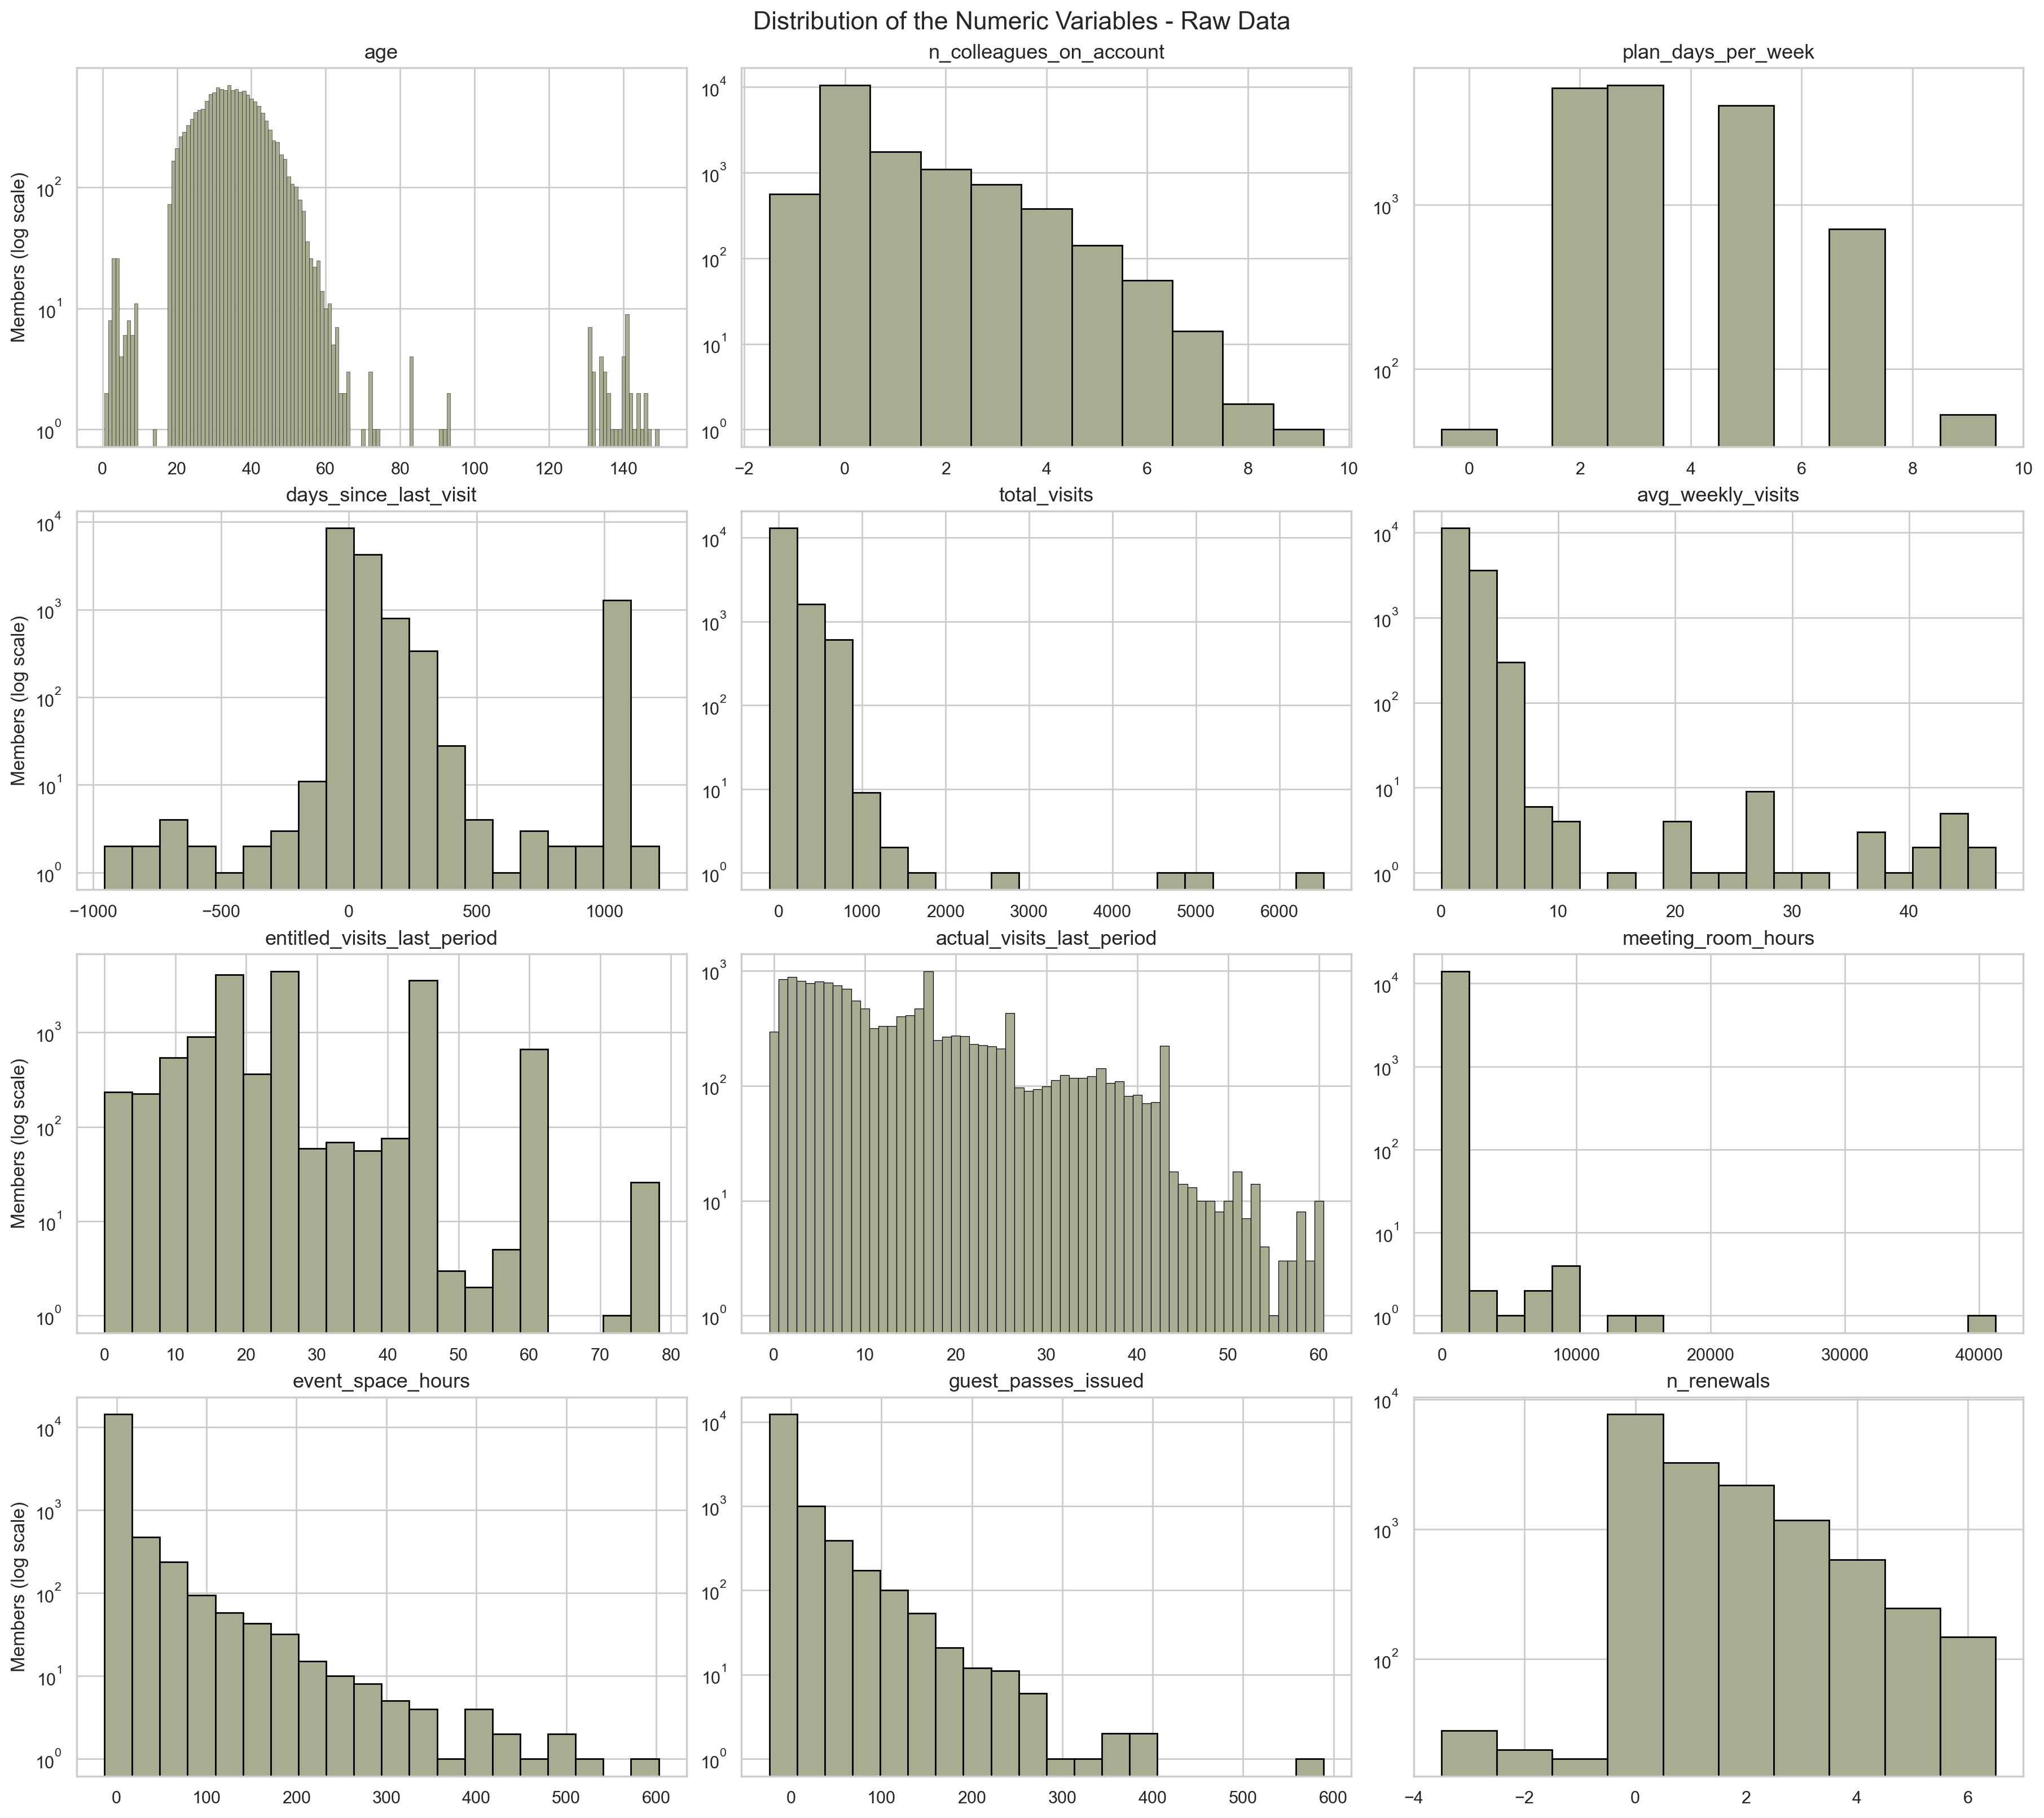

In [118]:
# Numeric variables to plot
numeric_features = [
    'age',
    'n_colleagues_on_account',
    'plan_days_per_week',
    'days_since_last_visit',
    'total_visits',
    'avg_weekly_visits',
    'entitled_visits_last_period',
    'actual_visits_last_period',
    'meeting_room_hours',
    'event_space_hours',
    'guest_passes_issued',
    'n_renewals'
]

# Whole-number variables with a limited range, plotted with one bar per value
discrete_features = ['age', 'n_colleagues_on_account', 'plan_days_per_week', 'actual_visits_last_period', 'n_renewals']

plot_histograms(dataset, numeric_features, "Distribution of the Numeric Variables - Raw Data", discrete_features)

In [119]:
# Shape of each distribution:
# - Skewness: 0 = symmetric, above 1 = strongly right-skewed (long tail of high values)
# - Zeros (%): share of zeros among the recorded (non-missing) values
distribution_summary = pd.DataFrame({
    "Skewness": dataset[numeric_features].skew(),
    "Zeros (%)": (dataset[numeric_features] == 0).sum() / dataset[numeric_features].notna().sum() * 100
})

distribution_summary.round(2)

,Skewness,Zeros (%)
age,3.04,0.00
n_colleagues_on_account,2.12,69.12
plan_days_per_week,0.93,0.28
days_since_last_visit,2.72,0.55
total_visits,6.86,0.70
avg_weekly_visits,10.24,0.09
entitled_visits_last_period,0.73,0.07
actual_visits_last_period,1.06,1.92
meeting_room_hours,70.43,65.20
event_space_hours,9.18,88.50


In [120]:
# Members affected by each problem seen in the histograms
data_problems = {
    "age below 18": (dataset["age"] < 18).sum(),
    "age above 100": (dataset["age"] > 100).sum(),
    "n_colleagues_on_account = -1": (dataset["n_colleagues_on_account"] == -1).sum(),
    "plan_days_per_week not 2, 3, 5 or 7": (~dataset["plan_days_per_week"].isin([2, 3, 5, 7])).sum(),
    "days_since_last_visit = 999": (dataset["days_since_last_visit"] == 999).sum(),
    "days_since_last_visit below 0": (dataset["days_since_last_visit"] < 0).sum(),
    "total_visits above 1,100": (dataset["total_visits"] > 1100).sum(),       # more visits than days in the 3-year period
    "avg_weekly_visits above 7": (dataset["avg_weekly_visits"] > 7).sum(),    # more than one visit per day
    "meeting_room_hours above 1,000": (dataset["meeting_room_hours"] > 1000).sum(),
}

# Negative values are impossible for counts and hours
for column in ["total_visits", "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals"]:
    data_problems[f"{column} below 0"] = (dataset[column] < 0).sum()

# Without the impossible ages, age is almost symmetric
age_valid = dataset.loc[dataset["age"].between(18, 100), "age"]
print(f"Skewness of age between 18 and 100: {age_valid.skew():.2f}")

pd.Series(data_problems, name="Members").to_frame()

Skewness of age between 18 and 100: 0.44


,Members
age below 18,98
age above 100,45
n_colleagues_on_account = -1,562
"plan_days_per_week not 2, 3, 5 or 7",96
days_since_last_visit = 999,1280
days_since_last_visit below 0,56
"total_visits above 1,100",7
avg_weekly_visits above 7,41
"meeting_room_hours above 1,000",19
total_visits below 0,42


**What the histograms show (raw data):**

*Problems to fix in the cleaning step* (counts in the table above)
- `age`: impossible ages from 1 to 14 (98 members) and from 131 to 149 (45). Without them, age is almost symmetric.
- `n_colleagues_on_account`: a bar at −1 (562 members), a placeholder rather than a real count.
- `plan_days_per_week`: 96 members with 0 or 9 days, which match no plan.
- `days_since_last_visit`: a spike at 999 (1,280 members), which is a placeholder, and 56 negative values down to −956.
- Values far from the rest: 7 members with more than 1,100 `total_visits` (more visits than days in the 3-year period, up to 6,530), 41 members averaging more than 7 visits per week (more than one per day, up to 47.4) and 19 members with more than 1,000 `meeting_room_hours` (up to 41,220).
- Negative values, impossible for counts and hours, in `total_visits`, `meeting_room_hours`, `event_space_hours`, `guest_passes_issued` and `n_renewals`.

*Shape of the data*
- The service-usage variables are mostly zeros with a long tail: 65% of the recorded `meeting_room_hours`, 88.5% of `event_space_hours` and 82.5% of `guest_passes_issued` are 0. Most members never use these services, while a few use them a lot. In distance-based clustering, these few members would dominate unless the variables are transformed (e.g. log scale) or turned into used / not used flags.
- `entitled_visits_last_period` has one spike per plan, which suggests it is calculated from the plan.
- `actual_visits_last_period` piles up at the full entitlement of each plan, which means some members come every day they can.

### 2.6.2 Relationships Between Variables

The histograms show each variable on its own. Here we put them side by side. A few things from the histograms are worth following up: `entitled_visits_last_period` has one spike per plan, so the plan seems to drive a lot; `actual_visits_last_period` piles up at the full entitlement of each plan, so some members come every day they can; the service variables are mostly zeros; and `days_since_last_visit` has a long tail of members who have not been in for a while.

The functions for these charts are in `charts.py`, so we can run exactly the same charts again after the cleaning.

In [121]:
eda_before = chart_view(dataset)

#### 2.6.2.1 Categorical Variables

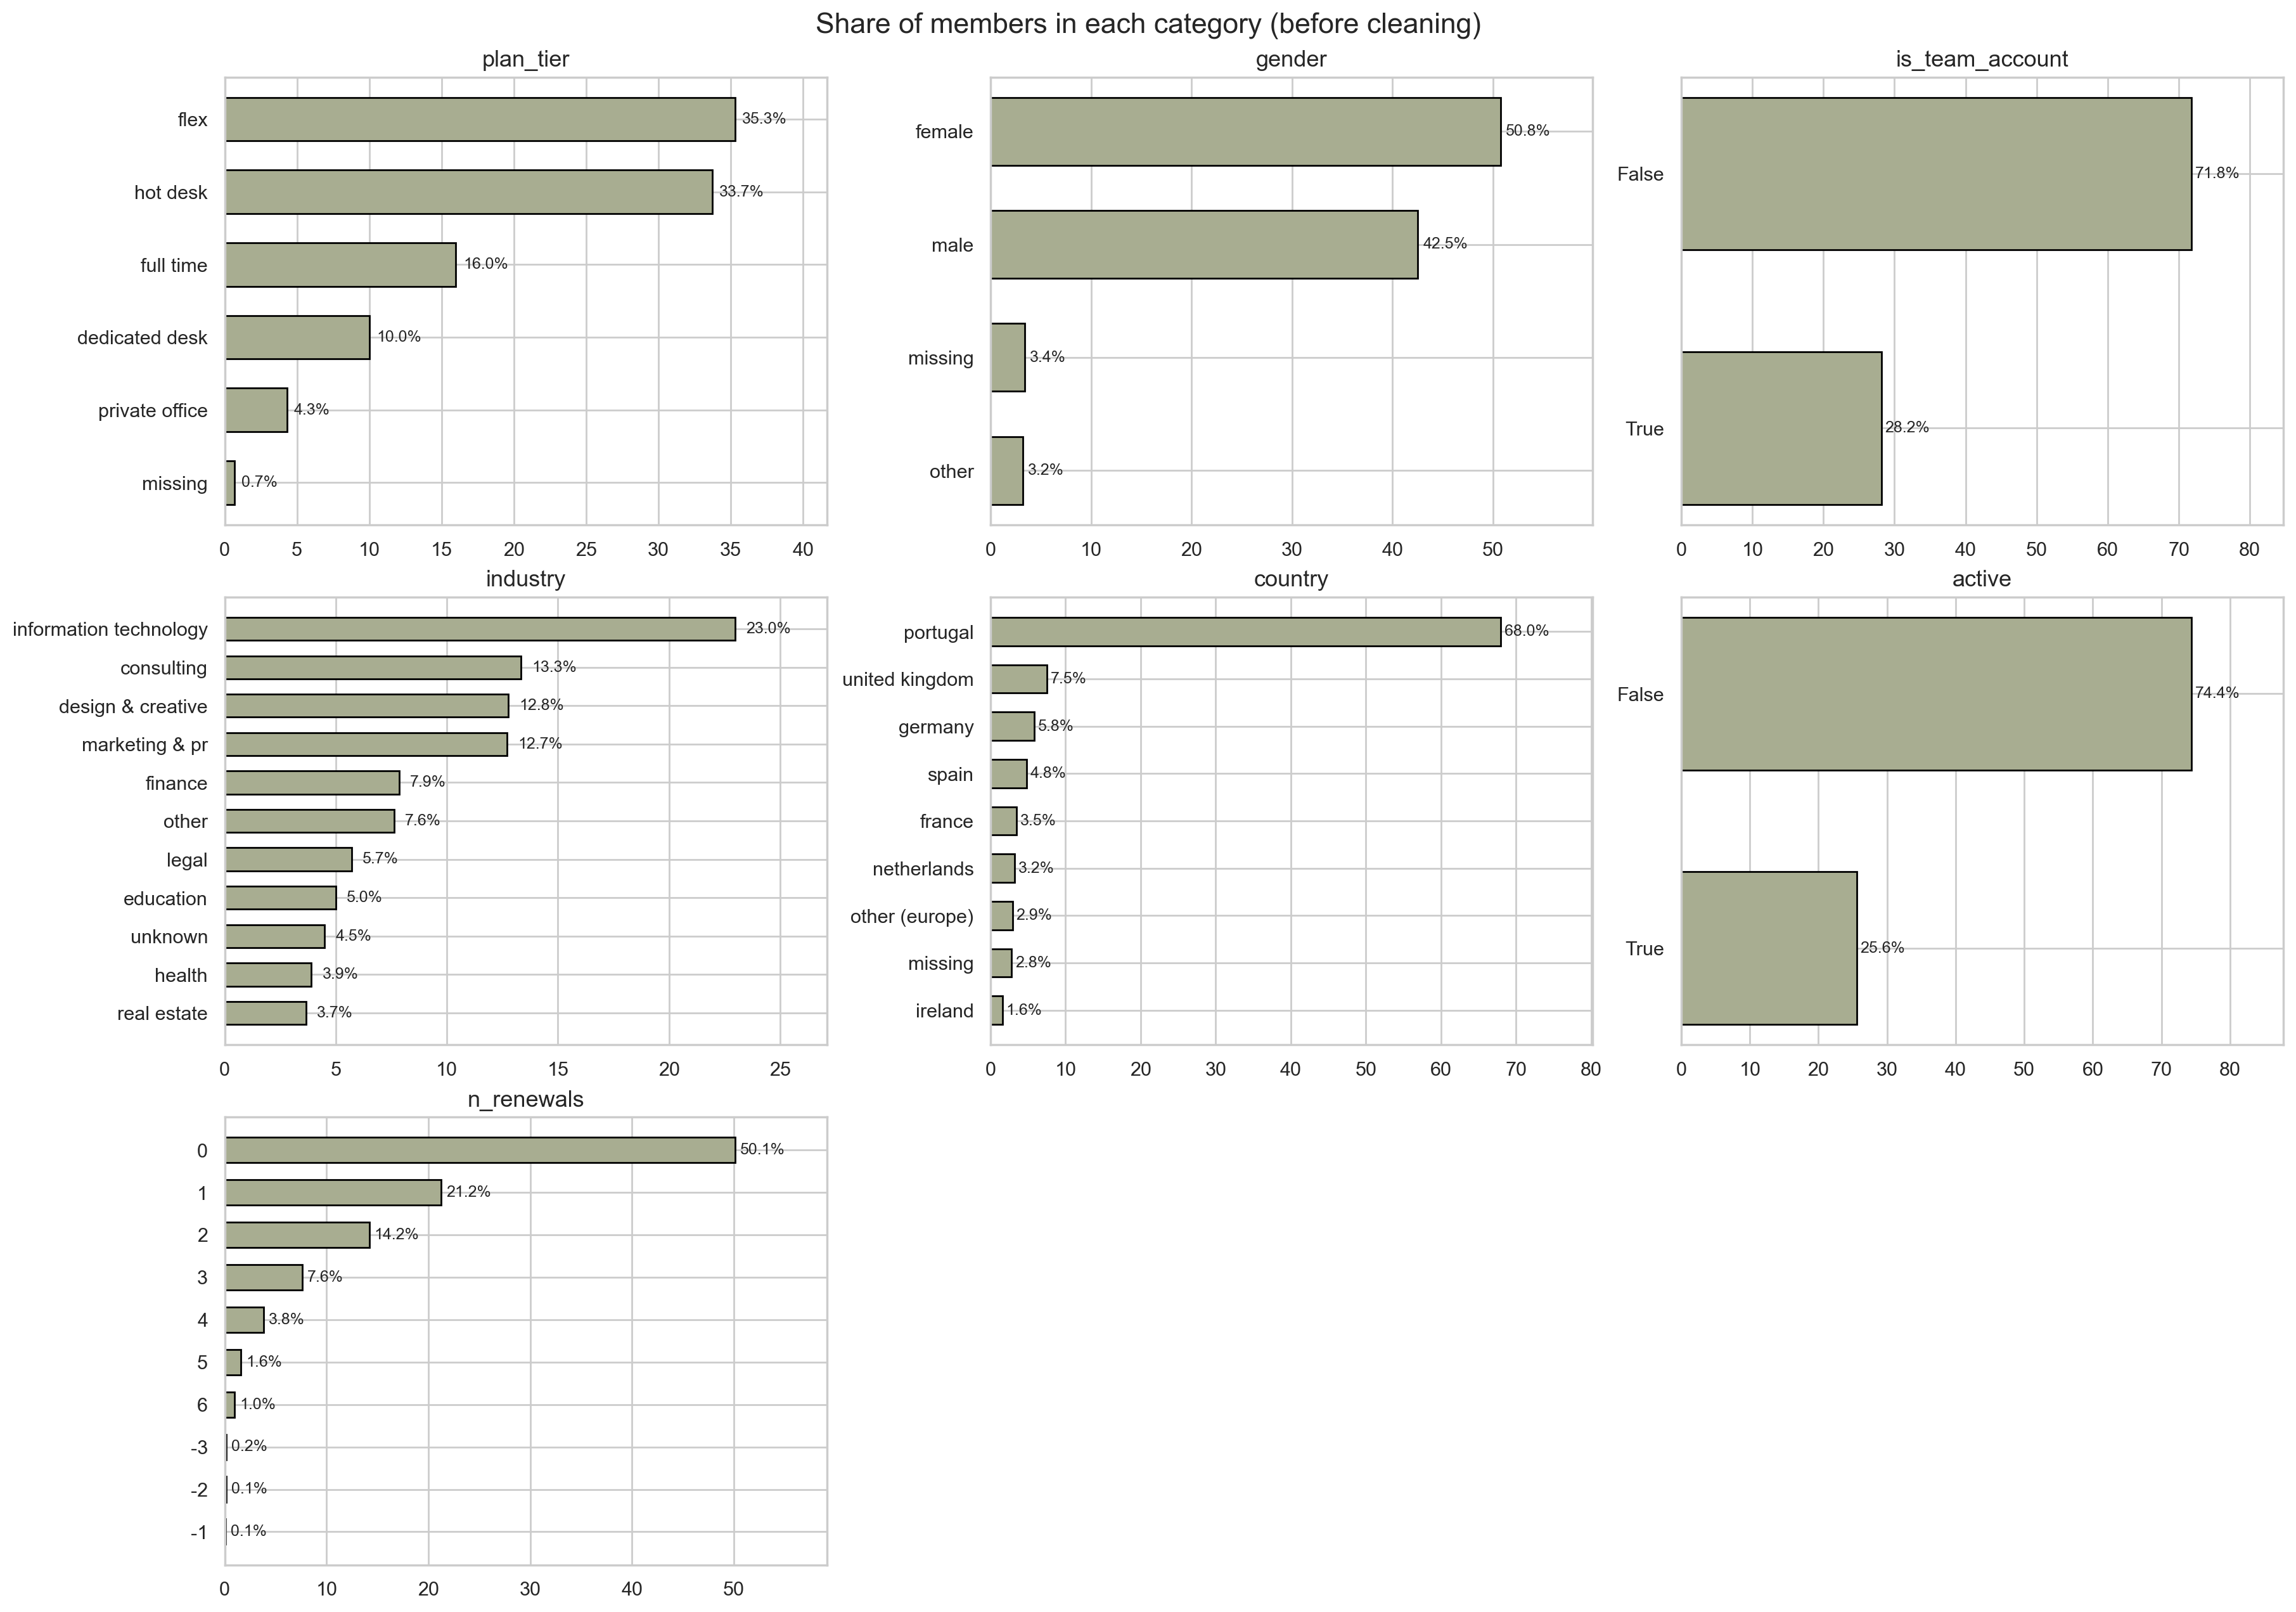

In [122]:
plot_category_shares(eda_before, ["plan_tier", "gender", "is_team_account", "industry", "country", "active", "n_renewals"],
                     "Share of members in each category (before cleaning)")

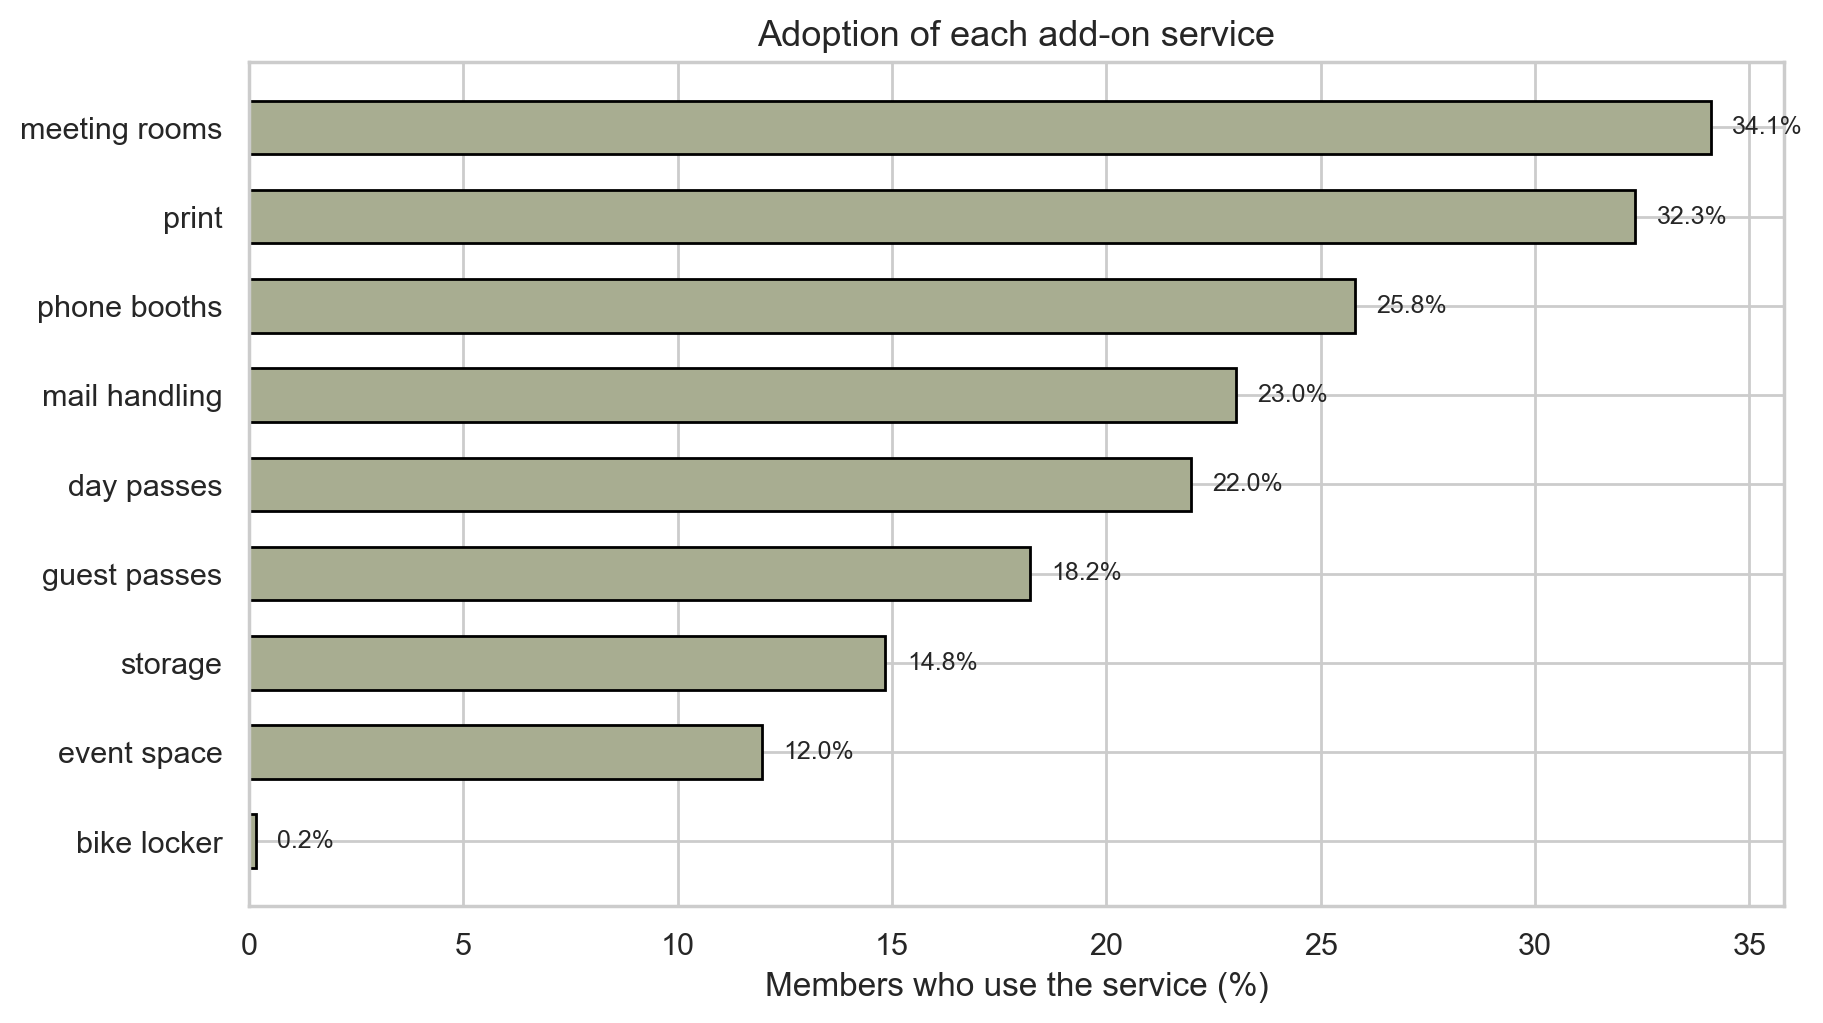

,% of members
Add-ons used,
0,20.0
1,30.0
2,20.9
3,13.9
4,9.1
5,4.5
6,1.4
7,0.2
8,0.0


In [123]:
plot_addon_adoption(eda_before)

Flex and hot desk together are about two thirds of the members, and the premium plans are small (private office is around 4%). Only about a quarter of the memberships are still active and half of the members never renewed, so keeping members seems to be ACDC's biggest problem.

Most people are based in Portugal and IT is the largest industry. Gender is fairly balanced. Around 28% of the accounts belong to a team.

Add-ons are used quite selectively. Meeting rooms and printing are the most common (roughly a third of members each), the bike locker is basically never used, and one in five members uses no add-on at all.

#### 2.6.2.2 Plans: Value, Retention and Usage

Since the plan looked so important in the histograms, we compare the plans directly.

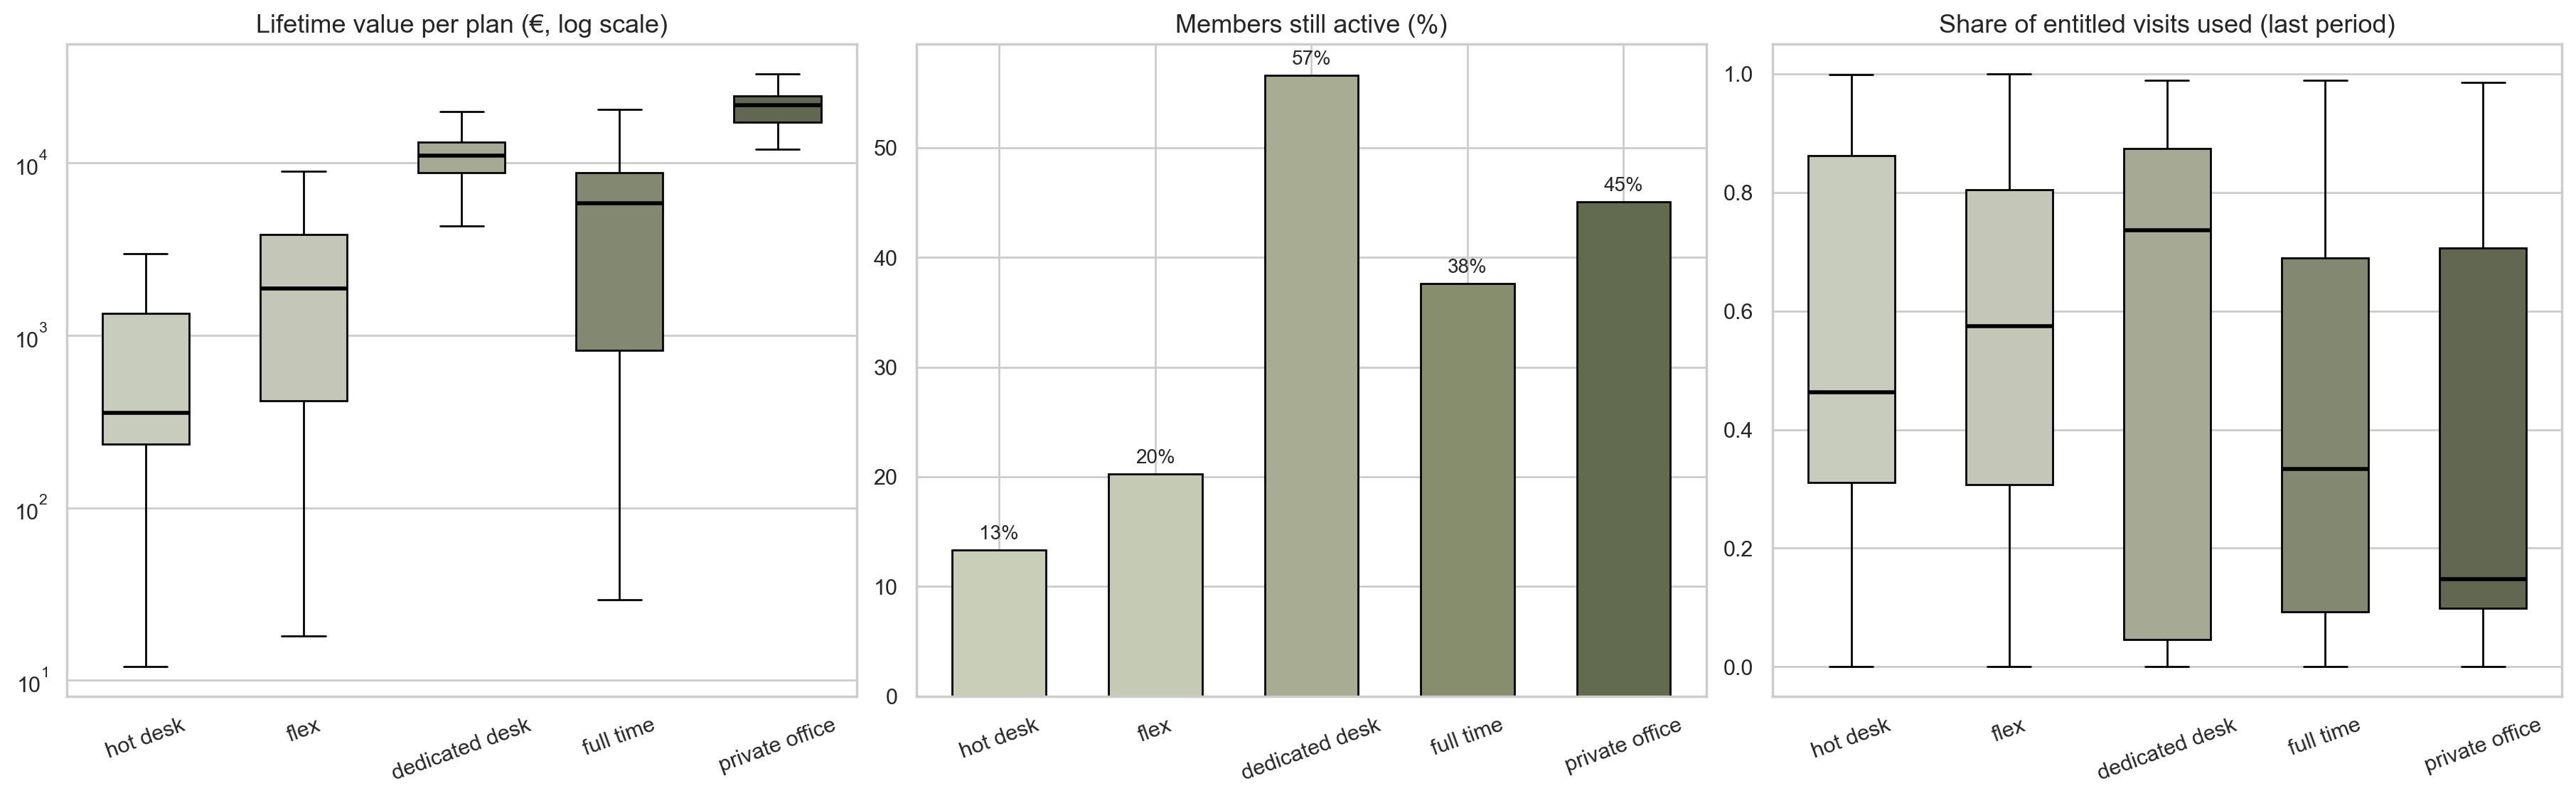

,members,median_lifetime_value,active_pct,median_utilisation,median_renewals
plan_tier,,,,,
hot desk,5153,355.73,13.33,0.46,0.0
flex,5394,1868.24,20.28,0.57,0.0
dedicated desk,1532,11036.10,56.59,0.74,2.0
full time,2444,5861.37,37.64,0.33,1.0
private office,657,21535.65,45.05,0.15,2.0


In [124]:
plot_plan_overview(eda_before)

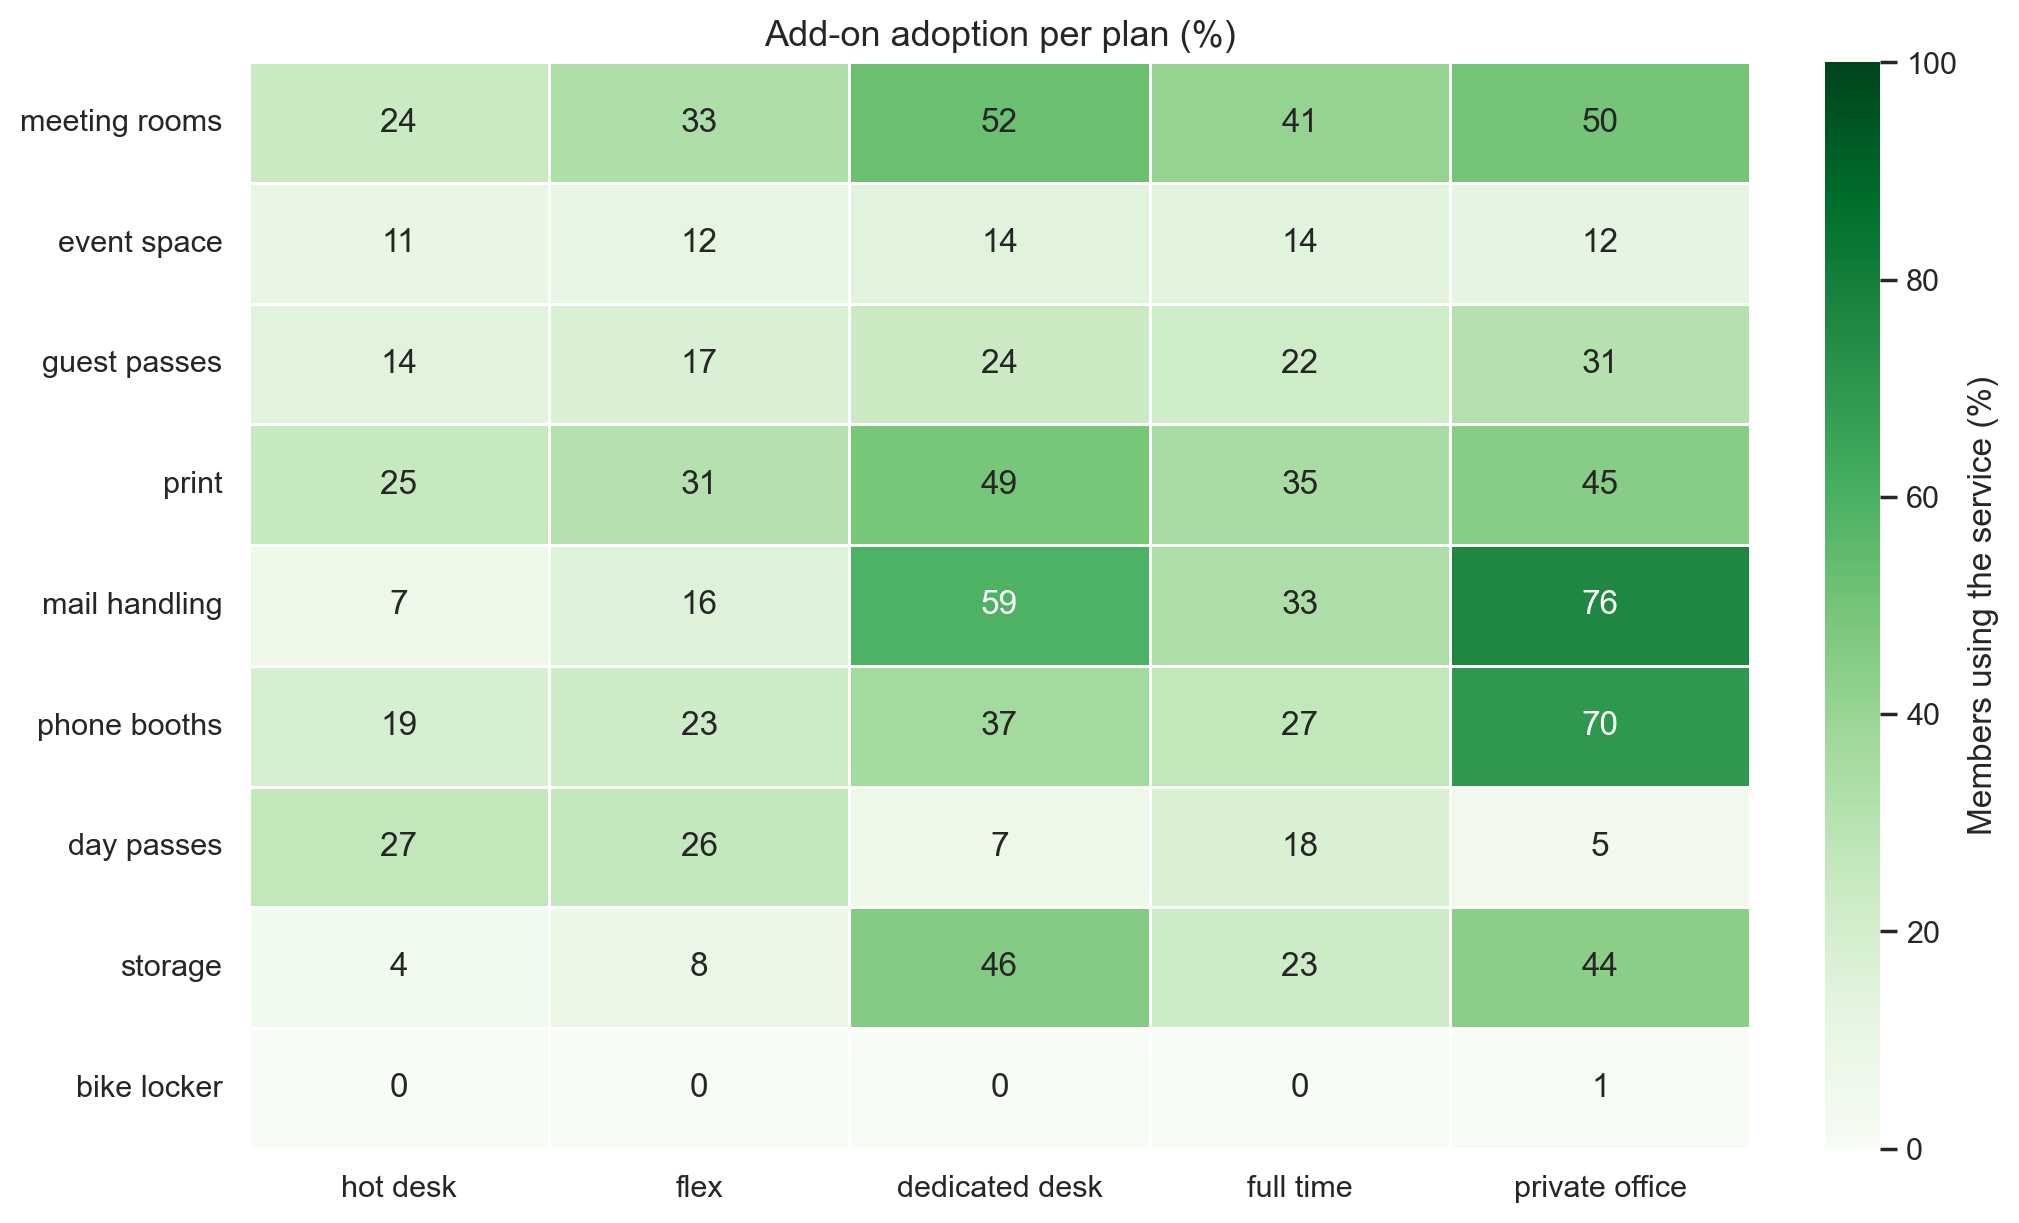

In [125]:
plot_addons_by_plan(eda_before)

Lifetime value grows a lot with the plan, from a median of a few hundred euros on hot desk to more than 20,000 € on private office. What surprised us is that dedicated desk members are worth almost twice as much as full time members, even though both plans give five days a week. They simply stay longer: more than half of the dedicated desk members are still active, against only 13% on hot desk.

Paying more does not mean coming more often, though. Dedicated desk members use most of their days, but private office members use only around 15% of theirs. Our guess is that many private offices are paid by companies and used now and then.

The add-ons also tell different stories per plan. Private office members use mail handling and phone booths a lot, which looks like a business address. Dedicated desk members use storage. Hot desk and flex members are the ones buying day passes.

#### 2.6.2.3 Usage Patterns

Here we look for differences between members on the same plan, since that is what clustering can add on top of the plan. Dividing actual visits by entitled visits puts every plan on the same 0 to 1 scale.

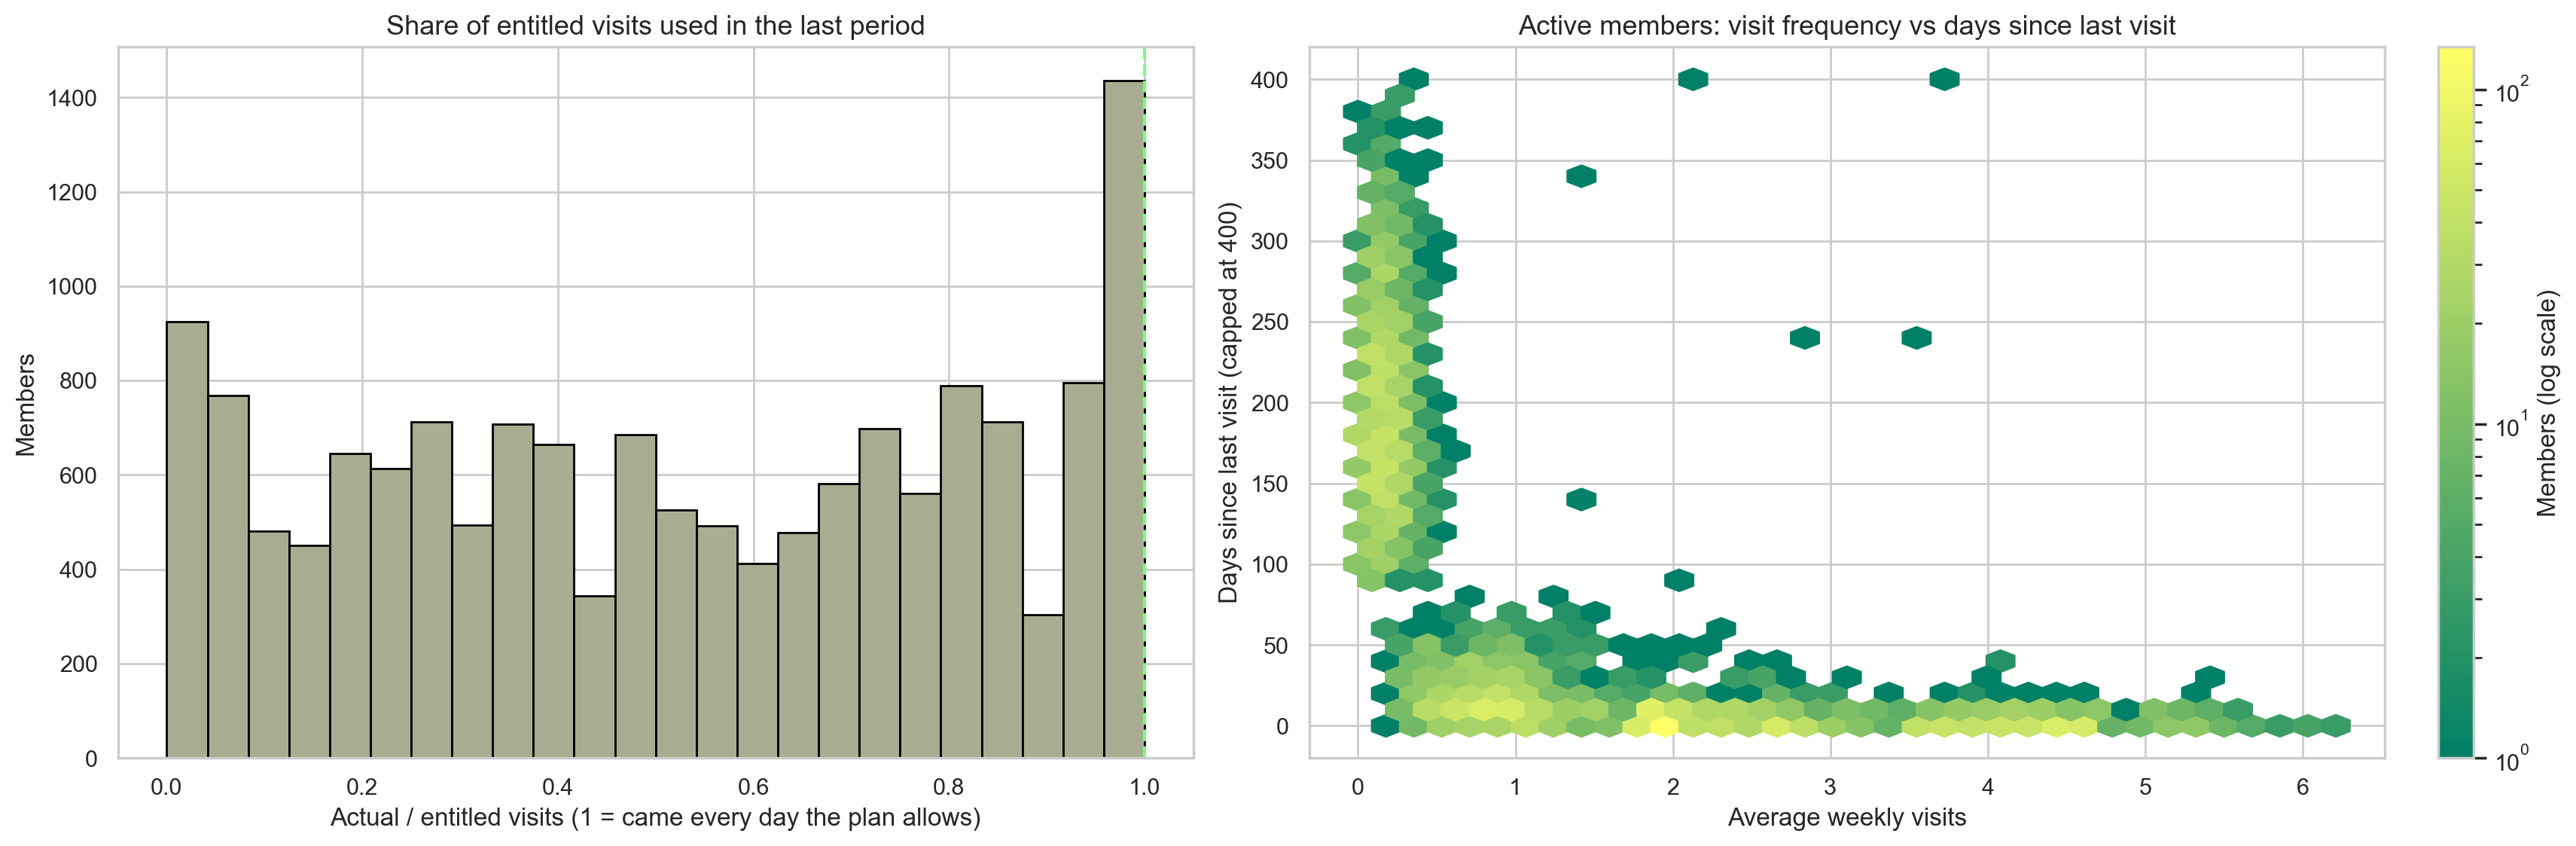

utilisation,below 20%,20-80%,above 80%
plan_tier,,,
hot desk,10.7,59.4,29.9
flex,15.0,58.8,26.1
dedicated desk,34.7,25.3,40.0
full time,34.4,51.7,13.9
private office,59.9,27.0,13.1


In [126]:
plot_usage_patterns(eda_before)

In [127]:
dormant_members(eda_before)

Active members: 3912  |  no visit for more than 90 days: 1287 (33%)


,% of dormant active members
plan_tier,
full time,39.4
dedicated desk,35.0
flex,25.6
hot desk,0.0
private office,0.0


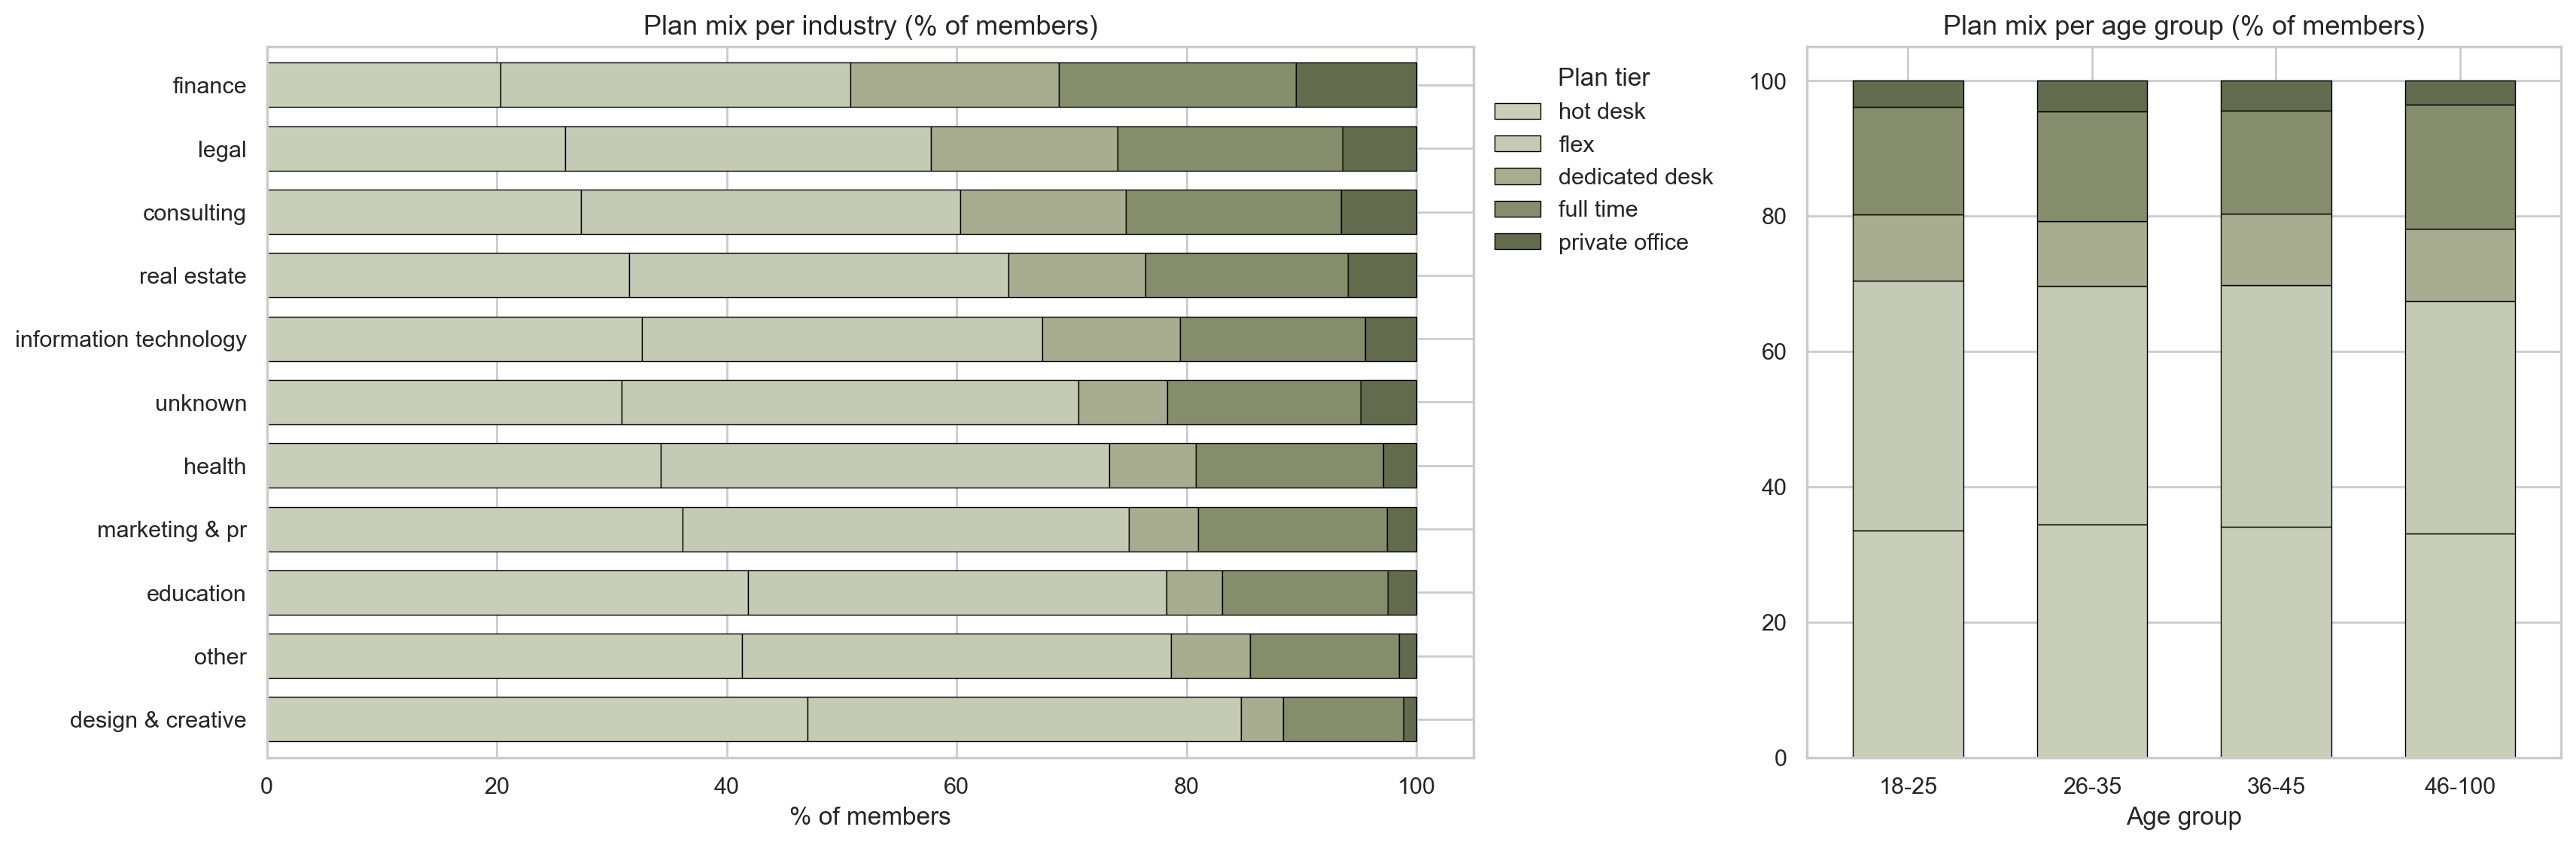

is_team_account,False,True
plan_tier,,
hot desk,71.9,28.1
flex,71.2,28.8
dedicated desk,72.4,27.6
full time,73.1,26.9
private office,68.5,31.5


In [128]:
plot_profile_vs_plan(eda_before)

Utilisation is not a nice bell curve. There is a big group at 1, members who come every day they are allowed to, and another big group close to 0. These two groups exist in every plan. On dedicated desk, for example, about a third of members use less than 20% of their days while 40% use more than 80%.

The hexbin shows something similar for active members: most come regularly and were in recently, but there is a separate group with less than one visit every two weeks that has not been in for months. About one in three active members has not visited in over 90 days, mostly on full time, dedicated desk and flex. They are still paying, but they look likely to leave.

Age and team accounts barely change the plan mix. Industry matters a bit more, with finance, legal and consulting choosing more premium plans and design & creative relying more on hot desk and flex. So these variables seem more useful to describe the clusters later than to build them.

#### 2.6.2.4 What This Means for the Segmentation

Putting it together, how much a member pays and how much they use the space are clearly two different things, which fits well with doing a value-based and a behavioural segmentation separately.

At this point we would expect around four or five groups: short-term occasional users on the cheaper plans, regulars who use most of what they pay for, loyal dedicated desk members with a high value, premium accounts that work more like a business address, and members who are still active but have stopped coming.

The biggest risks for the clustering are the very skewed service variables, the errors and placeholders listed above, and variables that repeat the same information (for example `actual_visits_last_period` and `avg_weekly_visits`). The first two are dealt with in the cleaning below.

# 3. Data Preparation

Data Preparation covers Sections 3, 5 and 6: cleaning the problems found in Section 2, building new features (Section 5) and saving the prepared data (Section 6). The clean data is explored in Section 4, between the cleaning and the feature engineering.

## 3.1 Data Cleaning

In this section we fix the problems identified in Section 2. Each step describes the problem and the evidence, then fixes it. Missing values are **not** filled in here; that is done in the preprocessing stage.

### 3.1.1 Membership Status and Tenure

In [129]:
dataset["is_active"] = dataset["membership_end"] == "1970-01-01"
dataset.loc[dataset["is_active"], "membership_end"] = pd.NaT

In [130]:
dataset["tenure_days"] = (dataset["membership_end"].fillna(EXTRACTION_DATE) - dataset["membership_start"]).dt.days

### 3.1.2 Placeholders and Impossible Values

In [131]:
# Ages below 18 or above 100 are impossible for a coworking member, so they are set to missing.
# They are not filled in here: all missing values are imputed together in the preprocessing stage (Delivery 2).
invalid_age = (dataset["age"] < 18) | (dataset["age"] > 100)
print(f"Impossible ages set to missing: {invalid_age.sum()}")
dataset.loc[invalid_age, "age"] = np.nan

Impossible ages set to missing: 143


In [132]:
dataset["days_since_last_visit"] = dataset["days_since_last_visit"].replace(999, np.nan)
dataset["n_colleagues_on_account"] = dataset["n_colleagues_on_account"].replace(-1, np.nan)
dataset["plan_days_per_week"] = dataset["plan_days_per_week"].apply(lambda x: x if x in [2, 3, 5, 7] else np.nan)
dataset["industry"] =dataset["industry"].replace("unknown", np.nan)
dataset["age"] = dataset["age"].round().astype("Int64")


In [133]:
# Negative days since the last visit are impossible, so they are set to missing as well
negative_recency = dataset["days_since_last_visit"] < 0
print(f"Negative days_since_last_visit set to missing: {negative_recency.sum()}")
dataset.loc[negative_recency, "days_since_last_visit"] = np.nan

Negative days_since_last_visit set to missing: 56


In [134]:
# avg_weekly_visits above 7 (more than one visit per day) is impossible
dataset.loc[dataset["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan

In [135]:
dataset.loc[dataset["lifetime_value"] == 0, "lifetime_value"] = np.nan

### 3.1.3 Inconsistent Dates

In [136]:
invalid_period = dataset["membership_end"] < dataset["membership_start"]
print("Memberships that end before they start:", invalid_period.sum())
dataset[invalid_period].head()

Memberships that end before they start: 149


,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active,tenure_days
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW000161,<NA>,female,marketing & pr,portugal,False,0.0,flex,3.0,2021-10-25,2021-10-17,2023-02-12,5.0,161,2.36,26.09,20,24.5,0.0,0.0,True,False,False,True,False,False,False,False,False,1,3255.60,False,-8
CW000284,42,other,design & creative,france,True,4.0,hot desk,2.0,2021-03-19,2021-03-12,2022-08-11,6.0,83,1.13,17.39,10,0.0,129.5,135.0,False,True,True,False,False,True,False,False,False,0,10056.58,False,-7
CW000315,39,female,design & creative,portugal,False,0.0,hot desk,2.0,2021-08-17,2021-06-29,2021-08-17,NaN,7,0.99,14.29,7,0.0,0.0,0.0,False,False,False,False,True,True,True,False,False,0,NaN,False,-49
CW000480,43,female,design & creative,spain,False,0.0,flex,3.0,2021-10-09,2021-09-15,2022-05-13,NaN,85,2.70,26.09,20,0.0,0.0,0.0,False,False,False,False,False,False,True,False,False,0,1513.76,False,-24
CW000498,<NA>,female,design & creative,portugal,True,1.0,full time,5.0,2022-05-10,2022-02-10,2023-11-15,NaN,359,4.50,43.48,31,95.7,0.0,0.0,True,False,False,True,True,True,False,True,False,5,7349.95,False,-89


In [137]:
dataset = dataset[~invalid_period].copy()

In [138]:
print("Rows left:", len(dataset))
print("Invalid periods left:", (dataset["membership_end"] < dataset["membership_start"]).sum())

Rows left: 15134
Invalid periods left: 0


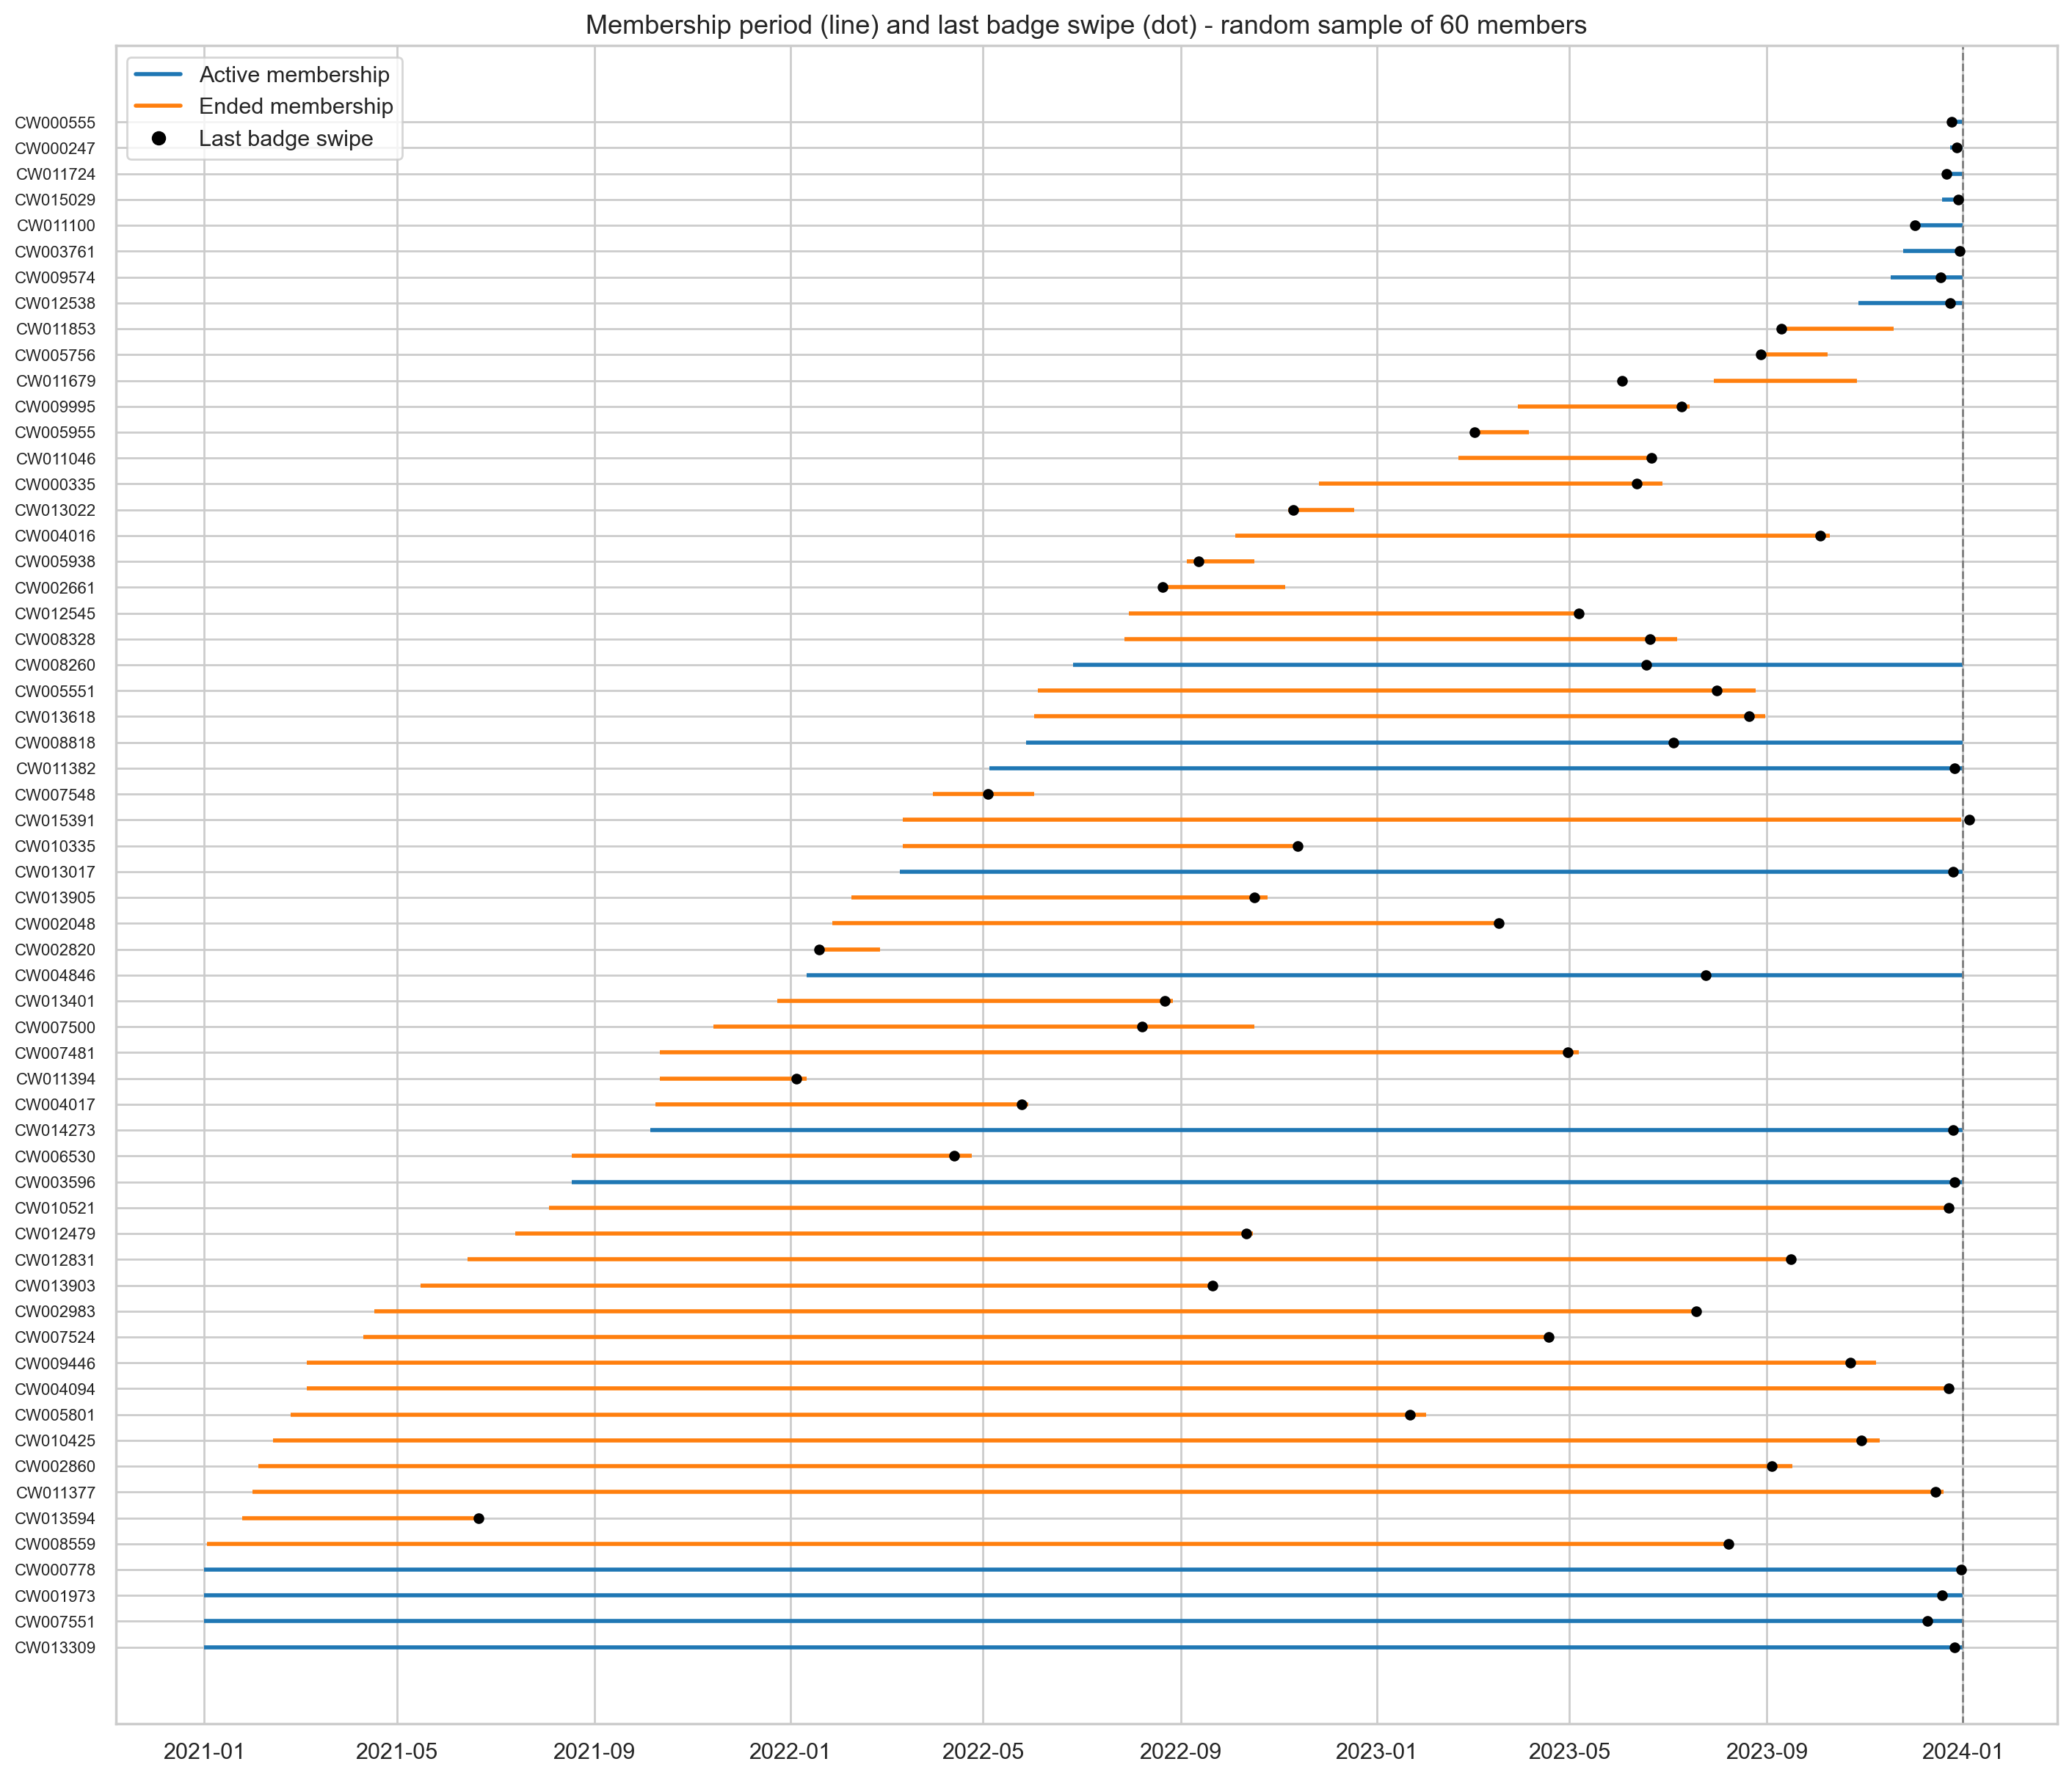

In [139]:
# Random sample of members (all 15,000 lines would overlap), ordered by start date
sample = dataset.sample(60, random_state=42).sort_values("membership_start")
membership_stop = sample["membership_end"].fillna(EXTRACTION_DATE)   # active members run until the extraction date
y = np.arange(len(sample))
colors = np.where(sample["is_active"], "tab:blue", "tab:orange")

fig, ax = plt.subplots(figsize=(14, 12), layout="constrained")

ax.hlines(y, sample["membership_start"], membership_stop, colors=colors, linewidth=2)   # membership period
ax.scatter(sample["last_badge_swipe"], y, color="black", s=18, zorder=3)                # last badge swipe
ax.axvline(EXTRACTION_DATE, color="gray", linestyle="--", linewidth=1)                  # extraction date

ax.set_yticks(y, sample.index, fontsize=8)
ax.set_title("Membership period (line) and last badge swipe (dot) - random sample of 60 members", fontsize=13)

legend = [
    Line2D([0], [0], color="tab:blue", linewidth=2, label="Active membership"),
    Line2D([0], [0], color="tab:orange", linewidth=2, label="Ended membership"),
    Line2D([0], [0], marker="o", color="black", linewidth=0, label="Last badge swipe"),
]
ax.legend(handles=legend, loc="upper left")

plt.show()

In [140]:
swipe_after_end = dataset["last_badge_swipe"] > dataset["membership_end"]
print(f"Members who swiped in after their membership ended: {swipe_after_end.sum()} ({swipe_after_end.mean():.1%})")
dataset = dataset[~swipe_after_end].copy()

Members who swiped in after their membership ended: 61 (0.4%)


**Swipes after the end of the membership.** These 61 members (0.4%) have a last badge swipe after their membership ended, which should not be possible. Keeping them and moving the swipe to the last day of the membership would also be an option, but we cannot tell which of the two dates is wrong, so we remove them. With so few members, this does not change the distributions.

In [141]:
# Badge swipes after the extraction date are impossible
future_swipe = dataset["last_badge_swipe"] > EXTRACTION_DATE
print(f"Badge swipes after the extraction date: {future_swipe.sum()} ({future_swipe.mean():.1%})")

# remove them
dataset = dataset[~future_swipe].copy()

Badge swipes after the extraction date: 27 (0.2%)


**Swipes before the start of the membership.** 93 members have their last badge swipe before their membership started. Unlike the cases above, this is not necessarily an error: the visit could have been made with a day pass before the member signed up. We keep these members.

### 3.1.4 Values in the Wrong Unit

A small group of members has values that are far too large to be real, and the pattern suggests they were recorded in a different unit. For `lifetime_value`, 77 members bring in around 100 times the typical monthly revenue of their plan, and unlike the rest of the column their values are whole numbers, which points to amounts stored in cents. For `meeting_room_hours`, the 19 values above 1,000 are all whole numbers, while normal values have decimals, so they look like minutes. We convert both back to the right unit instead of removing them.

In [142]:
# lifetime_value stored in cents: monthly value far above the plan's median and a whole number
CENTS_RATIO = 20   # a member paying 20x the usual monthly price of their plan is not a real price difference

monthly = dataset["lifetime_value"] / (dataset["tenure_days"] / DAYS_PER_MONTH)
typical = monthly.groupby(dataset["plan_tier"]).transform("median")
in_cents = (dataset["tenure_days"] >= MIN_TENURE_DAYS) & (monthly > CENTS_RATIO * typical) & (dataset["lifetime_value"] % 1 == 0)
dataset.loc[in_cents, "lifetime_value"] = dataset.loc[in_cents, "lifetime_value"] / 100
print(f"lifetime_value converted from cents: {in_cents.sum()}")

# meeting_room_hours stored in minutes: whole numbers of 1,000 or more
MINUTES_THRESHOLD = 1000   # after the conversion no value in hours comes close to this (the maximum is 921)

in_minutes = (dataset["meeting_room_hours"] >= MINUTES_THRESHOLD) & (dataset["meeting_room_hours"] % 1 == 0)
dataset.loc[in_minutes, "meeting_room_hours"] = dataset.loc[in_minutes, "meeting_room_hours"] / 60
print(f"meeting_room_hours converted from minutes: {in_minutes.sum()}")

lifetime_value converted from cents: 77
meeting_room_hours converted from minutes: 19


### 3.1.5 Negative Values

In [143]:
# Negative service amounts are sign typos: every one of these members is flagged as a user of the service
for column in ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]:
    negative = dataset[column] < 0
    print(f"{column}: {negative.sum()} negative values made positive")
    dataset.loc[negative, column] = dataset.loc[negative, column].abs()

meeting_room_hours: 16 negative values made positive
event_space_hours: 8 negative values made positive
guest_passes_issued: 7 negative values made positive


#### 3.1.5.1 Lifetime Value, Visits and Renewals

In [144]:
temp_df = dataset[["lifetime_value", "total_visits", "n_renewals"]].copy()
temp_df[(temp_df["lifetime_value"] < 0) | (temp_df["total_visits"] < 0) | (temp_df["n_renewals"] < 0)].head(10)

,lifetime_value,total_visits,n_renewals
member_id,,,
CW000024,219.41,3,-3
CW000032,9418.95,16,-1
CW000060,-793.08,-44,2
CW000251,468.96,8,-2
CW000561,7408.68,409,-1
CW000589,5668.75,69,-2
CW000636,NaN,251,-3
CW000732,344.13,9,-1
CW000785,NaN,-22,3


##### `lifetime_value`

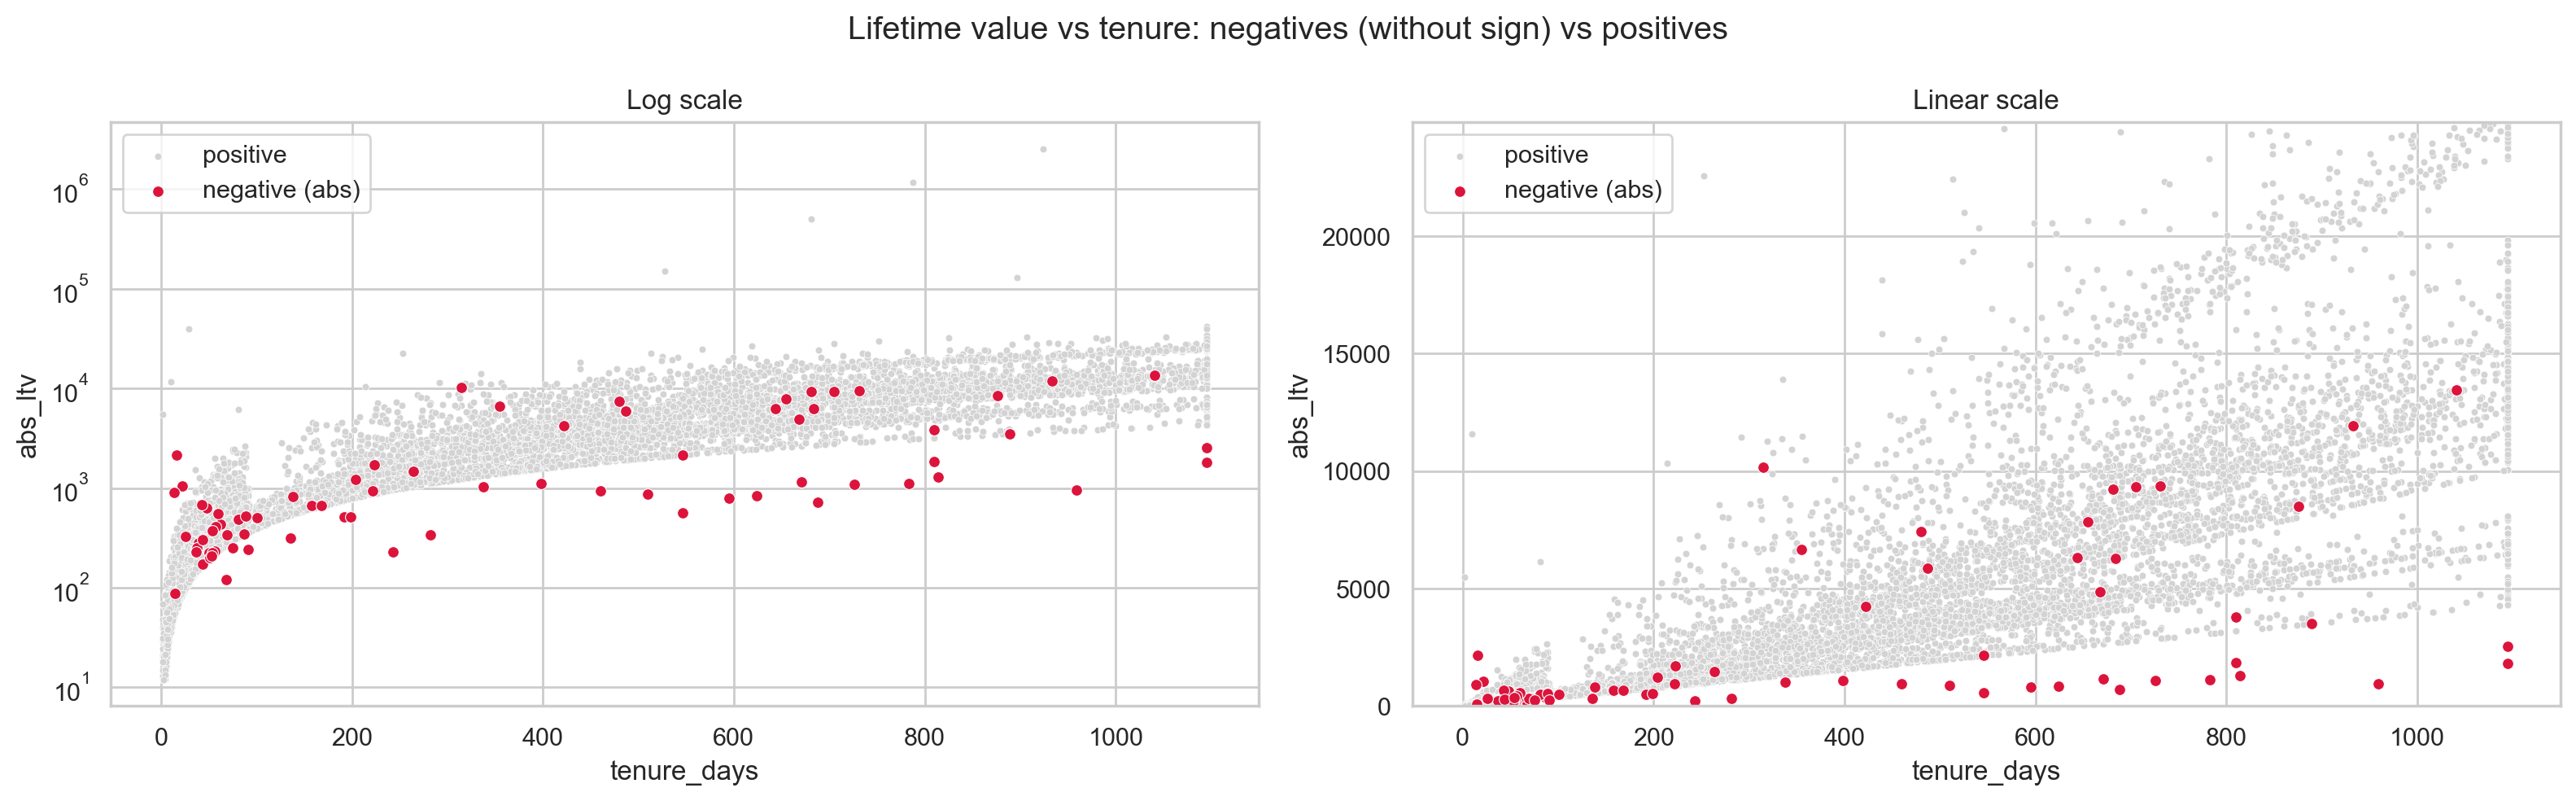

In [145]:
ltv = dataset["lifetime_value"]
plot_df = dataset.loc[ltv != 0, ["tenure_days"]].assign(
    abs_ltv=ltv.abs(),
    sign=np.where(ltv < 0, "negative (abs)", "positive"),
)
positive = plot_df[plot_df["sign"] == "positive"]
negative = plot_df[plot_df["sign"] == "negative (abs)"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, scale in zip(axes, ["log", "linear"]):
    sns.scatterplot(data=positive, x="tenure_days", y="abs_ltv",
                    color="lightgrey", s=10, label="positive", ax=ax)
    sns.scatterplot(data=negative, x="tenure_days", y="abs_ltv",
                    color="crimson", s=25, label="negative (abs)", ax=ax)
    ax.set_title(f"{scale.capitalize()} scale")

axes[0].set_yscale("log")
# Values in cents would flatten the normal-scale plot; show up to the 99th percentile
axes[1].set_ylim(0, plot_df["abs_ltv"].quantile(0.99))

fig.suptitle("Lifetime value vs tenure: negatives (without sign) vs positives")
plt.tight_layout()
plt.show()


In [146]:
negative_ltv = dataset["lifetime_value"] < 0
print("Negative lifetime values set to missing:", negative_ltv.sum())
dataset.loc[negative_ltv, "lifetime_value"] = np.nan

Negative lifetime values set to missing: 78


78 negative lifetime values were set to missing. A negative revenue is impossible, and the scatter plot above shows that removing the minus sign would not fix them either: many of these values do not match the values of other members with a similar tenure. Since neither the sign nor the size can be trusted, they are treated as missing. In preprocessing, the missing lifetime values (these and the former zeros) will be estimated from the member’s plan and tenure, since lifetime value is essentially price × time.

##### `total_visits`

In [147]:
weeks = dataset["tenure_days"] / 7
expected_visits = dataset["avg_weekly_visits"] * weeks
ratio = dataset["total_visits"].abs() / expected_visits.replace(0, np.nan)

pd.DataFrame({
    "positive": ratio[dataset["total_visits"] > 0].describe(),
    "negative (abs)": ratio[dataset["total_visits"] < 0].describe(),
})

,positive,negative (abs)
count,14848.000000,41.000000
mean,1.009478,1.163157
std,0.207001,2.835234
min,0.094340,0.071030
25%,0.992969,0.143079
50%,0.999743,0.273571
75%,1.005481,0.637704
max,9.722222,15.053763


In [148]:
negative_visits = dataset["total_visits"] < 0
print("Negative total visits set to missing:", negative_visits.sum())
dataset.loc[negative_visits, "total_visits"] = np.nan

Negative total visits set to missing: 42


Total visits above the plan maximum: 14


,plan_tier,plan_days_per_week,tenure_days,total_visits,max_possible
member_id,,,,,
CW000142,flex,3.0,405,1520.0,174.0
CW002106,flex,3.0,72,70.0,33.0
CW002369,full time,5.0,700,4750.0,500.0
CW002591,flex,3.0,390,1480.0,168.0
CW003795,full time,5.0,589,2640.0,425.0
CW004416,flex,3.0,57,170.0,27.0
CW004880,flex,3.0,585,1790.0,252.0
CW005571,hot desk,2.0,50,50.0,16.0
CW007006,hot desk,2.0,47,40.0,14.0


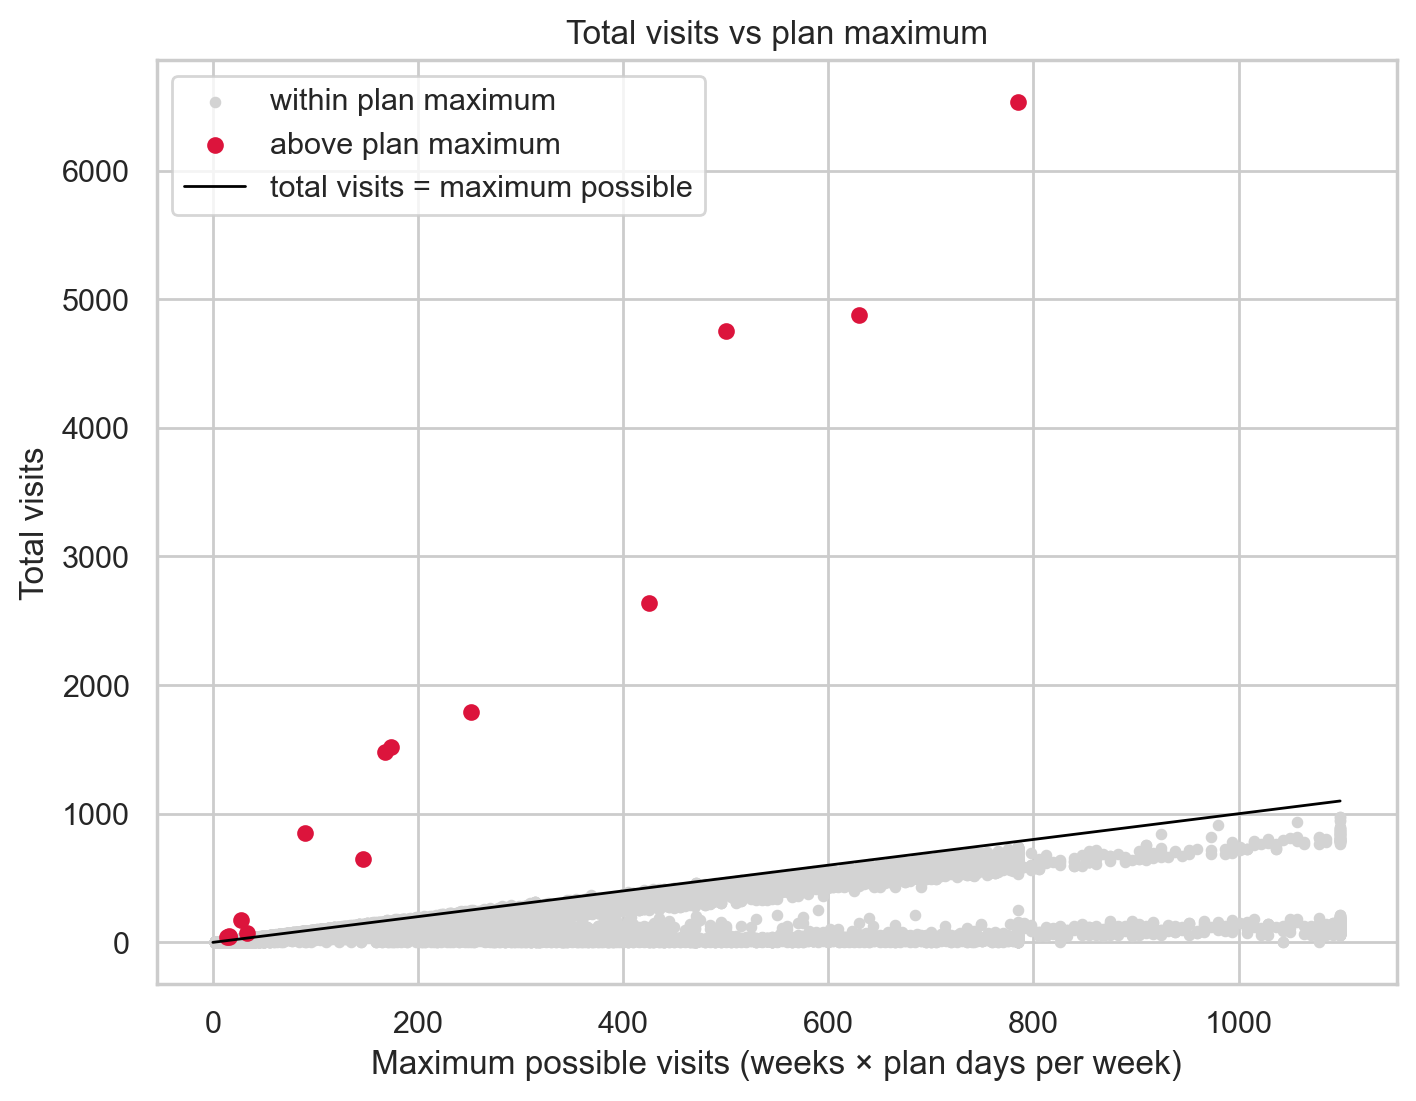

In [149]:
# Check for members whose total visits exceed the maximum possible visits based on their plan and tenure
max_possible_visits = np.ceil(dataset["tenure_days"] / 7) * dataset["plan_days_per_week"]
too_many_visits = dataset["total_visits"] > max_possible_visits

print("Total visits above the plan maximum:", too_many_visits.sum())
display(dataset.loc[too_many_visits, ["plan_tier", "plan_days_per_week", "tenure_days",
                                      "total_visits"]].assign(max_possible=max_possible_visits[too_many_visits]))

# plot total visits vs maximum possible visits, highlighting the members above the plan maximum
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(max_possible_visits[~too_many_visits], dataset.loc[~too_many_visits, "total_visits"],
           color="lightgrey", s=10, label="within plan maximum")
ax.scatter(max_possible_visits[too_many_visits], dataset.loc[too_many_visits, "total_visits"],
           color="crimson", s=25, label="above plan maximum")

# Line where total visits = maximum possible visits
limit = max_possible_visits.max()
ax.plot([0, limit], [0, limit], color="black", linewidth=1, label="total visits = maximum possible")

ax.set_xlabel("Maximum possible visits (weeks × plan days per week)")
ax.set_ylabel("Total visits")
ax.set_title("Total visits vs plan maximum")
ax.legend()
plt.show()

# Set the total visits to missing for members above the plan maximum
dataset.loc[too_many_visits, "total_visits"] = np.nan

Negative total visits (42) were set to missing because, even without the minus sign, they don't match the member's weekly average × weeks. Totals above the plan's maximum (weeks × plan days per week) are impossible and were also set to missing.

##### `n_renewals`

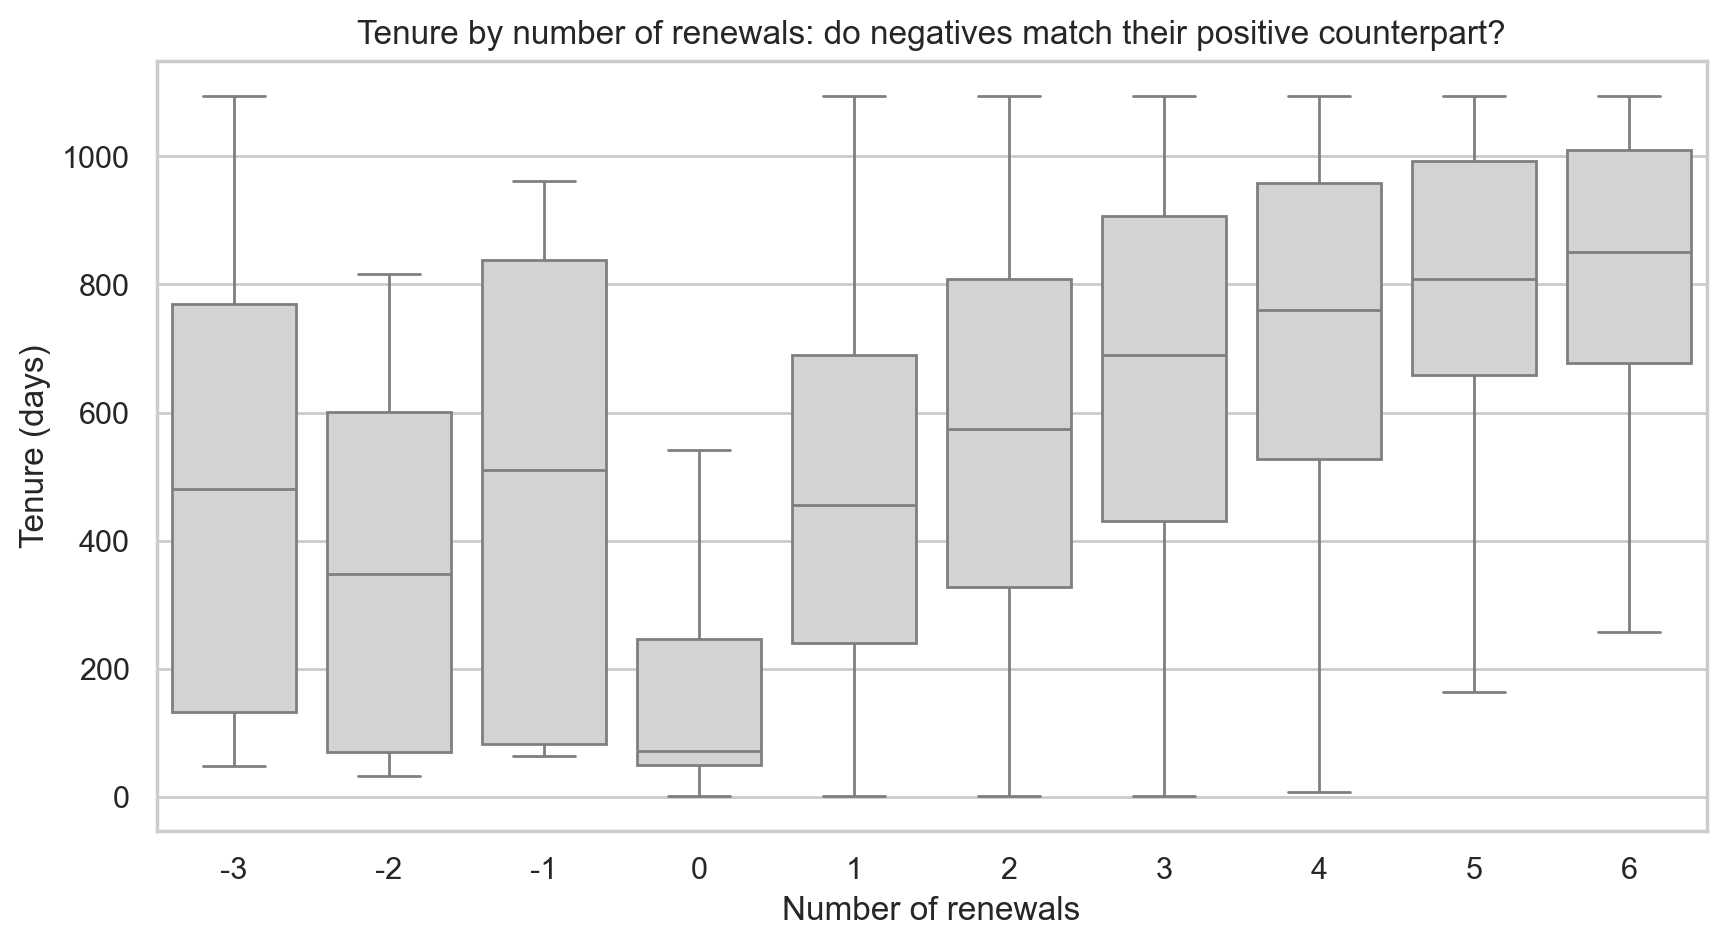

            count  median
n_renewals               
-3             27   481.0
-2             20   348.0
-1             17   510.0
 0           7550    71.0
 1           3198   455.5
 2           2128   573.5
 3           1149   690.0
 4            576   760.0
 5            237   808.0
 6            144   850.0


In [150]:
fig, ax = plt.subplots(figsize=(10, 5))
order = sorted(dataset["n_renewals"].dropna().unique())
sns.boxplot(data=dataset, x="n_renewals", y="tenure_days", order=order,
            color="lightgrey", showfliers=False, ax=ax)
ax.set_xlabel("Number of renewals")
ax.set_ylabel("Tenure (days)")
ax.set_title("Tenure by number of renewals: do negatives match their positive counterpart?")
plt.show()

print(dataset.groupby("n_renewals")["tenure_days"].agg(["count", "median"]))


In [151]:
negative_renewals = dataset["n_renewals"] < 0
print("Negative renewals set to missing:", negative_renewals.sum())
dataset.loc[negative_renewals, "n_renewals"] = np.nan
dataset["n_renewals"] = dataset["n_renewals"].astype("Int64")


Negative renewals set to missing: 64


**Decision:** there is not enough evidence that the minus sign is just a typo. For positive values, tenure grows with the number of renewals (median of 456, 574 and 690 days for 1, 2 and 3 renewals), but the negative groups show no such pattern (510, 348 and 481 days for −1, −2 and −3). The negative groups are small (17 to 27 members), so this is not proof either way, but without evidence that the value without the sign is correct, setting the 64 negative values (0.4% of members) to missing is the safer choice, and it barely affects the distributions.

### 3.1.6 Service Flags vs Amounts

In [152]:
service_columns = {
    "meeting_room_hours": "uses_meeting_rooms",
    "event_space_hours": "uses_event_space",
    "guest_passes_issued": "uses_guest_passes",
}

# A member used a service if the recorded amount is above 0 (the amounts are more specific than the flags)
for amount, flag in service_columns.items():
    recorded = dataset[amount].notna()
    inconsistent = recorded & (dataset[flag] != (dataset[amount] > 0))
    print(f"{flag}: {inconsistent.sum()} flags corrected")
    dataset.loc[recorded, flag] = dataset.loc[recorded, amount] > 0

uses_meeting_rooms: 61 flags corrected
uses_event_space: 71 flags corrected
uses_guest_passes: 121 flags corrected


61 meeting-room, 71 event-space and 121 guest-pass flags contradicted the recorded amounts, for example `uses_meeting_rooms` = False while `meeting_room_hours` > 0. The amounts are more specific than the flags, so the flags were rebuilt from them: a member used the service if the recorded amount is above 0. Where the amount is missing, the original flag is kept.

### 3.1.7 Outliers

The cleaning above dealt with values that are clearly impossible (negative hours, the `999` placeholder, ages of 140). What is left can still contain extreme values, and these need a decision before clustering: K-Means and other distance-based methods are pulled towards isolated points, so a handful of members can shift a whole centroid.

We look at this in two steps. First, each variable on its own (univariate), using boxplots and the IQR rule. Then, as an extra, members whose **combination** of values is unusual even if each value looks normal (multivariate).

#### 3.1.7.1 Univariate Outliers

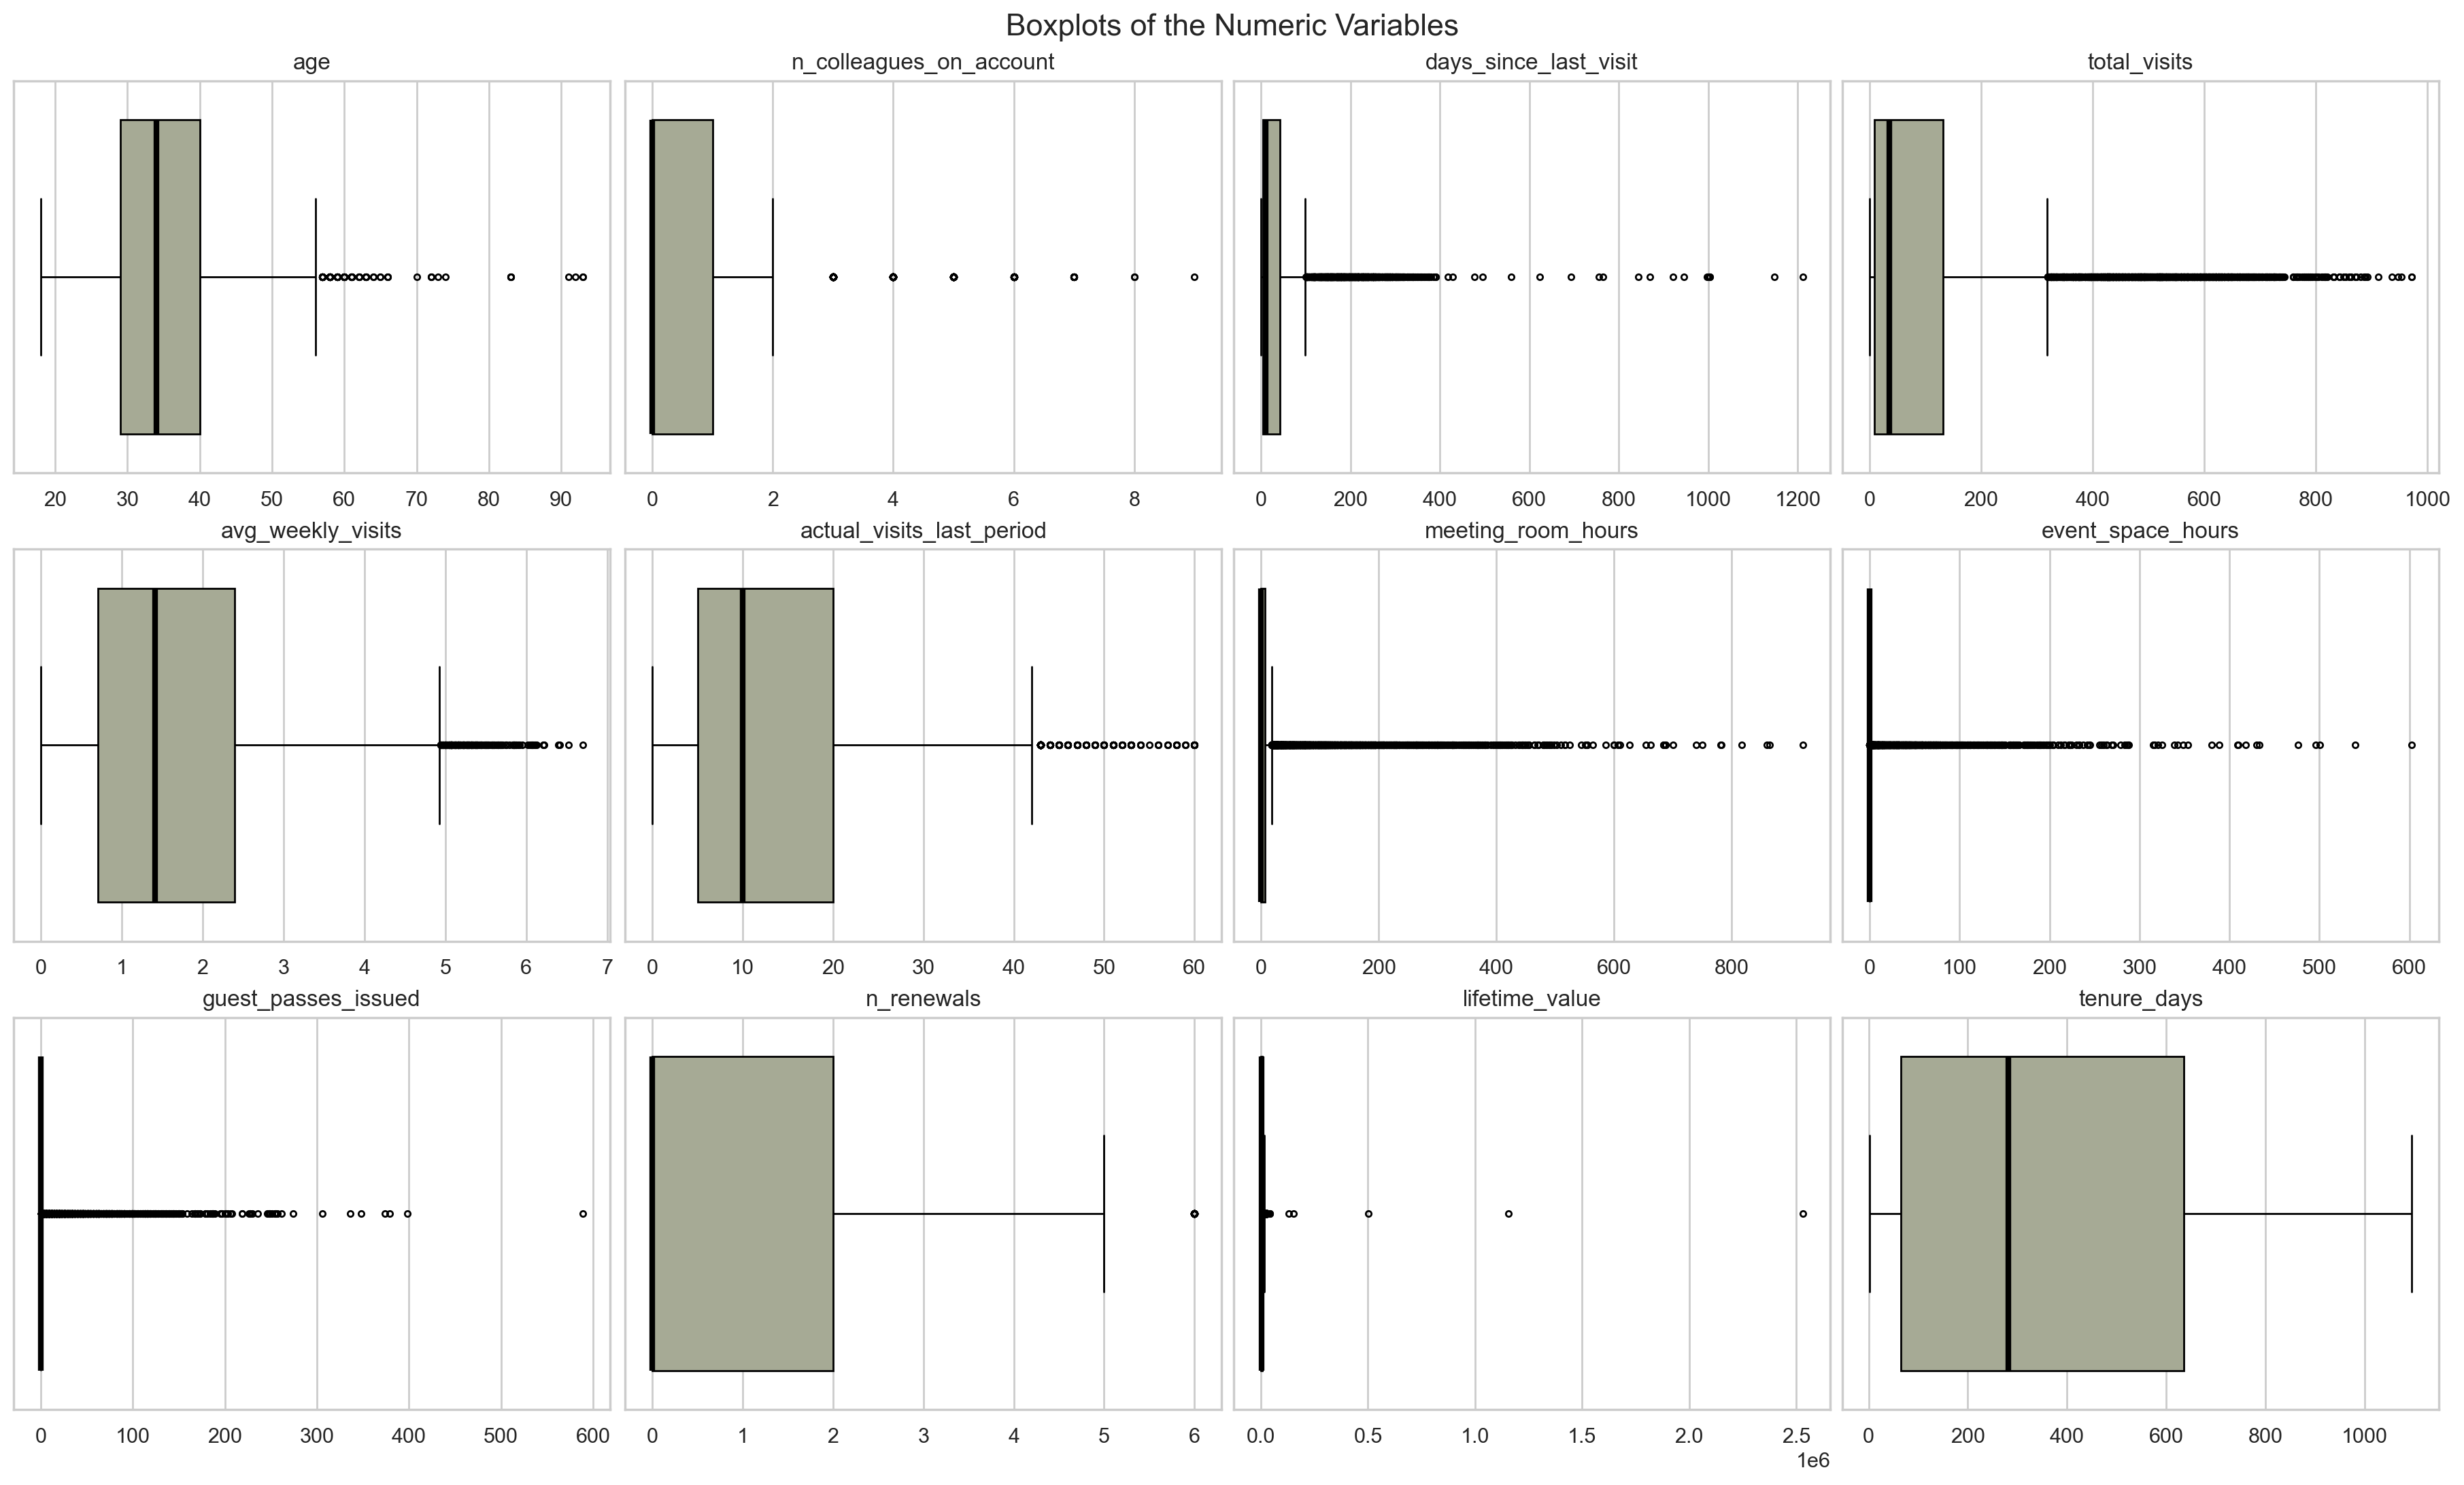

In [153]:
outlier_features = ["age", "n_colleagues_on_account", "days_since_last_visit", "total_visits", "avg_weekly_visits",
                    "actual_visits_last_period", "meeting_room_hours", "event_space_hours", "guest_passes_issued",
                    "n_renewals", "lifetime_value", "tenure_days"]

n_cols = 4
n_rows = ceil(len(outlier_features) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 3.6 * n_rows), layout="constrained")
for ax, feature in zip(axes.flatten(), outlier_features):
    sns.boxplot(x=dataset[feature], color=MAIN_COLOR, linecolor="black", linewidth=1,
                medianprops={"color": "black", "linewidth": 3}, flierprops={"markeredgecolor": "black", "markersize": 3}, ax=ax)
    ax.set_title(feature, fontsize=12)
    ax.set_xlabel("")
for ax in axes.flatten()[len(outlier_features):]:
    ax.set_visible(False)
fig.suptitle("Boxplots of the Numeric Variables", fontsize=16)
plt.show()

The standard IQR rule flags values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR. It does not work well for `meeting_room_hours`, `event_space_hours` and `guest_passes_issued`: most members have 0, so Q1 = Q3 = 0 and every member who used the service even once would count as an outlier. For these three variables the limits are computed only among the members who actually used the service.

In [154]:
# Service variables: most members never use them, so their quartiles are computed on the users only
zero_inflated = ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]

iqr_summary(dataset, outlier_features, zero_inflated)

,lower limit,upper limit,outliers,outliers (%),99th percentile,max
age,12.50,56.50,115.0,0.80,55.00,93.0
n_colleagues_on_account,-1.50,2.50,1290.0,8.90,5.00,9.0
days_since_last_visit,-53.00,99.00,1310.0,9.50,294.00,1212.0
total_visits,-178.00,318.00,1666.0,11.11,689.11,972.0
avg_weekly_visits,-1.83,4.94,269.0,1.79,5.22,6.7
actual_visits_last_period,-17.50,42.50,373.0,2.48,44.00,60.0
meeting_room_hours,-124.45,222.35,302.0,2.19,308.76,921.1
event_space_hours,-72.07,134.12,141.0,0.94,127.35,602.8
guest_passes_issued,-56.50,107.50,174.0,1.26,116.82,589.0
n_renewals,-3.00,5.00,144.0,0.96,5.00,6.0


Reading the boxplots and the table together, the flagged values fall into two groups.

**Values that cannot be real:** 5 members still have a lifetime value above 3000 € per month (up to 2.5 million €), when the most expensive plan costs around 700 €. They look like amounts in cents that the rule in 3.4 did not catch, so they are set to missing below.

**Values that are extreme but possible:** Older members (up to 93), large teams, people who have not come in for over a year and heavy users of the services. These are real customers, and the heavy users may even form a segment of their own, so they are kept.

In [155]:
# lifetime_value above 3,000 € per month of membership
# (the most expensive plan, private office, has a median of about 700 € per month; negative values were handled in 3.1.5)
MAX_MONTHLY_VALUE = 3000   # more than four times the price of the most expensive plan

monthly_value = dataset["lifetime_value"] / (dataset["tenure_days"] / DAYS_PER_MONTH)
excessive_ltv = (dataset["tenure_days"] >= MIN_TENURE_DAYS) & (monthly_value > MAX_MONTHLY_VALUE)
print(f"lifetime_value above {MAX_MONTHLY_VALUE:,} € per month: {excessive_ltv.sum()} (highest: {dataset.loc[excessive_ltv, 'lifetime_value'].max():,.0f} €)")
dataset.loc[excessive_ltv, "lifetime_value"] = np.nan

lifetime_value above 3,000 € per month: 5 (highest: 2,532,335 €)


In [156]:
# Same summary after the corrections
iqr_summary(dataset, outlier_features, zero_inflated)

,lower limit,upper limit,outliers,outliers (%),99th percentile,max
age,12.50,56.50,115.0,0.80,55.00,93.00
n_colleagues_on_account,-1.50,2.50,1290.0,8.90,5.00,9.00
days_since_last_visit,-53.00,99.00,1310.0,9.50,294.00,1212.00
total_visits,-178.00,318.00,1666.0,11.11,689.11,972.00
avg_weekly_visits,-1.83,4.94,269.0,1.79,5.22,6.70
actual_visits_last_period,-17.50,42.50,373.0,2.48,44.00,60.00
meeting_room_hours,-124.45,222.35,302.0,2.19,308.76,921.10
event_space_hours,-72.07,134.12,141.0,0.94,127.35,602.80
guest_passes_issued,-56.50,107.50,174.0,1.26,116.82,589.00
n_renewals,-3.00,5.00,144.0,0.96,5.00,6.00


**Decisions for the univariate outliers:**

| Variable | Decision | Reason |
|---|---|---|
| `lifetime_value` | Set to missing for 5 members | More than 3,000 € per month of membership, over four times the price of the most expensive plan. Probably amounts in cents that 3.1.4 did not catch |
| `total_visits` | Already handled in 3.1.5 | Negative totals and totals above the plan maximum were set to missing |
| `event_space_hours`, `guest_passes_issued`, `meeting_room_hours` | Kept | Plausible heavy users. Their skewness will be reduced with a log transformation before clustering |
| `age`, `n_colleagues_on_account`, `days_since_last_visit`, `avg_weekly_visits`, `actual_visits_last_period`, `n_renewals` | Kept | Within realistic limits |

The 5 lifetime values set to missing will be imputed together with the other missing values. If the rule in 3.1.4 is extended to members without a plan and to amounts that are not whole numbers, they could be converted instead.

#### 3.1.7.2 Multivariate Outliers (Extra)

This part corresponds to the optional component Multidimensional Outlier & Anomaly Detection.

A member can have reasonable values in every column and still be very different from everyone else, for example a hot desk member with the add-on usage of a private office. The univariate checks cannot see this. We use two methods that look at all the variables together:

- **Isolation Forest** builds random splits of the data and measures how quickly each member gets isolated. Unusual members are separated after very few splits.
- **Local Outlier Factor (LOF)** compares the density around each member with the density around their nearest neighbours. Members in much emptier regions than their neighbours get a high score.

Because they work in different ways, comparing them also tells us whether there is one kind of unusual member or several. Both are set to flag about 2% of the members.

In [157]:
multi_features = ["avg_weekly_visits", "days_since_last_visit", "tenure_days", "plan_days_per_week", "n_colleagues_on_account",
                  "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
skewed_features = ["days_since_last_visit", "tenure_days", "meeting_room_hours", "event_space_hours", "guest_passes_issued", "lifetime_value"]

# Preparation used only for the detection (the dataset itself is not changed):
# missing values filled with the median, skewed variables on a log scale, everything standardised
X_multi = dataset[multi_features].copy()
X_multi["n_renewals"] = X_multi["n_renewals"].clip(lower=0)
X_multi = X_multi.fillna(X_multi.median())
X_multi[skewed_features] = np.log1p(X_multi[skewed_features])
X_multi = StandardScaler().fit_transform(X_multi)

iso_flag = IsolationForest(contamination=0.02, random_state=42).fit_predict(X_multi) == -1
lof_flag = LocalOutlierFactor(n_neighbors=35, contamination=0.02).fit_predict(X_multi) == -1

agreement = pd.crosstab(pd.Series(iso_flag, name="Isolation Forest"), pd.Series(lof_flag, name="LOF"))
print(f"Flagged by Isolation Forest: {iso_flag.sum()}  |  by LOF: {lof_flag.sum()}  |  by both: {(iso_flag & lof_flag).sum()}")
agreement

Flagged by Isolation Forest: 301  |  by LOF: 301  |  by both: 1


LOF,False,True
Isolation Forest,,
False,14445,300
True,300,1


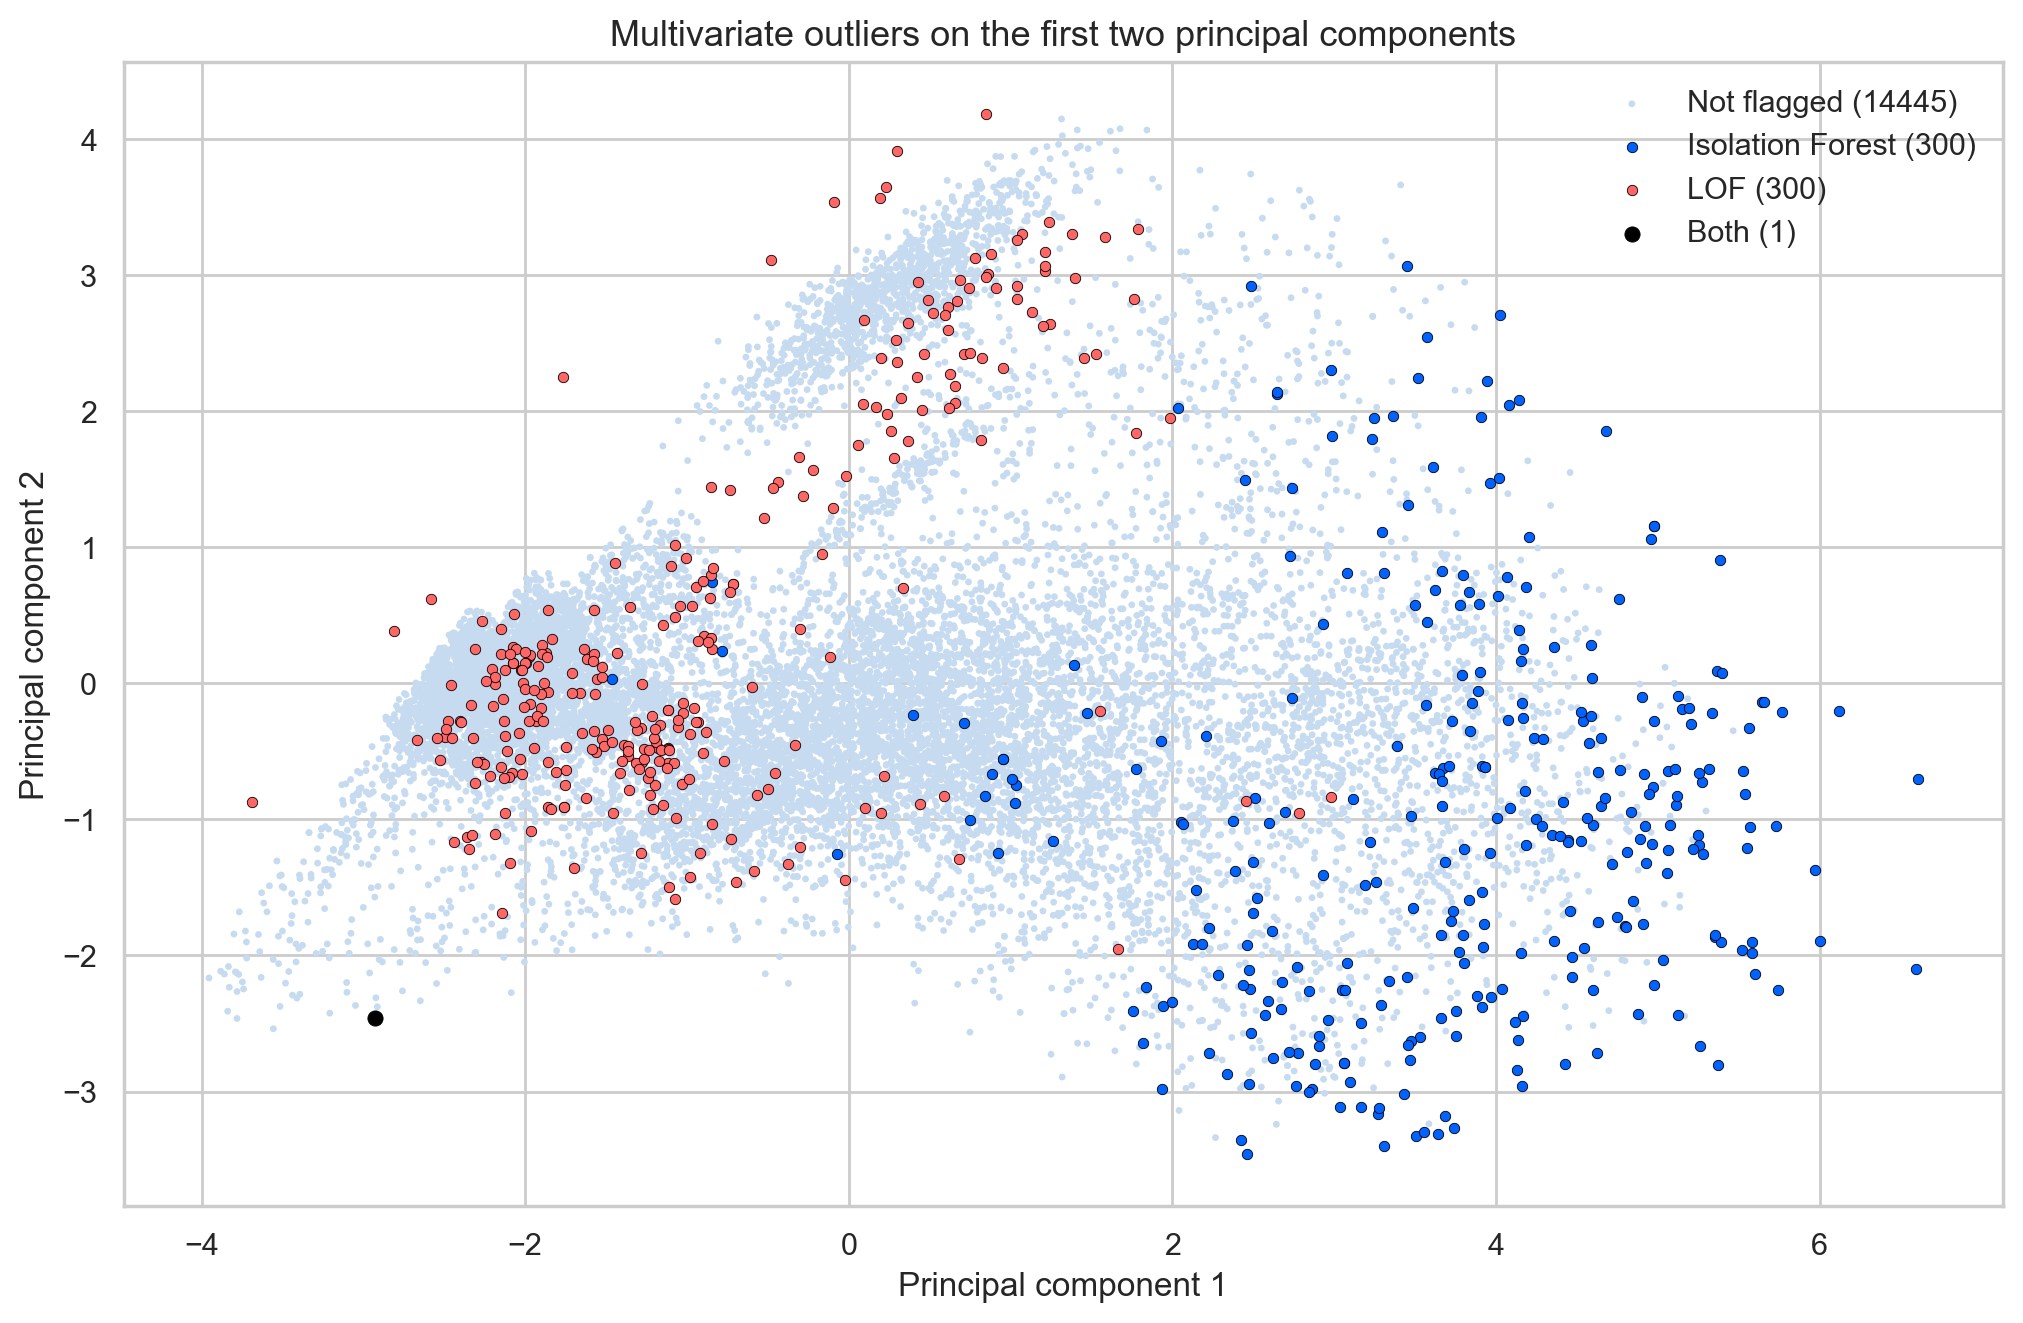

In [158]:
# Where the flagged members sit, on the first two principal components of the same data
pca_coords = PCA(n_components=2, random_state=42).fit_transform(X_multi)
groups = {
    "Not flagged": (~iso_flag & ~lof_flag, "#c6dbef", 6),
    "Isolation Forest": (iso_flag & ~lof_flag, "#0062FF", 14),
    "LOF": (lof_flag & ~iso_flag, "#ff6666", 14),
    "Both": (iso_flag & lof_flag, "black", 30),
}

fig, ax = plt.subplots(figsize=(10, 6.5), layout="constrained")
for label, (mask_group, color, size) in groups.items():
    ax.scatter(pca_coords[mask_group, 0], pca_coords[mask_group, 1], s=size, color=color,
               edgecolors="black" if label != "Not flagged" else "none", linewidths=0.3, label=f"{label} ({mask_group.sum()})")
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("Multivariate outliers on the first two principal components", fontsize=13)
ax.legend(frameon=False)
plt.show()

In [159]:
# Keep both flags in the dataset (no rows are removed here)
dataset["outlier_iforest"] = iso_flag
dataset["outlier_lof"] = lof_flag
not_flagged = ~iso_flag & ~lof_flag

# Median profile of each group
pd.DataFrame({
    "Not flagged": dataset.loc[not_flagged, multi_features].median(),
    "Isolation Forest": dataset.loc[iso_flag, multi_features].median(),
    "LOF": dataset.loc[lof_flag, multi_features].median(),
}).round(2)

,Not flagged,Isolation Forest,LOF
avg_weekly_visits,1.43,3.9,0.78
days_since_last_visit,10.0,4.0,54.0
tenure_days,278.0,801.0,72.0
plan_days_per_week,3.0,7.0,3.0
n_colleagues_on_account,0.0,1.0,0.0
meeting_room_hours,0.0,82.85,0.0
event_space_hours,0.0,29.5,0.0
guest_passes_issued,0.0,39.0,0.0
n_renewals,0.0,2.0,0.0
lifetime_value,1566.65,17950.26,550.5


In [160]:
# Plan mix and share of active members in each group (%)
outlier_group = pd.Series(np.select([iso_flag, lof_flag], ["Isolation Forest", "LOF"], "Not flagged"), index=dataset.index, name="group")
plan_mix = pd.crosstab(outlier_group, dataset["plan_tier"], normalize="index").mul(100).round(1)
plan_mix["active (%)"] = dataset.groupby(outlier_group)["is_active"].mean().mul(100).round(1)
plan_mix

plan_tier,dedicated desk,flex,full time,hot desk,private office,active (%)
group,,,,,,
Isolation Forest,11.2,11.9,10.1,18.5,48.3,26.6
LOF,8.4,26.1,17.4,46.2,2.0,44.0
Not flagged,10.1,36.3,16.1,34.0,3.5,25.4


The two methods barely agree: each flags about 300 members, but only one member is flagged by both. They are picking up two different kinds of unusual member.

**Isolation Forest** flags the global extremes: members who have stayed much longer than average (median around 800 days), visit often, and use meeting rooms, event space and guest passes far more than anyone else. Almost half of them are on a private office plan and their median lifetime value is about 18000 €. These are not errors. They look like the most engaged and valuable members ACDC has.

**LOF** flags members who are unusual compared with their close neighbours rather than with the whole base. They are mostly on hot desk and flex, with short memberships (median of about 70 days) and low value, and many of them are still active but have not visited for several weeks. Their profile is less clear-cut, which is typical of LOF, and it suggests odd combinations of values rather than one coherent group.

**How we plan to handle them in the clustering:**

- **Isolation Forest group:** kept in the data. Excluding them would remove the high-value end of the customer base, which is exactly what a value-based segmentation needs to see. Using log-transformed variables should stop them from dominating the distances. If they still pull the centroids, we will fit the clusters without them and assign them to the nearest cluster afterwards, or analyse them as a separate premium group.
- **LOF group:** kept, but checked before clustering, as some of these combinations may come from data issues that the cleaning has not caught yet. One example worth checking is the 224 members who renewed at least once despite having less than 30 days of membership.
- **Member flagged by both:** reviewed individually.

Both flags (`outlier_iforest` and `outlier_lof`) are kept as columns so these decisions can be revisited in Delivery 2. No members were removed in this step.

### 3.1.8 Cleaning Summary

This section only identifies and removes problems. Missing values, whether they were already missing or were created by the cleaning, are **not** filled in here. That is part of the preprocessing stage in Delivery 2, where all of them will be handled together and with the same method.

In [161]:
# Rows before and after the cleaning
print(f"Rows in the original file:          {n_rows_original}")
print(f"Rows after removing duplicates:     {len(dataset_raw)}")
print(f"Rows after the cleaning:            {len(dataset)}")
print(f"Rows removed by the cleaning:       {len(dataset_raw) - len(dataset)} ({(len(dataset_raw) - len(dataset)) / len(dataset_raw):.1%})")

Rows in the original file:          15465
Rows after removing duplicates:     15283
Rows after the cleaning:            15046
Rows removed by the cleaning:       237 (1.6%)


In [162]:
# Missing values per column after the cleaning
# (an empty membership_end means the membership is still active, so it is not a missing value)
missing_after = pd.DataFrame({
    "Missing before cleaning": dataset_raw.isna().sum(),
    "Missing after cleaning": dataset.isna().sum(),
}).drop(index="membership_end")
missing_after["Missing after cleaning (%)"] = (missing_after["Missing after cleaning"] / len(dataset) * 100).round(2)
missing_after = missing_after[missing_after["Missing after cleaning"] > 0].sort_values("Missing after cleaning", ascending=False)
missing_after

,Missing before cleaning,Missing after cleaning,Missing after cleaning (%)
lifetime_value,1028.0,2778,18.46
days_since_last_visit,0.0,1258,8.36
meeting_room_hours,1281.0,1258,8.36
guest_passes_issued,1256.0,1227,8.15
age,549.0,678,4.51
industry,0.0,671,4.46
n_colleagues_on_account,0.0,555,3.69
gender,524.0,509,3.38
country,424.0,413,2.74
plan_tier,103.0,99,0.66


**Actions taken in the cleaning:**

| Step | Action |
|---|---|
| 2.4 | Duplicate rows removed |
| 2.5 | Dates read with explicit formats, `uses_print` as boolean, `lifetime_value` as number, one spelling per category |
| 3.1.1 | `is_active` created from the `1970-01-01` end date, which is then left empty |
| 3.1.2 | Impossible ages, the `999` and `-1` placeholders, invalid plan days, `unknown` industry, negative days since last visit, more than 7 weekly visits and zero lifetime values set to missing |
| 3.1.3 | Memberships ending before they start, badge swipes after the end of the membership and badge swipes after the extraction date removed |
| 3.1.4 | 77 lifetime values stored in cents divided by 100, and 19 meeting-room values stored in minutes divided by 60 |
| 3.1.5 | Negative service amounts made positive; negative lifetime values, negative or impossible total visits and negative renewals set to missing |
| 3.1.6 | Service flags corrected to match the recorded amounts |
| 3.1.7 | 5 lifetime values above 3,000 € per month set to missing; multivariate outliers flagged, not removed |

**What is left for Preprocessing:**

- Impute the missing values in the table above.
- Some of them can be recovered exactly instead of estimated, because the variables are linked: `plan_days_per_week` follows directly from `plan_tier` (and the other way round for 2, 3 and 7 days), members without a team account have 0 colleagues, `days_since_last_visit` equals the end of the membership (or the extraction date) minus the last badge swipe, and `total_visits` is close to `avg_weekly_visits` × weeks of membership.
- The rest can be estimated, for example with the median or KNN within each plan, since value and usage depend strongly on the plan.
- Log-transform the skewed variables, scale the data and encode the categorical variables before clustering.

## 3.2 Exploration of the Clean Data

### 3.2.1 Visualisations After Cleaning

The same charts as before, now run on the cleaned data. The placeholders, negative values and wrong units are gone from the histograms (for example, `age` now only covers 18 to 93 and `meeting_room_hours` stops at 921 hours), but the relationships barely change: the plan medians, the share of active members per plan, the utilisation groups and the share of dormant active members (33%) are almost identical to those in section 2.6.2. The conclusions drawn there on the raw data therefore also hold for the clean data.

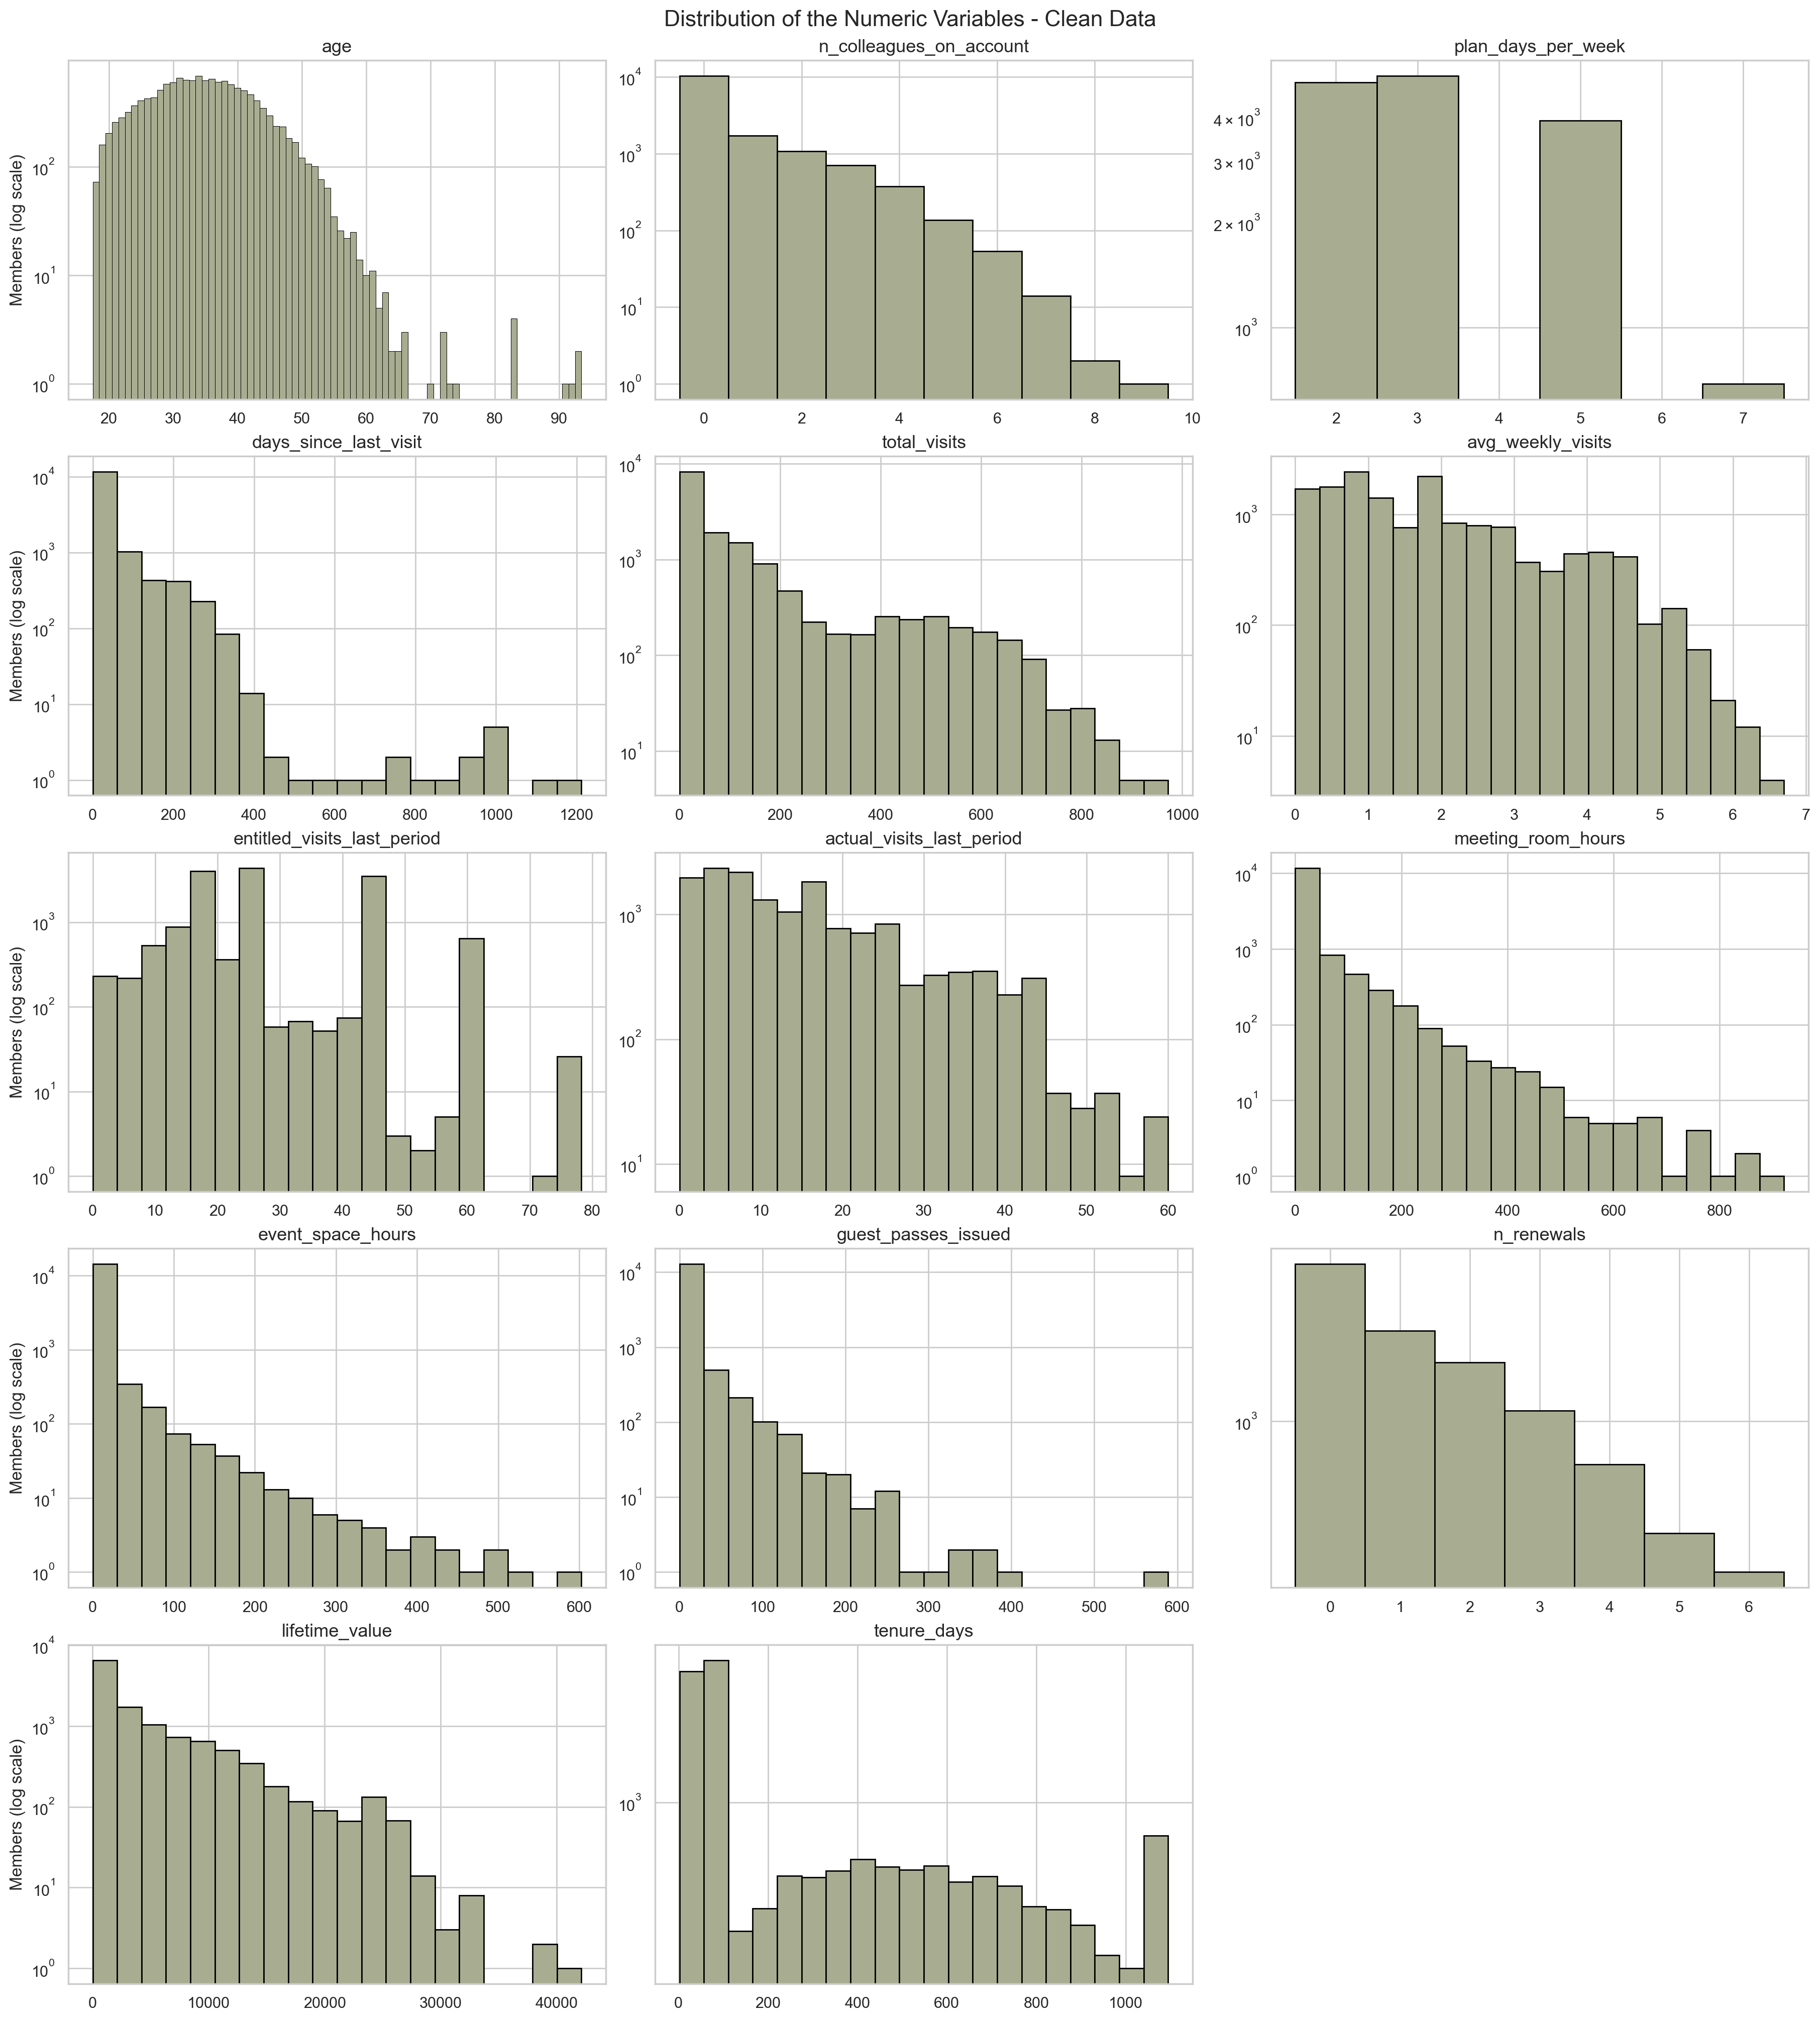

In [163]:
plot_histograms(dataset, numeric_features + ["lifetime_value", "tenure_days"], "Distribution of the Numeric Variables - Clean Data",
                discrete_features=["age", "n_colleagues_on_account", "plan_days_per_week", "n_renewals"])

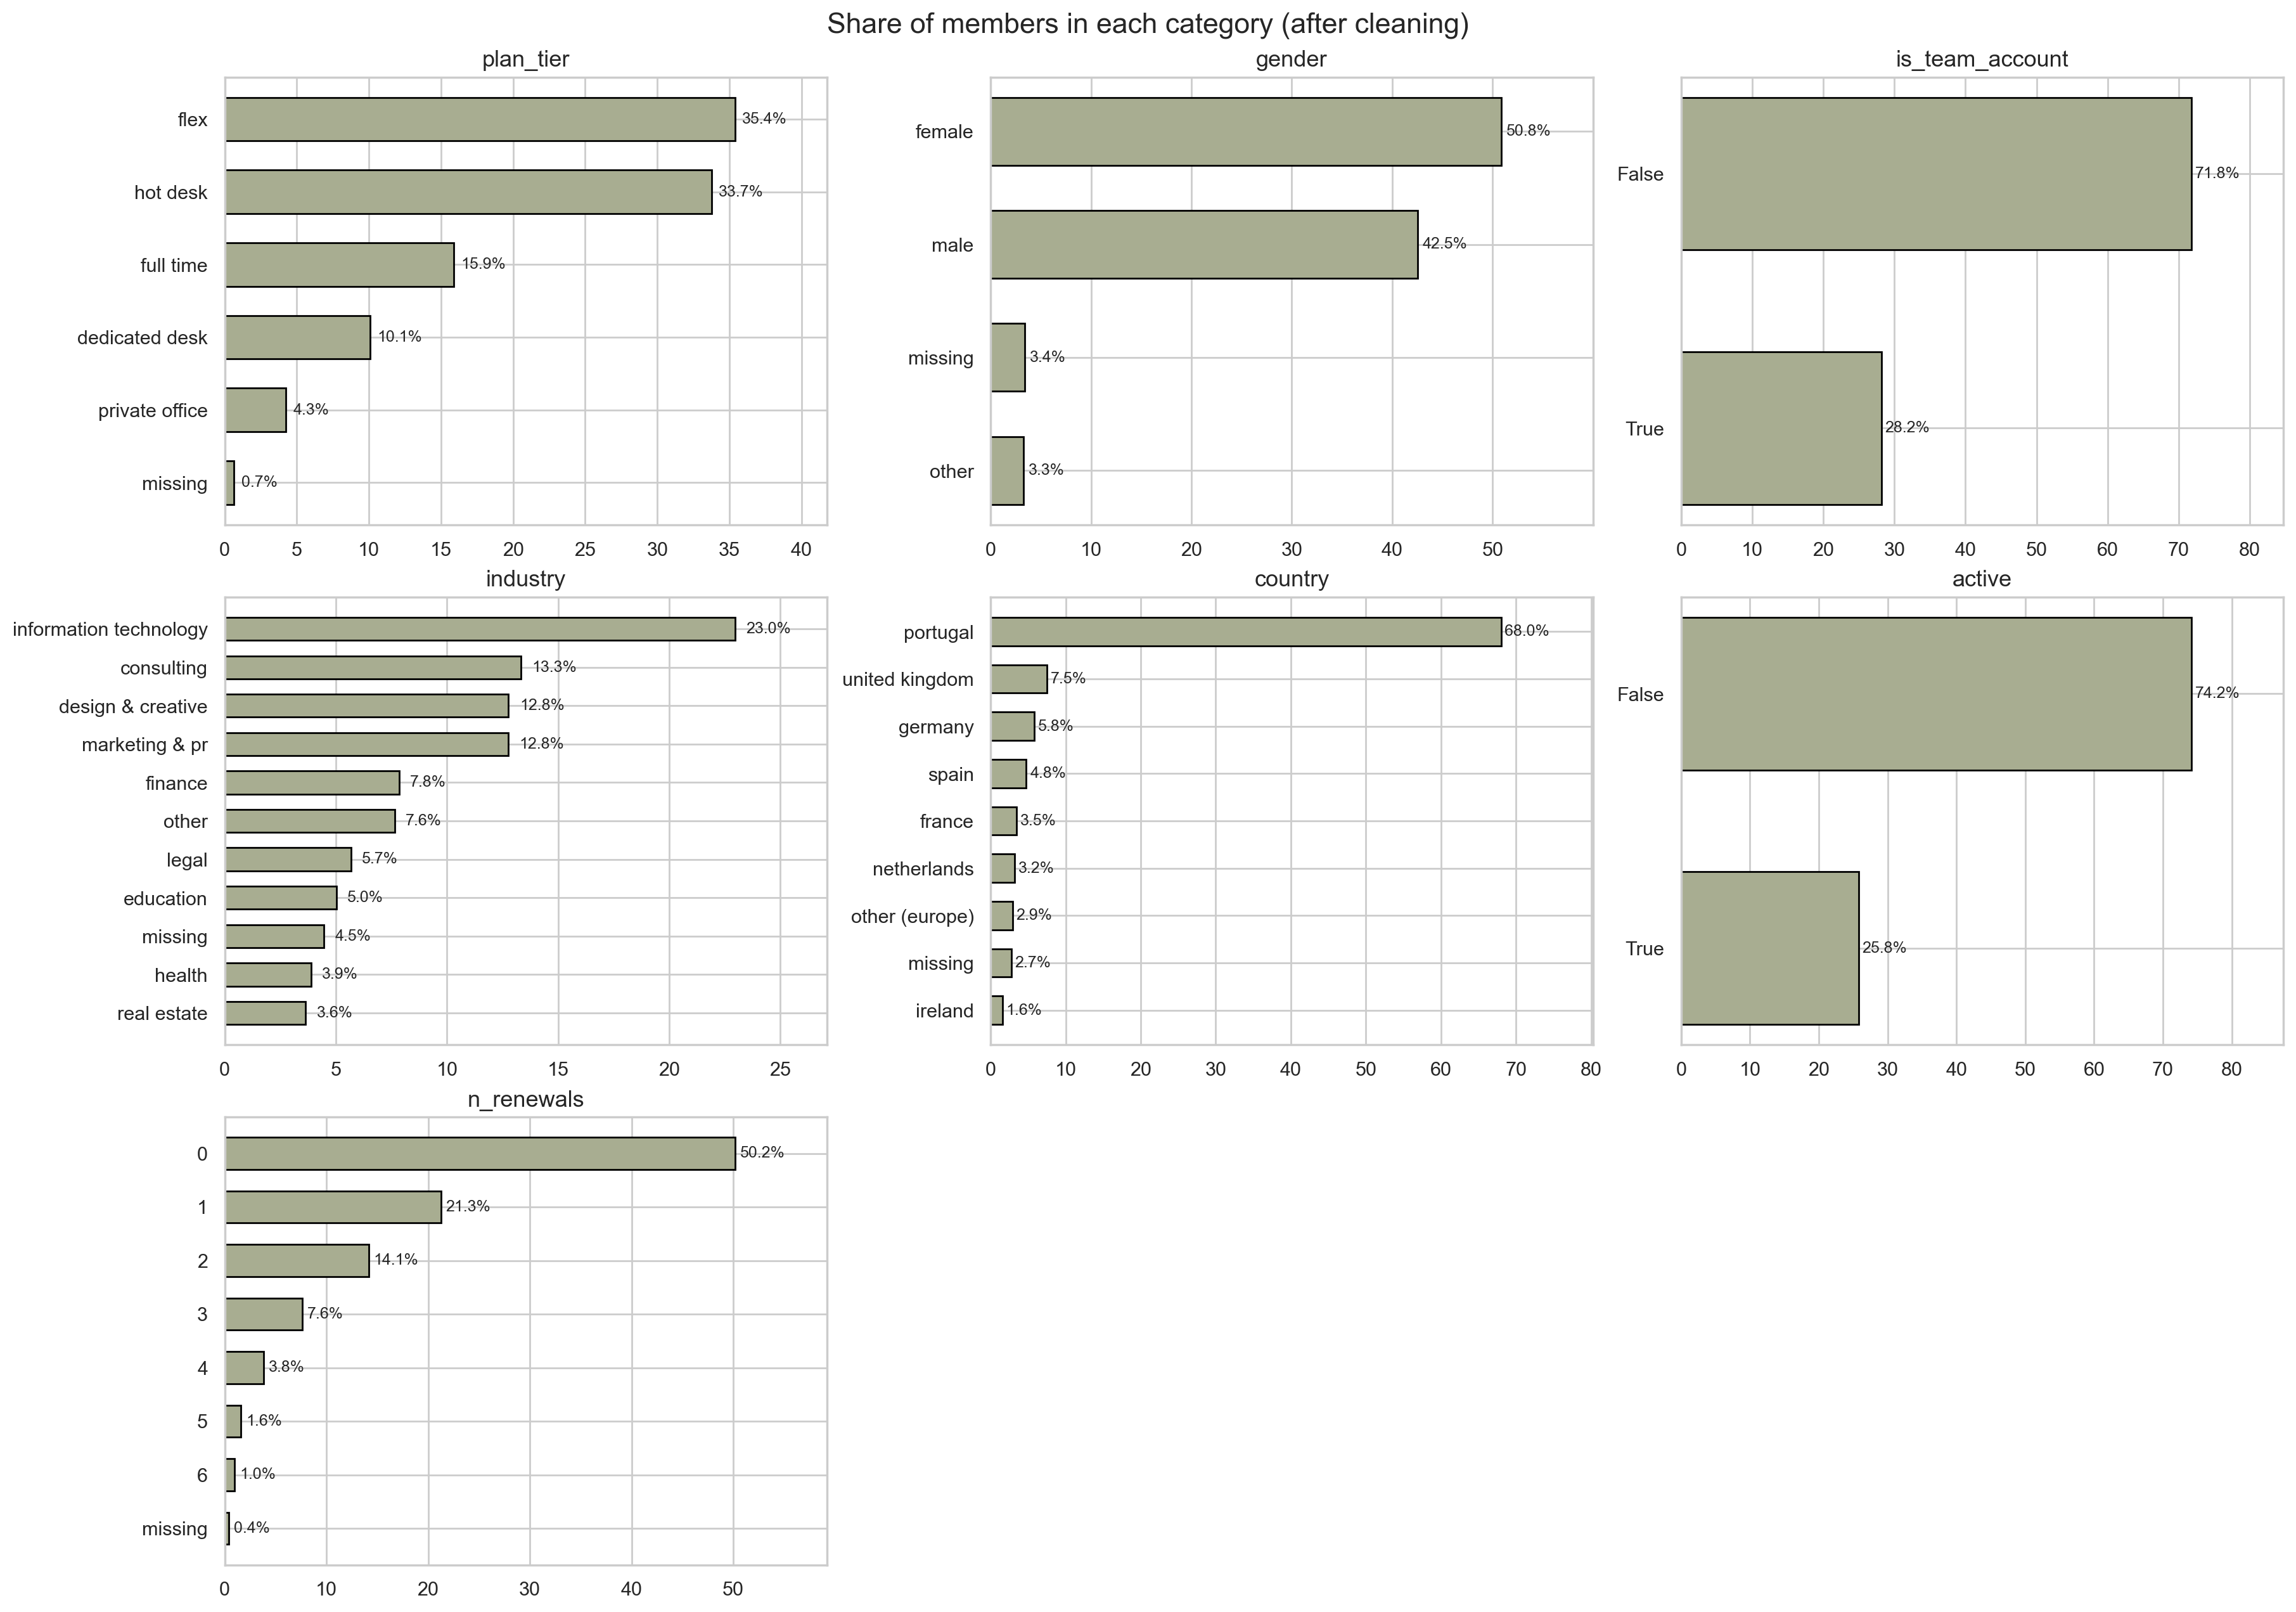

In [164]:
eda_after = chart_view(dataset)
plot_category_shares(eda_after, ["plan_tier", "gender", "is_team_account", "industry", "country", "active", "n_renewals"],
                     "Share of members in each category (after cleaning)")

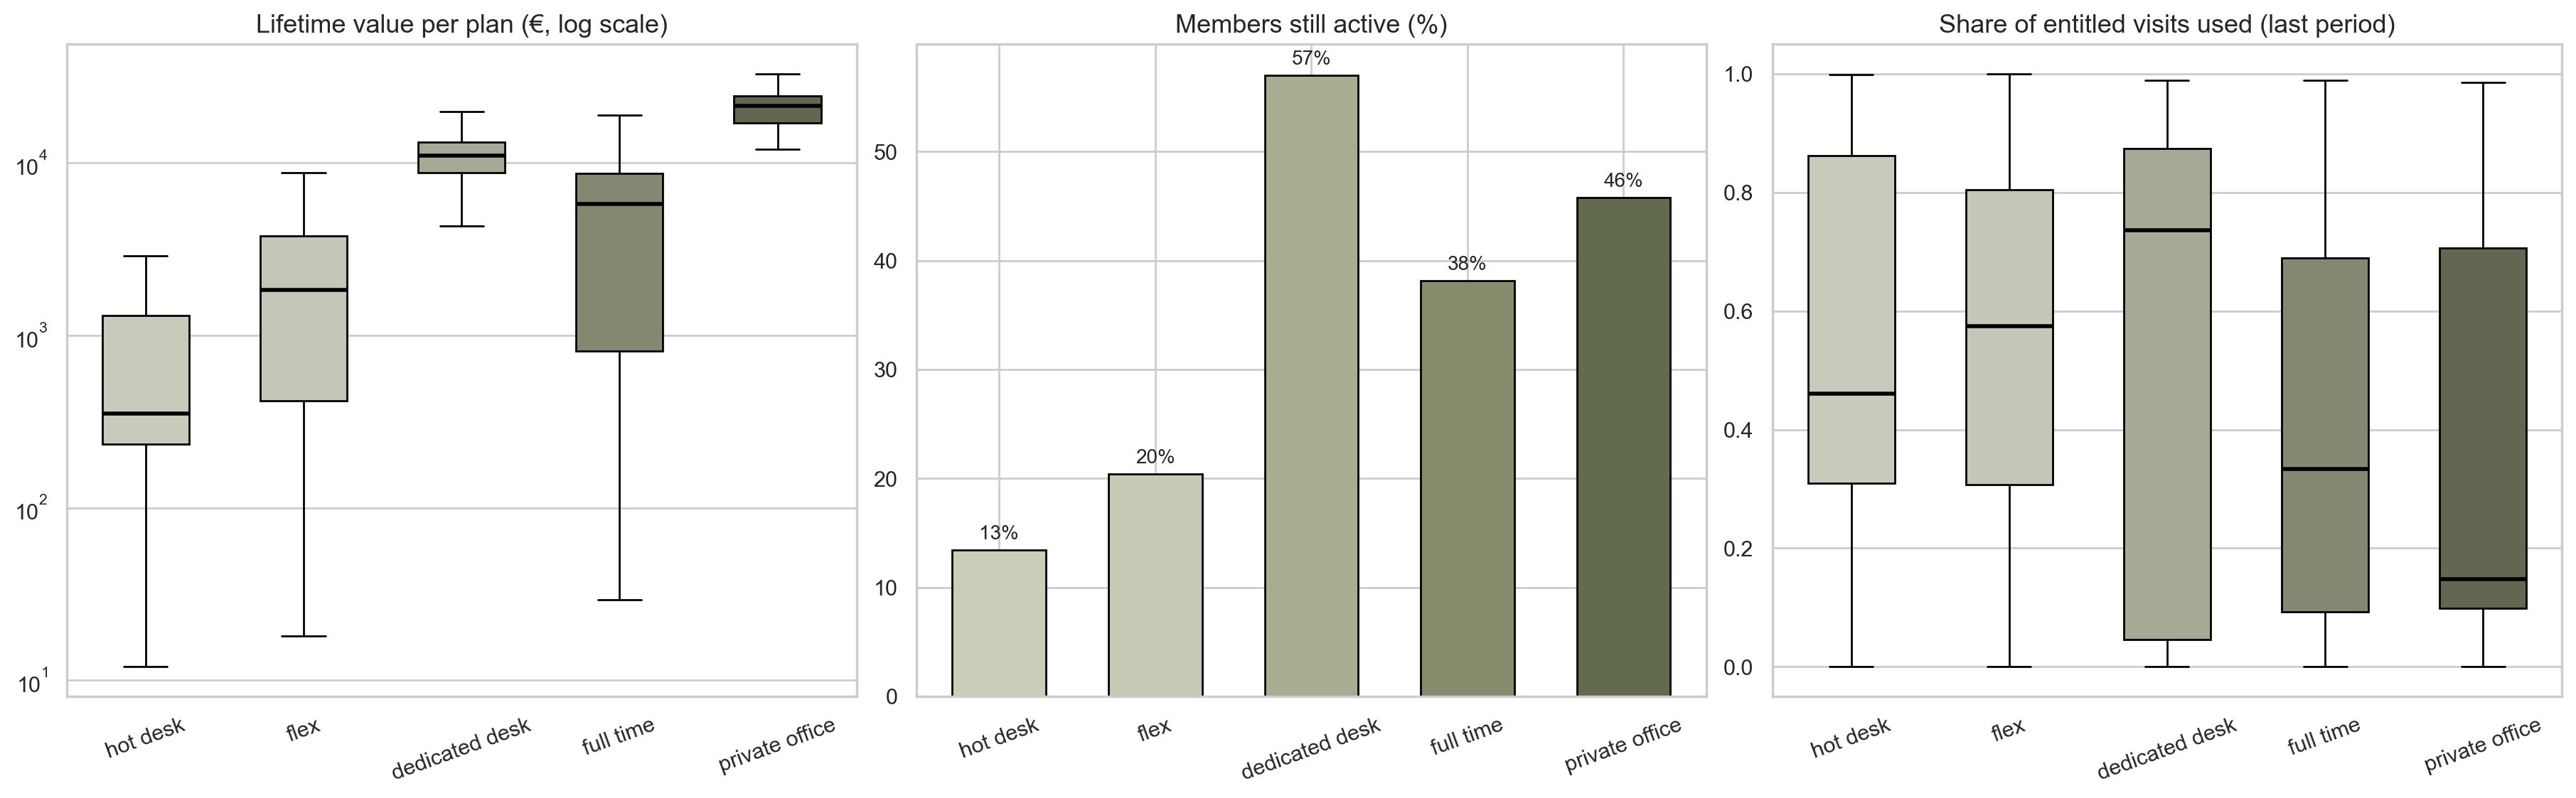

,members,median_lifetime_value,active_pct,median_utilisation,median_renewals
plan_tier,,,,,
hot desk,5078,353.15,13.43,0.46,0
flex,5325,1840.16,20.43,0.57,0
dedicated desk,1514,11034.82,57.00,0.74,2
full time,2390,5812.08,38.16,0.33,1
private office,640,21380.98,45.78,0.15,2


In [165]:
plot_plan_overview(eda_after)

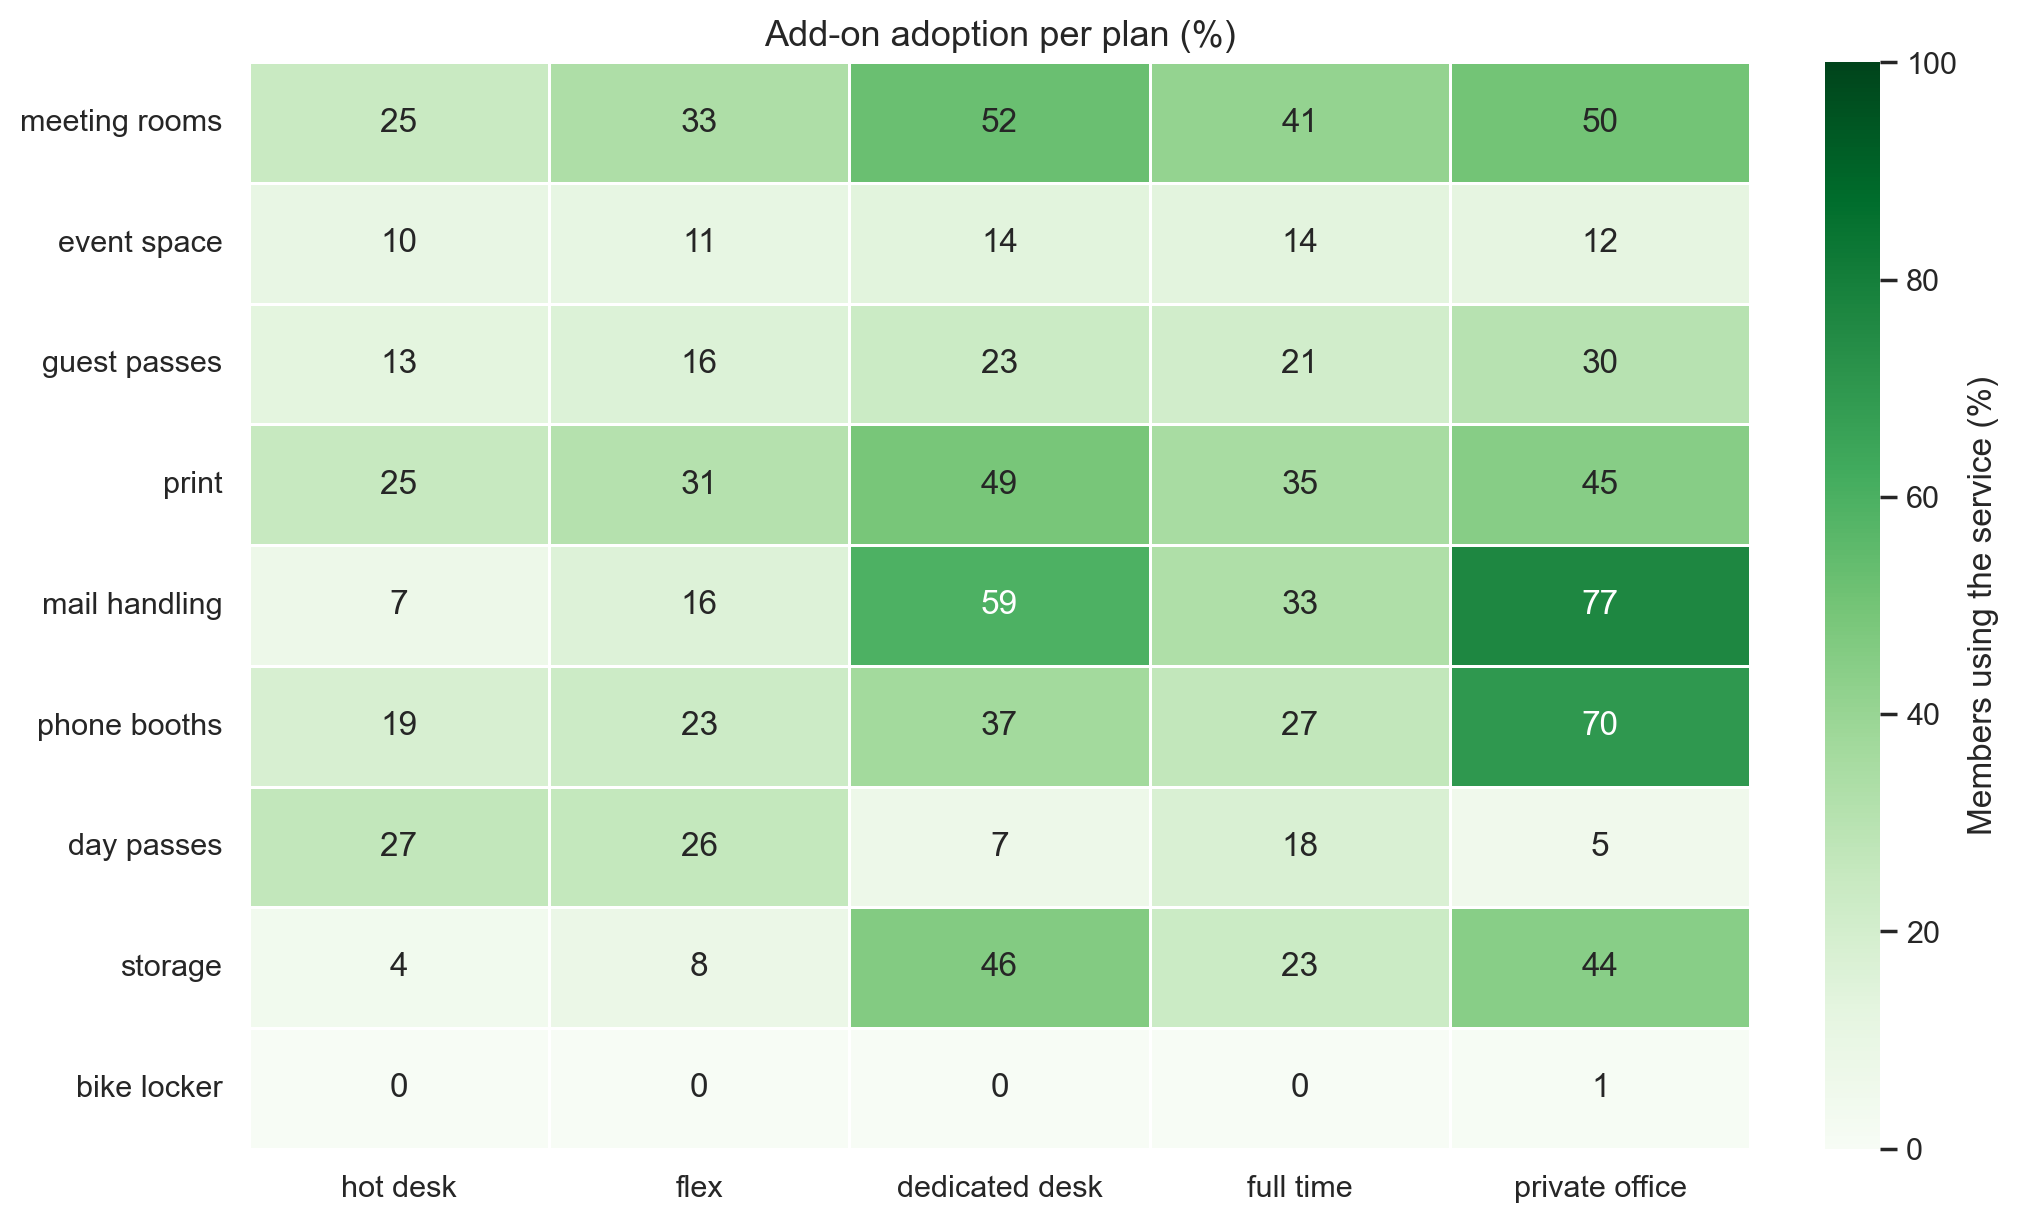

In [166]:
plot_addons_by_plan(eda_after)

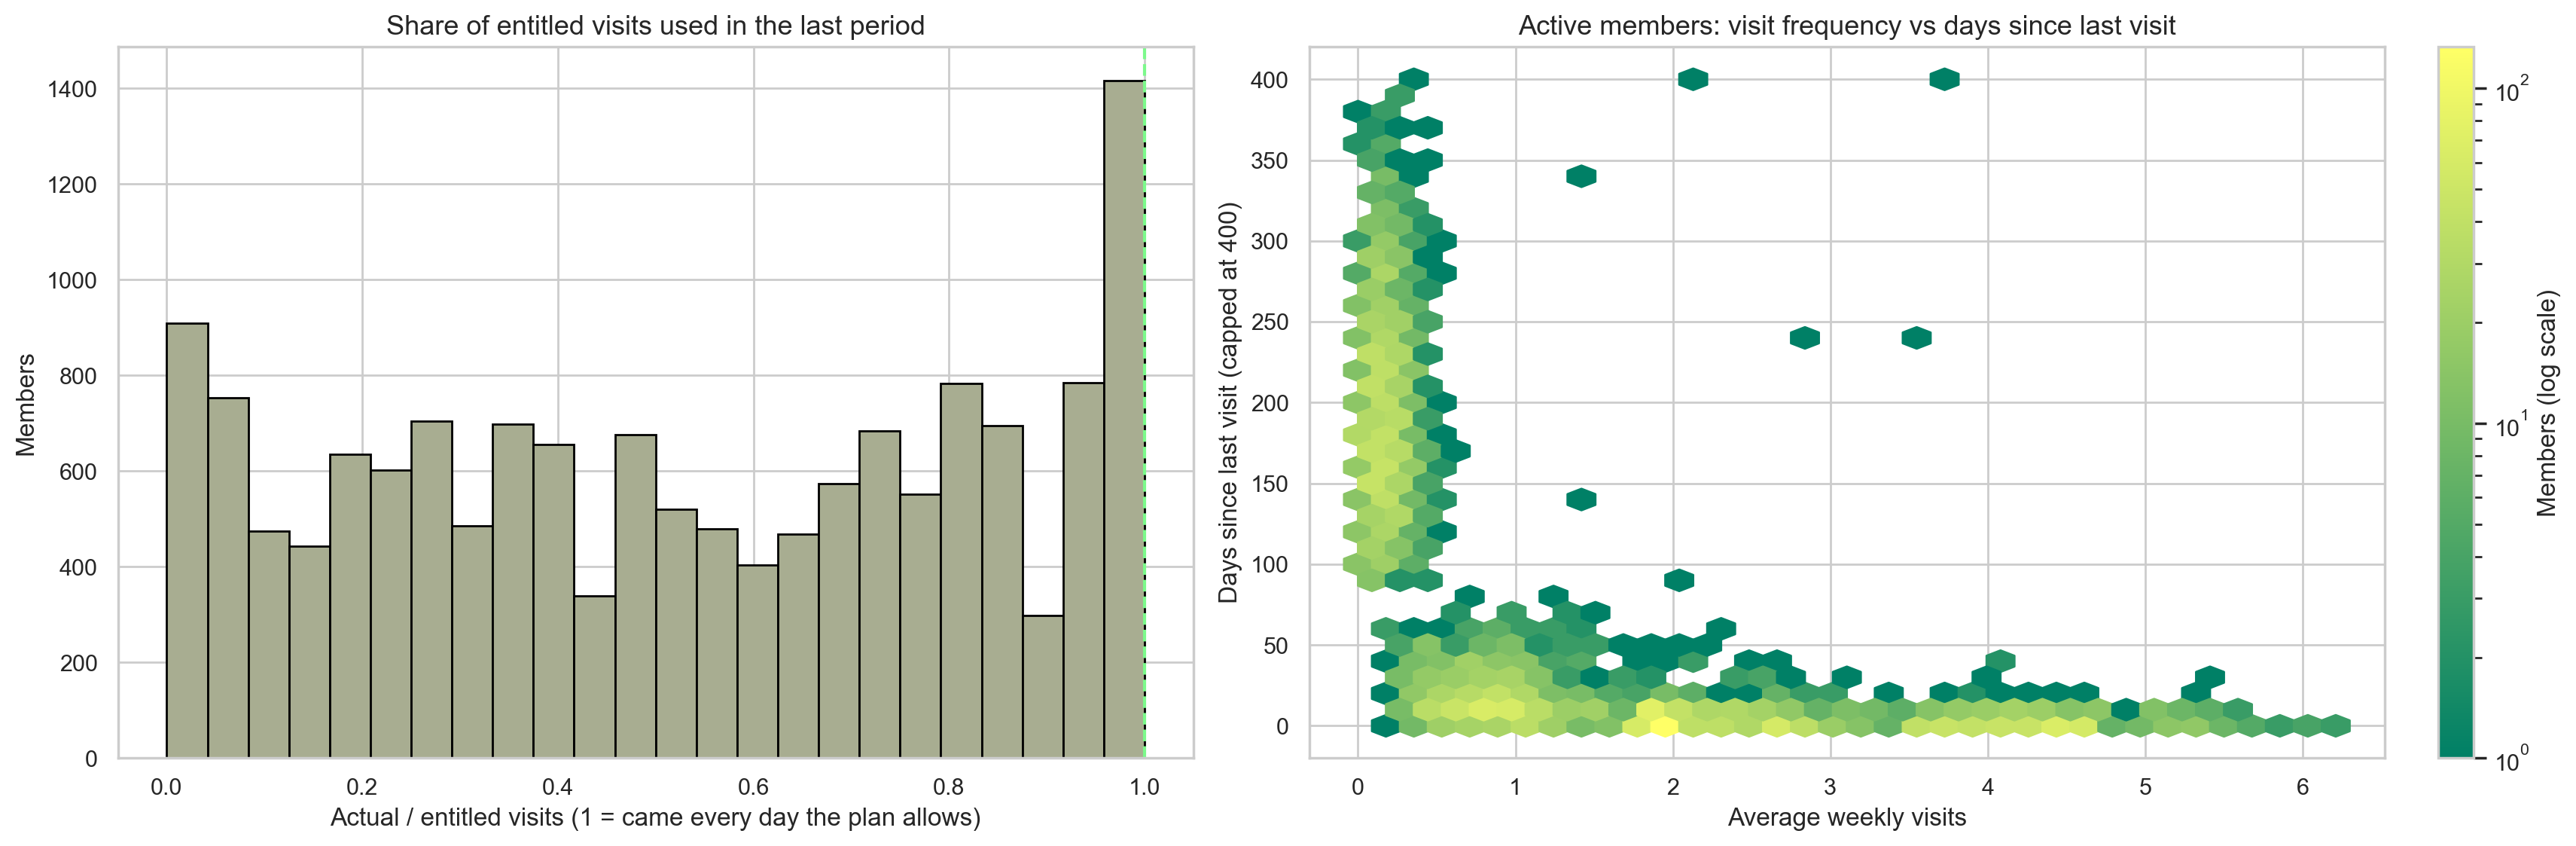

utilisation,below 20%,20-80%,above 80%
plan_tier,,,
hot desk,10.7,59.4,29.9
flex,15.0,58.8,26.2
dedicated desk,34.9,25.0,40.1
full time,34.3,51.7,14.0
private office,60.1,26.8,13.1


In [167]:
plot_usage_patterns(eda_after)

In [168]:
dormant_members(eda_after)

Active members: 3885  |  no visit for more than 90 days: 1281 (33%)


,% of dormant active members
plan_tier,
full time,39.3
dedicated desk,35.2
flex,25.5
hot desk,0.0
private office,0.0


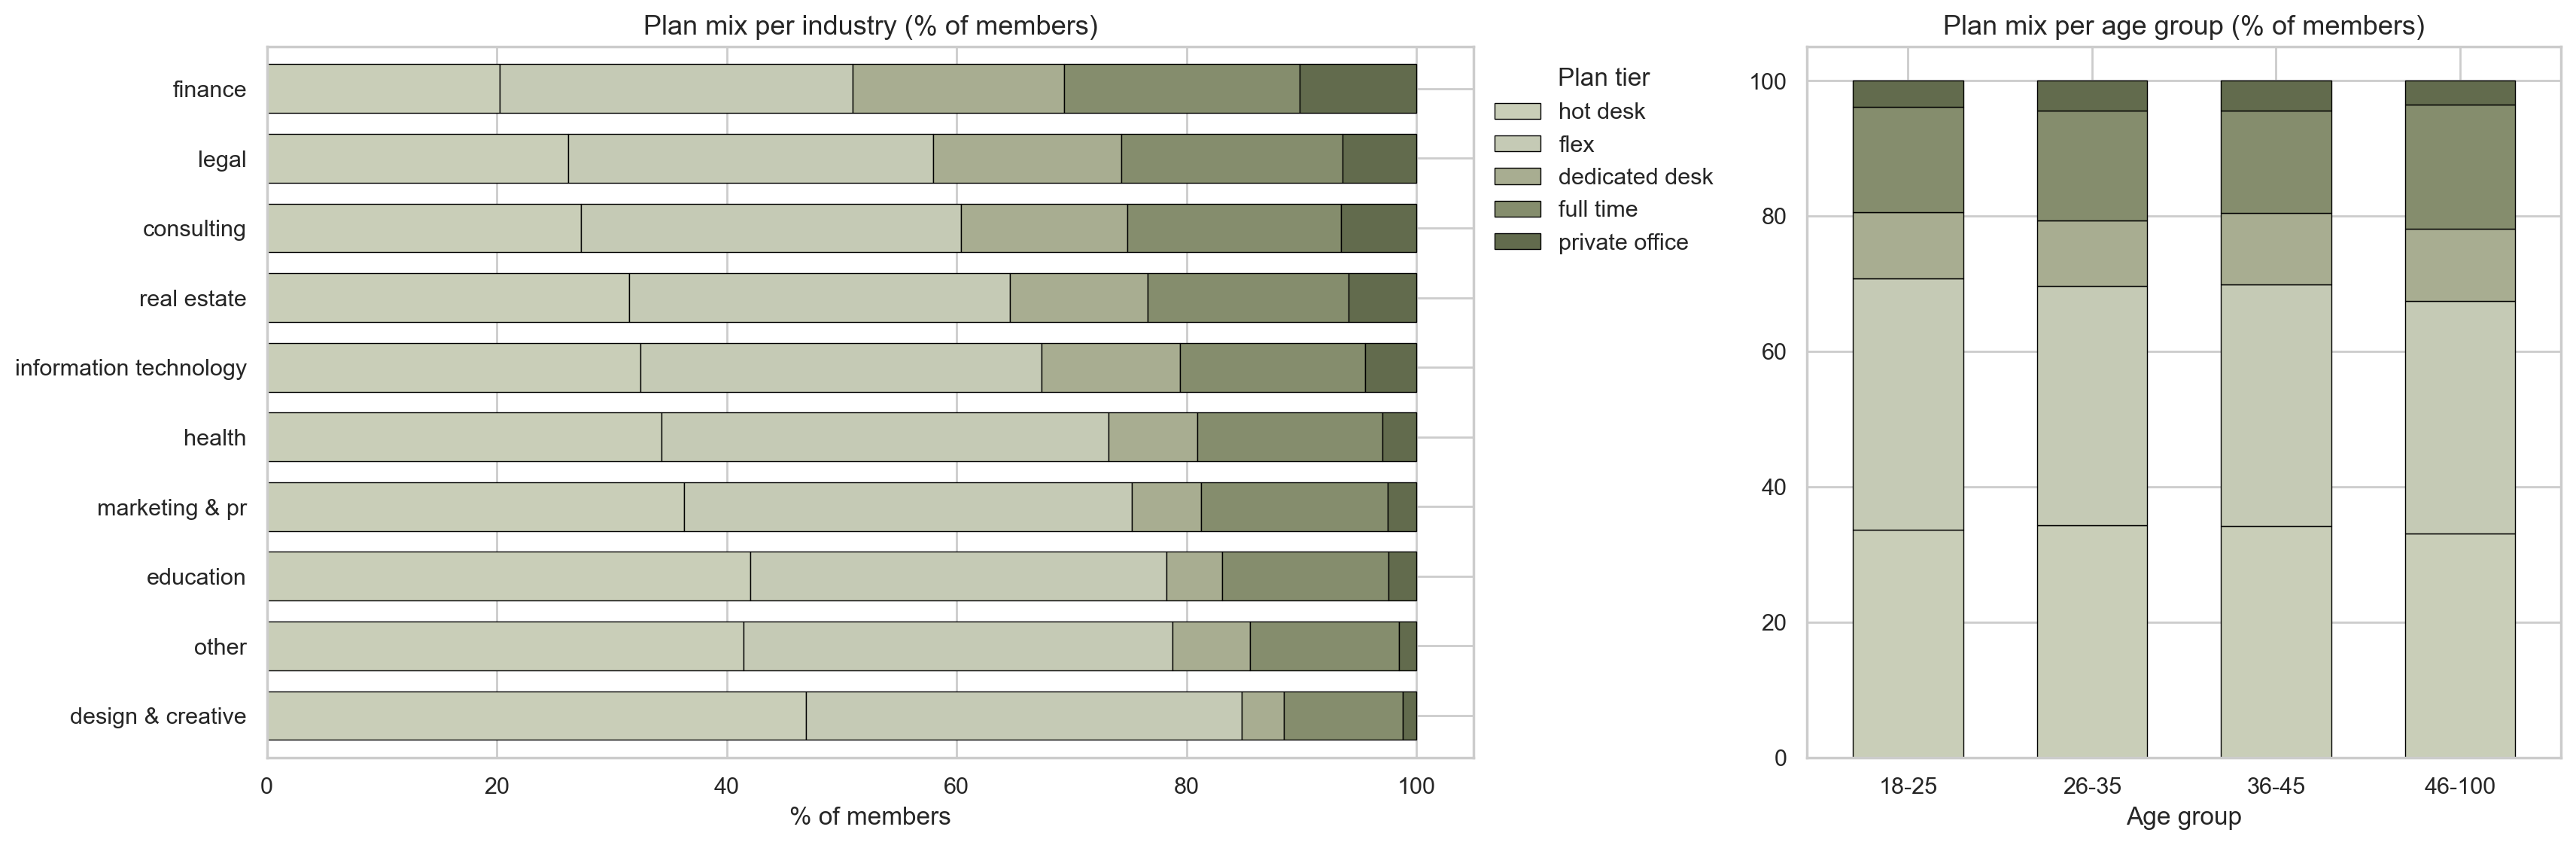

is_team_account,False,True
plan_tier,,
hot desk,71.9,28.1
flex,71.1,28.9
dedicated desk,72.5,27.5
full time,73.2,26.8
private office,68.6,31.4


In [169]:
plot_profile_vs_plan(eda_after)

### 3.2.2 Members over Time

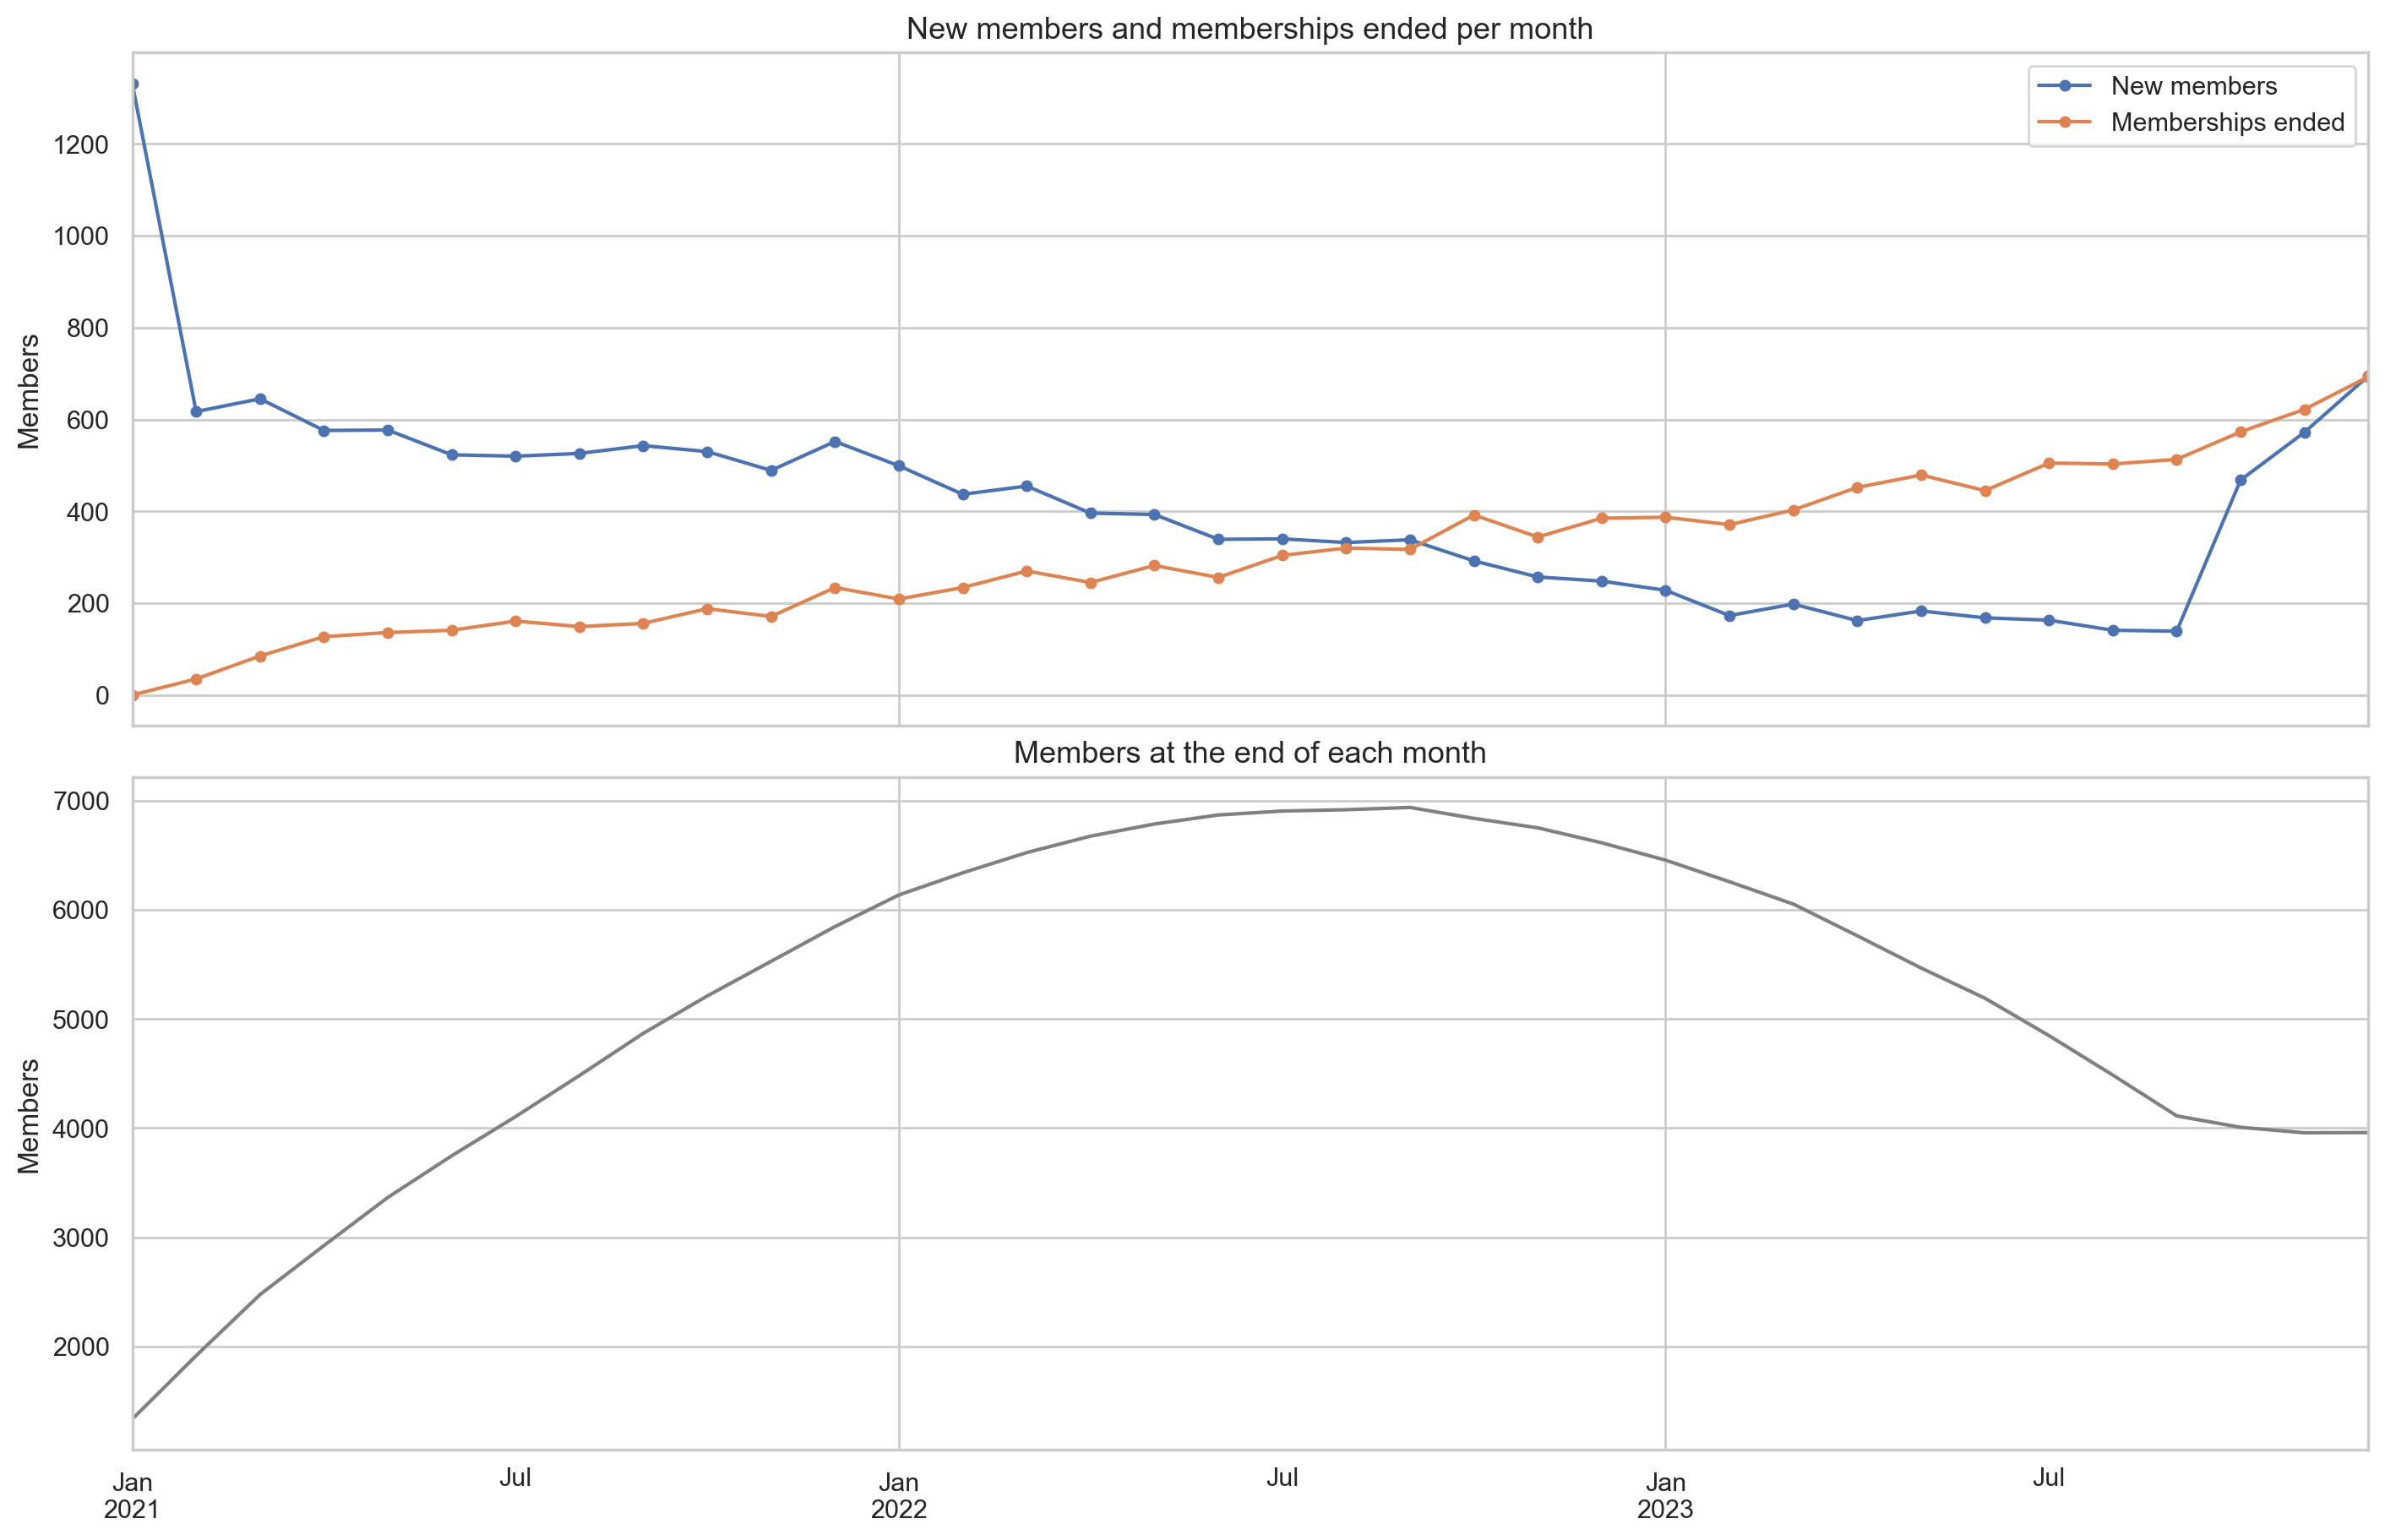

In [170]:
# New members and ended memberships per month, within the 3-year data period
starts = dataset["membership_start"].dt.to_period("M").value_counts()
ends = dataset["membership_end"].dt.to_period("M").value_counts()

monthly = pd.DataFrame({"New members": starts, "Memberships ended": ends}).fillna(0).sort_index()
monthly = monthly.loc["2021-01":"2023-12"]
monthly.index = monthly.index.to_timestamp()

# Members at the end of each month: everyone who joined minus everyone who left so far
members_per_month = (monthly["New members"] - monthly["Memberships ended"]).cumsum()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, layout="constrained")

monthly.plot(ax=axes[0], marker="o", markersize=4)
axes[0].set_title("New members and memberships ended per month", fontsize=13)
axes[0].set_ylabel("Members")
axes[0].set_xlabel("")

members_per_month.plot(ax=axes[1], color="gray")
axes[1].set_title("Members at the end of each month", fontsize=13)
axes[1].set_ylabel("Members")
axes[1].set_xlabel("")

plt.show()


The member base grew quickly in 2021 and peaked at about 6,900 members in September 2022. From then on it shrank steadily, and by the end of 2023 it was down to about 4,000. Sign-ups fell from 7,430 in 2021 to 4,326 in 2022 and 3,290 in 2023, while ended memberships rose from 1,583 to 3,558 and 5,946 (part of the 2021 sign-ups may be members who were already there when the data starts). The trend only changes at the very end: from October to December 2023, sign-ups jumped to 468, 572 and 695 a month, against about 140 to 170 in the months before. This explains part of the large group of very short memberships, and it would be worth asking ACDC what caused it (for example a campaign or a price change).

### 3.2.3 Correlation between Variables

In this section, we examine the relationships between numerical variables using a correlation matrix. This allows us to identify strong associations, potential redundancies, and patterns that may inform further analysis or feature selection.

We use **Spearman** correlation as our main measure. Pearson only captures straight-line relationships and can be dominated by a few extreme values, while Spearman is computed on the ranks of the values, so it measures whether two variables tend to increase (or decrease) together, regardless of the shape of the relationship or of extreme values. This suits our data, which is still highly skewed after the cleaning, keeps extreme but real values (such as heavy users of the services), and includes ordered counts such as `plan_days_per_week` and `n_renewals`. Pearson is computed only to compare the two methods.

In [171]:
acdc_numeric_subset = dataset[[
    'age',
    'n_colleagues_on_account',
    'plan_days_per_week',
    'days_since_last_visit',
    'total_visits',
    'avg_weekly_visits',
    'entitled_visits_last_period',
    'actual_visits_last_period',
    'meeting_room_hours',
    'event_space_hours',
    'guest_passes_issued',
    'n_renewals',
    'lifetime_value'
]]

# Spearman is our main measure; Pearson is computed only for comparison
corr_spearman = acdc_numeric_subset.corr(method="spearman")
corr_pearson = acdc_numeric_subset.corr(method="pearson")

# Mask for the upper triangle and the diagonal (mirror image and self-correlations),
# so that each pair of variables appears only once
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

# Compare both methods for every pair of variables
corr_comparison = pd.DataFrame({
    "Pearson": corr_pearson.where(~mask).stack(),
    "Spearman": corr_spearman.where(~mask).stack()
})
corr_comparison["Difference"] = corr_comparison["Spearman"] - corr_comparison["Pearson"]

# Pairs where the two methods disagree the most
corr_comparison.sort_values("Difference", key=abs, ascending=False).head(10).round(2)

,,Pearson,Spearman,Difference
n_renewals,days_since_last_visit,0.11,-0.24,-0.35
total_visits,days_since_last_visit,-0.26,-0.57,-0.31
lifetime_value,days_since_last_visit,0.08,-0.21,-0.29
avg_weekly_visits,days_since_last_visit,-0.46,-0.73,-0.28
actual_visits_last_period,days_since_last_visit,-0.42,-0.69,-0.27
entitled_visits_last_period,days_since_last_visit,0.17,-0.06,-0.23
days_since_last_visit,plan_days_per_week,0.14,-0.04,-0.18
meeting_room_hours,days_since_last_visit,-0.14,-0.28,-0.14
lifetime_value,total_visits,0.64,0.78,0.13
actual_visits_last_period,plan_days_per_week,0.37,0.25,-0.12


Even after cleaning, the two methods still disagree on several pairs, and almost all of them involve `days_since_last_visit`. This variable is very skewed (most members visited recently, a few have not come in for years), and Pearson is pulled by those long tails. For example, Pearson finds only a moderate relationship between `days_since_last_visit` and `avg_weekly_visits` (-0.46), while Spearman shows a strong one (-0.73): members who visit more often were there more recently. The same happens with `lifetime_value` and `total_visits` (0.64 vs 0.78). This is why we rely on Spearman from here on.

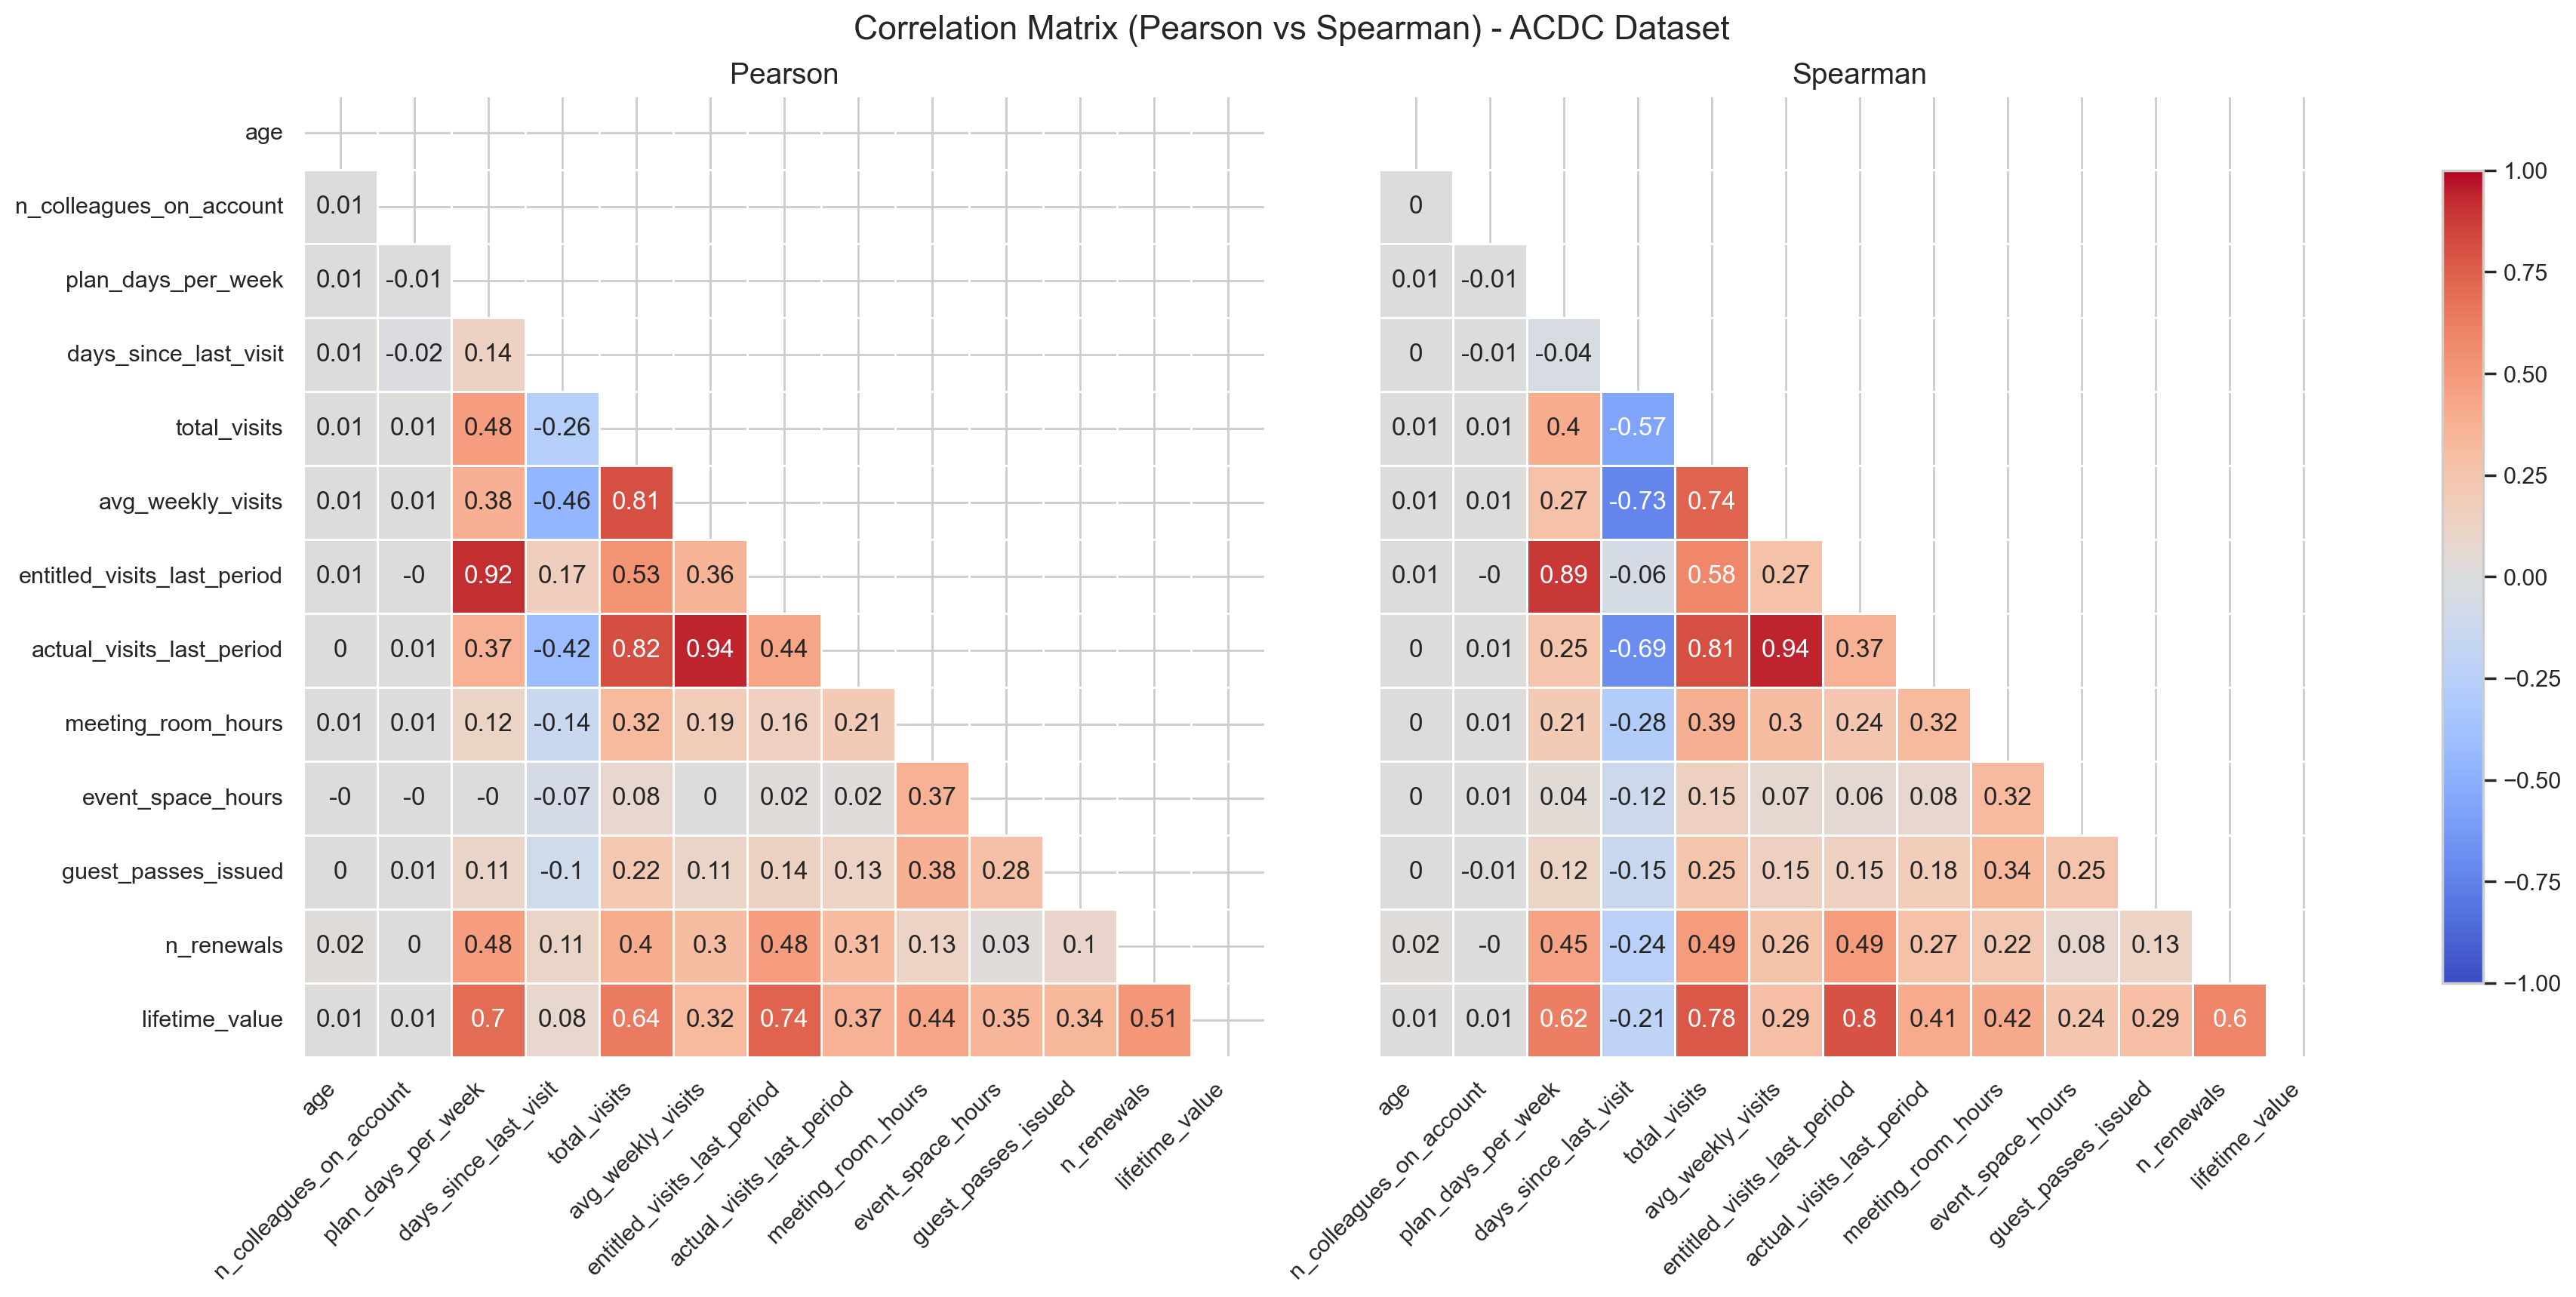

In [172]:
# Pearson (left) and Spearman (right) side by side, on the same colour scale
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5), layout="constrained")

for ax, corr, method in zip(axes, [corr_pearson, corr_spearman], ["Pearson", "Spearman"]):
    sns.heatmap(
        corr.round(2),
        mask=mask,                # hide the upper triangle and the diagonal
        annot=True,               # show the coefficient in each cell
        cmap="coolwarm",          # diverging palette: blue = negative, red = positive
        center=0,                 # centre the colour scale on 0
        linewidths=0.5,           # lines between cells
        vmin=-1, vmax=1,          # same fixed scale for both plots
        square=True,              # square cells
        cbar=False,               # a single shared colour bar is added below
        ax=ax
    )
    ax.set_title(method, fontsize=14)
    ax.tick_params(axis="x", labelrotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

# The rows are the same in both plots, so the variable names are only shown on the left
axes[1].set_yticks([])

# One colour bar shared by both heatmaps
fig.colorbar(axes[1].collections[0], ax=axes, shrink=0.8)

fig.suptitle("Correlation Matrix (Pearson vs Spearman) - ACDC Dataset", fontsize=16)
plt.show()

In [173]:
# Strongest relationships first, sorted by absolute value (positive or negative)
top_pairs = corr_spearman.where(~mask).stack().sort_values(key=abs, ascending=False)

top_pairs.head(10).round(2).to_frame("Spearman")

Spearman
actual_visits_last_period   avg_weekly_visits                0.94
entitled_visits_last_period plan_days_per_week               0.89
actual_visits_last_period   total_visits                     0.81
lifetime_value              entitled_visits_last_period      0.80
                            total_visits                     0.78
avg_weekly_visits           total_visits                     0.74
                            days_since_last_visit           -0.73
actual_visits_last_period   days_since_last_visit           -0.69
lifetime_value              plan_days_per_week               0.62
                            n_renewals                       0.60

**Conclusions from the correlation analysis:**

- The three strongest pairs (0.81 or higher) carry almost the same information: `actual_visits_last_period` and `avg_weekly_visits` (0.94), `entitled_visits_last_period` and `plan_days_per_week` (0.89), and `actual_visits_last_period` and `total_visits` (0.81). Keeping both variables of a pair would give that behaviour double weight in the clustering, so one of each is a candidate to be dropped.
- The strong link between `entitled_visits_last_period` and `plan_days_per_week` supports our earlier hypothesis that the entitled visits are calculated from the plan rather than counted.
- `lifetime_value` is most related to `entitled_visits_last_period` (0.80), `total_visits` (0.78), `plan_days_per_week` (0.62) and `n_renewals` (0.60). In other words, a member’s value depends on two things: the plan they pay for and how long they have been a member. It is only weakly related to how often they come in (`avg_weekly_visits`, 0.29), which is a first sign that value and usage are different dimensions. This is the reason we separate the value per month from the tenure in section 3.3.
- Visit frequency is negatively related to `days_since_last_visit` (between -0.57 and -0.73): members who visit more often have fewer days since their last visit.
- `age` and `n_colleagues_on_account` are practically uncorrelated with all the other variables (|ρ| ≤ 0.02), so they describe the member’s profile rather than their behaviour.

## 3.3 Feature Engineering

Many original variables grow with time: a member who stayed three years will have more value, renewals and hours than one who joined last month, even if both use the space the same way. Clustering on these raw values would mostly separate old members from new ones. Here we turn totals into rates (per month or per year) and visits into a share of what the plan allows, so that all members can be compared on equal terms.

### 3.3.1 `membership_duration_months`

**Formula:** `tenure_days / DAYS_PER_MONTH` (30.44, defined in the Constants at the top)

`tenure_days` counts the days between the start of the membership and its end (or the extraction date, for members who are still active). Days are hard to read when we talk about memberships, so we convert them to months.

**Why 30.44?** Months have 28 to 31 days, so we use the average length of a month. A year has 365.25 days on average (365, plus one extra day every four years for leap years), and dividing by 12 months gives 365.25 / 12 = 30.44 days per month. Using 30 or 31 would make every membership slightly longer or shorter than it really is.

This feature is also the base for all the "per month" and "per year" features below, which is why it comes first.

In [174]:
dataset["membership_duration_months"] = dataset["tenure_days"] / DAYS_PER_MONTH

# Per-month and per-year rates are only computed for members with at least one full month:
# dividing by a few days would turn small numbers into huge, meaningless rates
at_least_one_month = dataset["membership_duration_months"] >= 1
print(f"Members with less than one month of membership: {(~at_least_one_month).sum()} ({(~at_least_one_month).mean():.1%})")

dataset["membership_duration_months"].describe().round(2)

Members with less than one month of membership: 678 (4.5%)


count    15046.00
mean        12.30
std         11.13
min          0.07
25%          2.14
50%          9.26
75%         20.89
max         35.97
Name: membership_duration_months, dtype: float64

### 3.3.2 `revenue_per_month`

**Formula:** `lifetime_value / membership_duration_months`

`lifetime_value` is the total revenue a member brought in, so it grows with time: a member who stayed three years will almost always have a higher value than one who stayed three months, even on a cheaper plan. Dividing by the number of months gives the average revenue per month, which tells us how valuable a member is while they are a member, regardless of how long they stayed.

Together with `membership_duration_months`, it splits the old `lifetime_value` into its two parts: how much the member is worth per month, and for how long.

In [175]:
dataset["revenue_per_month"] = (dataset["lifetime_value"] / dataset["membership_duration_months"]).where(at_least_one_month)

dataset["revenue_per_month"].describe().round(2)

count    11667.00
mean       268.38
std        167.19
min        116.44
25%        151.28
50%        207.25
75%        327.66
max       2715.76
Name: revenue_per_month, dtype: float64

### 3.3.3 `renewals_per_year`

**Formula:** `n_renewals / (membership_duration_months / 12)`

`n_renewals` on its own also depends on time: someone who joined last month cannot have renewed many times yet. Dividing by the membership length in years (months divided by 12) gives a renewal rate that can be compared across members, which works as a measure of loyalty: how often the member chose to stay, given the time they had to decide.

In [176]:
dataset["renewals_per_year"] = (dataset["n_renewals"] / (dataset["membership_duration_months"] / 12)).where(at_least_one_month)

# More than 12 renewals per year would mean more than one renewal per month
print(f"Members with more than 12 renewals per year: {(dataset['renewals_per_year'] > 12).sum()}")
dataset["renewals_per_year"].describe().round(2)

Members with more than 12 renewals per year: 160


count    14304.0
mean         1.1
std         2.74
min          0.0
25%          0.0
50%         0.33
75%         1.26
max        55.35
Name: renewals_per_year, dtype: Float64

### 3.3.4 `plan_tier_level`

**Formula:** hot desk = 1, flex = 2, dedicated desk = 3, full time = 4, private office = 5

`plan_tier` is stored as text, and clustering algorithms based on distances can only work with numbers. The plans have a natural order (the metadata describes them as hot desk < flex < dedicated desk < full time < private office), so instead of creating one column per plan we turn them into a single number that keeps that order.

In [177]:
dataset["plan_tier_level"] = dataset["plan_tier"].map({tier: level for level, tier in enumerate(TIER_ORDER, start=1)})

dataset[["plan_tier", "plan_tier_level"]].drop_duplicates().dropna().sort_values("plan_tier_level")

,plan_tier,plan_tier_level
member_id,,
CW000002,hot desk,1.0
CW000003,flex,2.0
CW000010,dedicated desk,3.0
CW000011,full time,4.0
CW015229,private office,5.0


### 3.3.5 `utilisation_rate`

**Formula:** `actual_visits_last_period / entitled_visits_last_period`

This compares how many times the member came in during the last period with how many visits their plan allowed. A value of 1 means the member came every day they could, 0.5 means they used half of their days, and 0 means they did not come at all.

Raw visit counts cannot be compared across plans: 10 visits is a lot on a 2-day plan but very little on a 7-day one. Dividing by the entitlement puts every plan on the same 0 to 1 scale. 

In [178]:
has_entitlement = dataset["entitled_visits_last_period"] > 0
dataset["utilisation_rate"] = (dataset["actual_visits_last_period"] / dataset["entitled_visits_last_period"]).where(has_entitlement)

dataset["utilisation_rate"].describe().round(2)

count    15036.00
mean         0.52
std          0.31
min          0.00
25%          0.24
50%          0.52
75%          0.80
max          1.00
Name: utilisation_rate, dtype: float64

### 3.3.6 `total_addons_used`

**Formula:** number of `uses_*` columns that are true

There are nine add-on flags (meeting rooms, event space, guest passes, print, mail handling, phone booths, day passes, storage and bike locker). Each one says whether the member used that service. Adding them up gives a single number, from 0 to 9, that shows how broadly the member uses ACDC beyond the desk itself. 

In [179]:
dataset["total_addons_used"] = dataset[ADDON_COLUMNS].sum(axis=1)

dataset["total_addons_used"].value_counts().sort_index().to_frame("Members")

,Members
total_addons_used,
0,3053
1,4519
2,3139
3,2068
4,1348
5,666
6,219
7,31
8,3


### 3.3.7 `service_hours_per_month`

**Formula:** `(meeting_room_hours + event_space_hours) / membership_duration_months`

Meeting rooms and event spaces are the two bookable spaces, so we add their hours together as a measure of how much the member uses them. As with the value, the totals grow with time, so we divide by the months of membership to get an average per month. If either of the two hour columns is missing, the result is missing too.

In [180]:
dataset["service_hours_per_month"] = ((dataset["meeting_room_hours"] + dataset["event_space_hours"]) / dataset["membership_duration_months"]).where(at_least_one_month)

dataset["service_hours_per_month"].describe().round(2)

count    13183.00
mean         1.83
std          4.87
min          0.00
25%          0.00
50%          0.00
75%          1.22
max        166.86
Name: service_hours_per_month, dtype: float64

### 3.3.8 `guest_passes_per_month`

**Formula:** `guest_passes_issued / membership_duration_months`

Guest passes show how often a member brings in people from outside, such as clients or partners, which suggests a more client-facing or networking-oriented use of the space. Dividing by the months of membership again gives an average per month that does not depend on how long the member stayed.

In [181]:
dataset["guest_passes_per_month"] = (dataset["guest_passes_issued"] / dataset["membership_duration_months"]).where(at_least_one_month)

dataset["guest_passes_per_month"].describe().round(2)

count    13200.00
mean         0.38
std          1.26
min          0.00
25%          0.00
50%          0.00
75%          0.00
max         25.01
Name: guest_passes_per_month, dtype: float64

### 3.3.9 `total_account_members`

**Formula:** `n_colleagues_on_account + 1`

`n_colleagues_on_account` counts the other people sharing the account, so an individual member has 0. Adding 1 includes the member themselves and gives the total number of people behind the membership: 1 for an individual account, 3 for a member with two colleagues, and so on.

In [182]:
dataset["total_account_members"] = dataset["n_colleagues_on_account"] + 1

dataset["total_account_members"].value_counts().sort_index().to_frame("Members")

,Members
total_account_members,
1.0,10400
2.0,1716
3.0,1085
4.0,709
5.0,373
6.0,137
7.0,54
8.0,14
9.0,2


### 3.3.10 Distributions of the Engineered Features

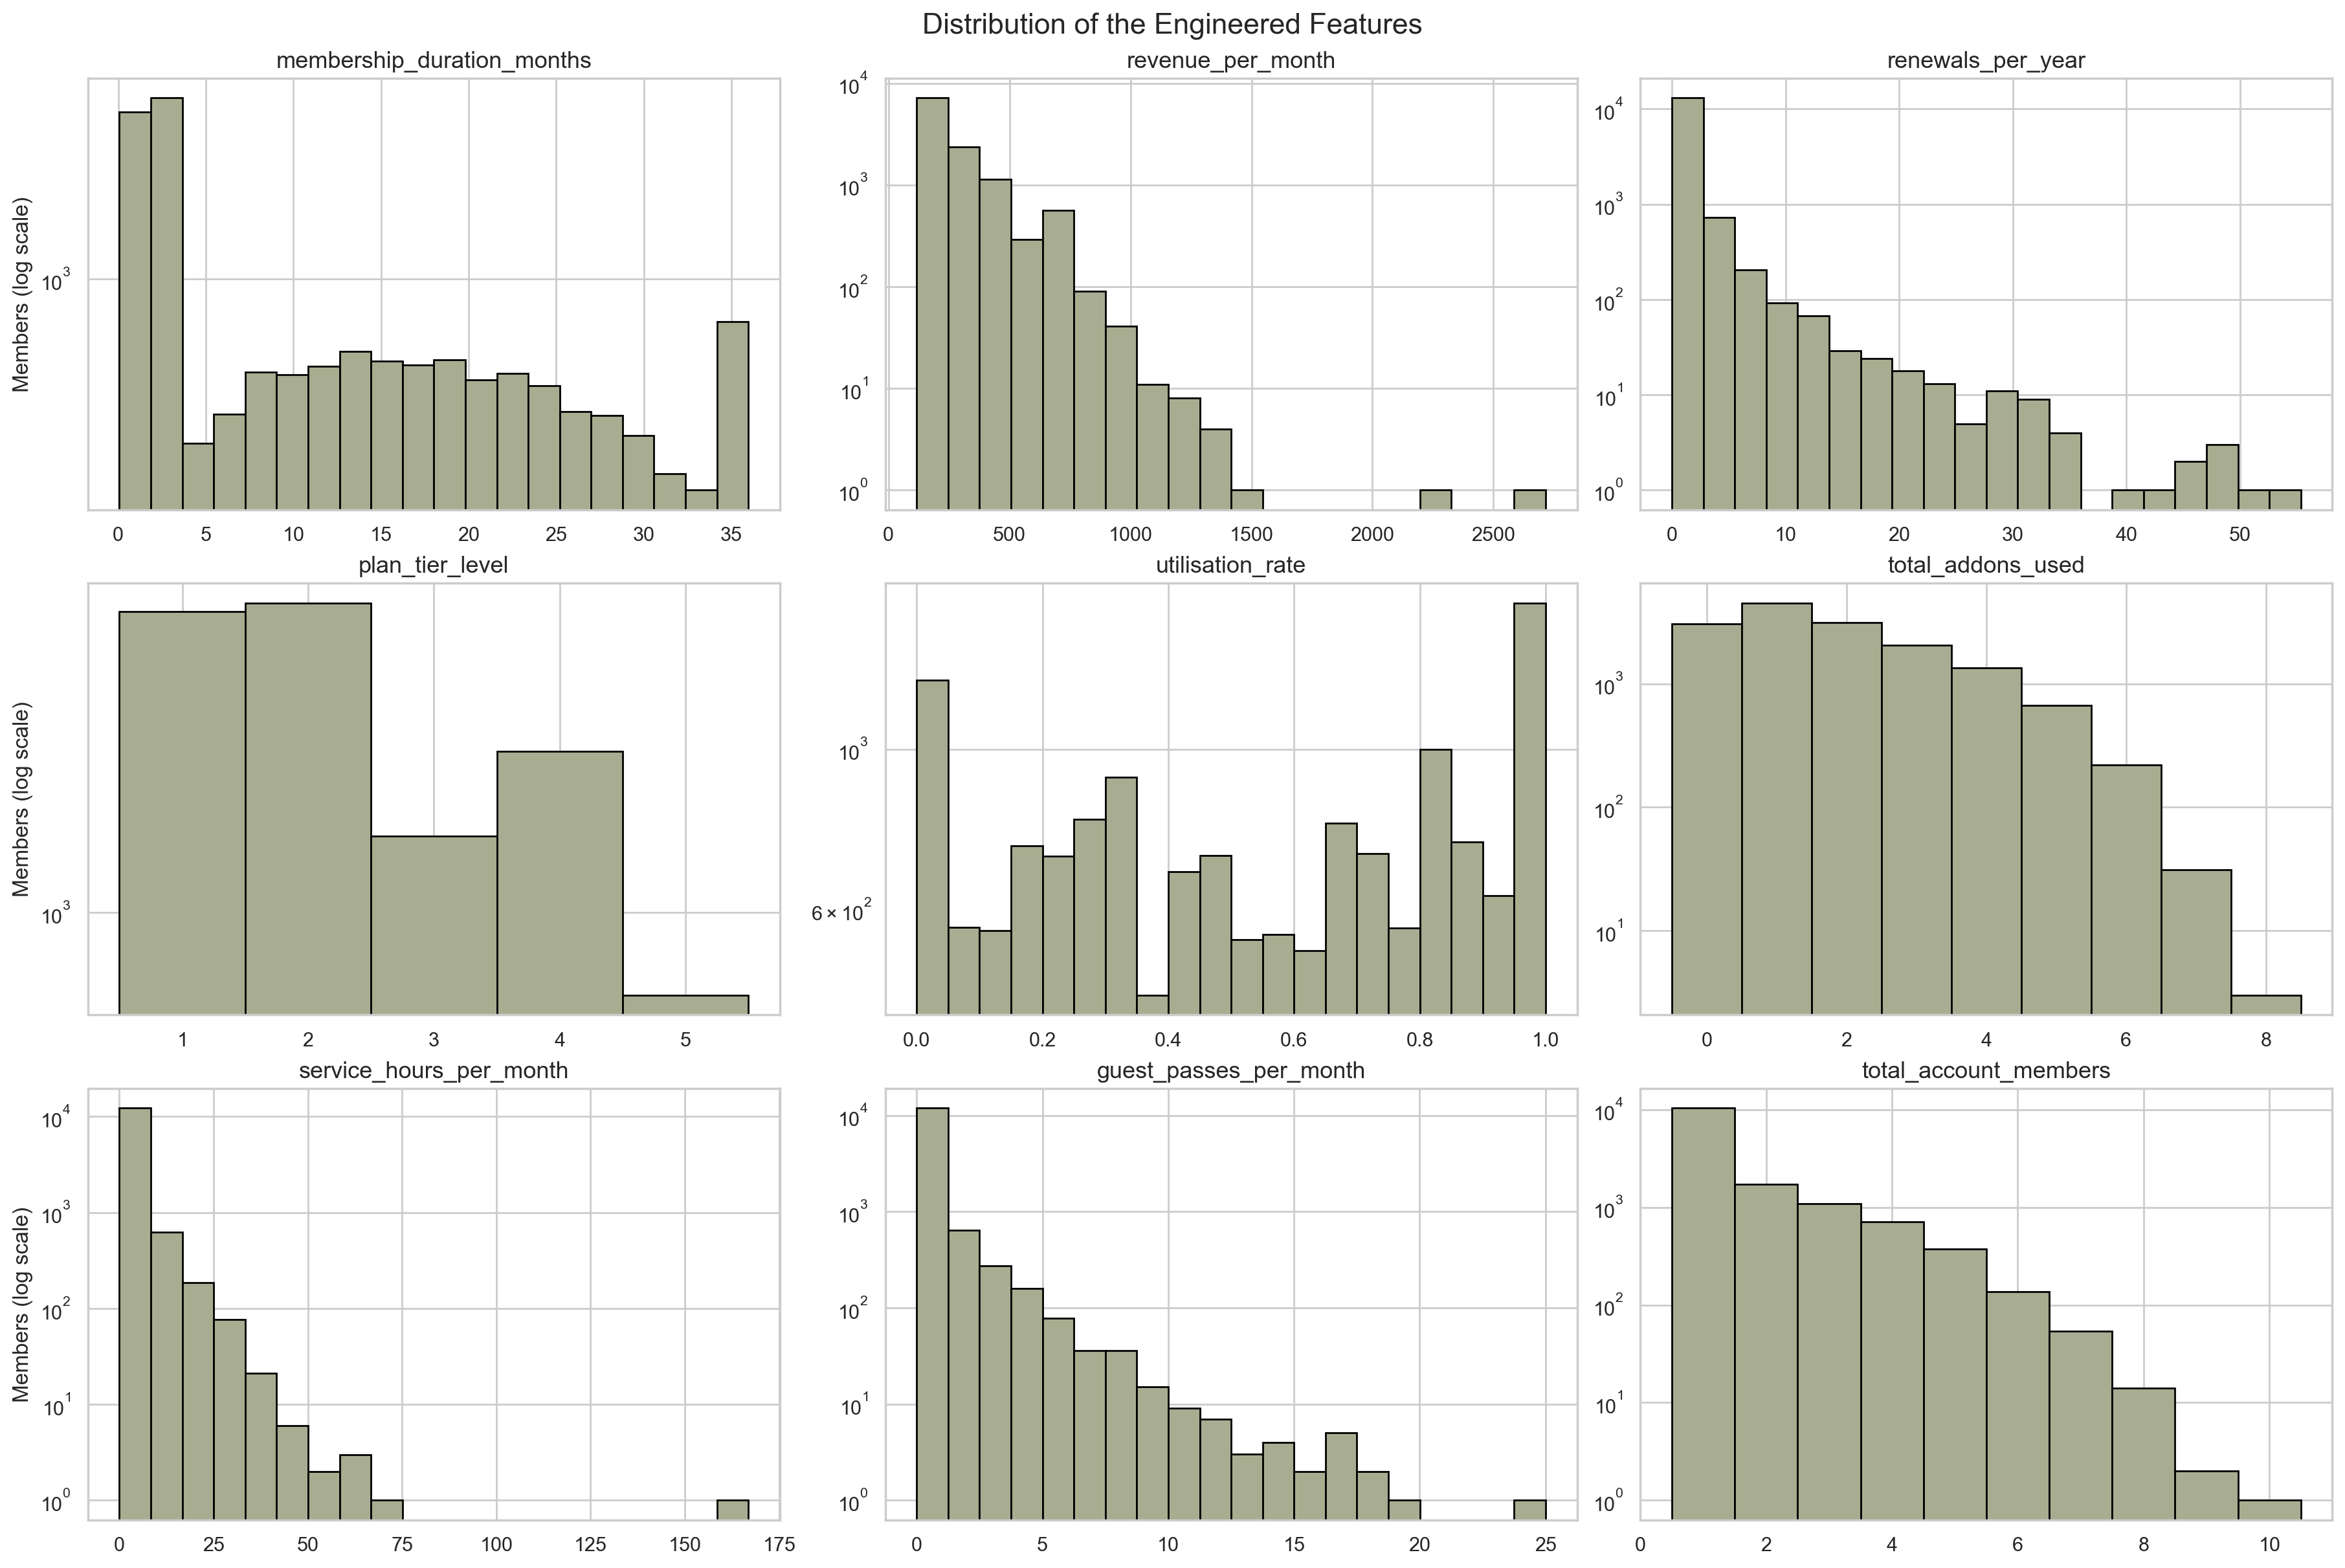

In [183]:
engineered_features = ["membership_duration_months", "revenue_per_month", "renewals_per_year", "plan_tier_level", "utilisation_rate",
                       "total_addons_used", "service_hours_per_month", "guest_passes_per_month", "total_account_members"]

plot_histograms(dataset, engineered_features, "Distribution of the Engineered Features",
                discrete_features=["plan_tier_level", "total_addons_used", "total_account_members"])

A few things stand out. `utilisation_rate` is far from a bell curve: there are peaks at 0 and at 1, which confirms the two opposite behaviours seen in section 2.6.2.3. `membership_duration_months` has a large group of very short memberships (under three months) and a spike at 36 months, which are the members who have been there since the start of the data and are still active. `revenue_per_month` is concentrated between roughly 120 € and 400 € a month, with the clusters of values matching the plan prices.

`service_hours_per_month`, `guest_passes_per_month` and `renewals_per_year` are mostly zeros with a long tail, so they will need a log transformation before clustering. `renewals_per_year` also has values far above 12 (one renewal a month), which come from members who renewed several times within a membership of only one or two months. This is the same inconsistency found in the outlier section and should be checked before these values are used.

### 3.3.11 Engineered Features by Plan

The plan already tells us a lot about a member. A useful feature should also show differences within each plan, otherwise it adds little that the plan does not already say.

In [184]:
dataset.groupby("plan_tier")[engineered_features].median().reindex(TIER_ORDER).T.round(2)

plan_tier,hot desk,flex,dedicated desk,full time,private office
membership_duration_months,2.628121,8.574244,26.609724,17.148489,29.862024
revenue_per_month,132.328291,204.790954,406.948725,312.771,701.19885
renewals_per_year,0.0,0.0,1.000767,0.667178,1.000767
plan_tier_level,1.0,2.0,3.0,4.0,5.0
utilisation_rate,0.461133,0.574933,0.735971,0.333,0.147856
total_addons_used,1.0,1.0,3.0,2.0,3.0
service_hours_per_month,0.0,0.0,0.611529,0.0,0.37309
guest_passes_per_month,0.0,0.0,0.0,0.0,0.0
total_account_members,1.0,1.0,1.0,1.0,1.0


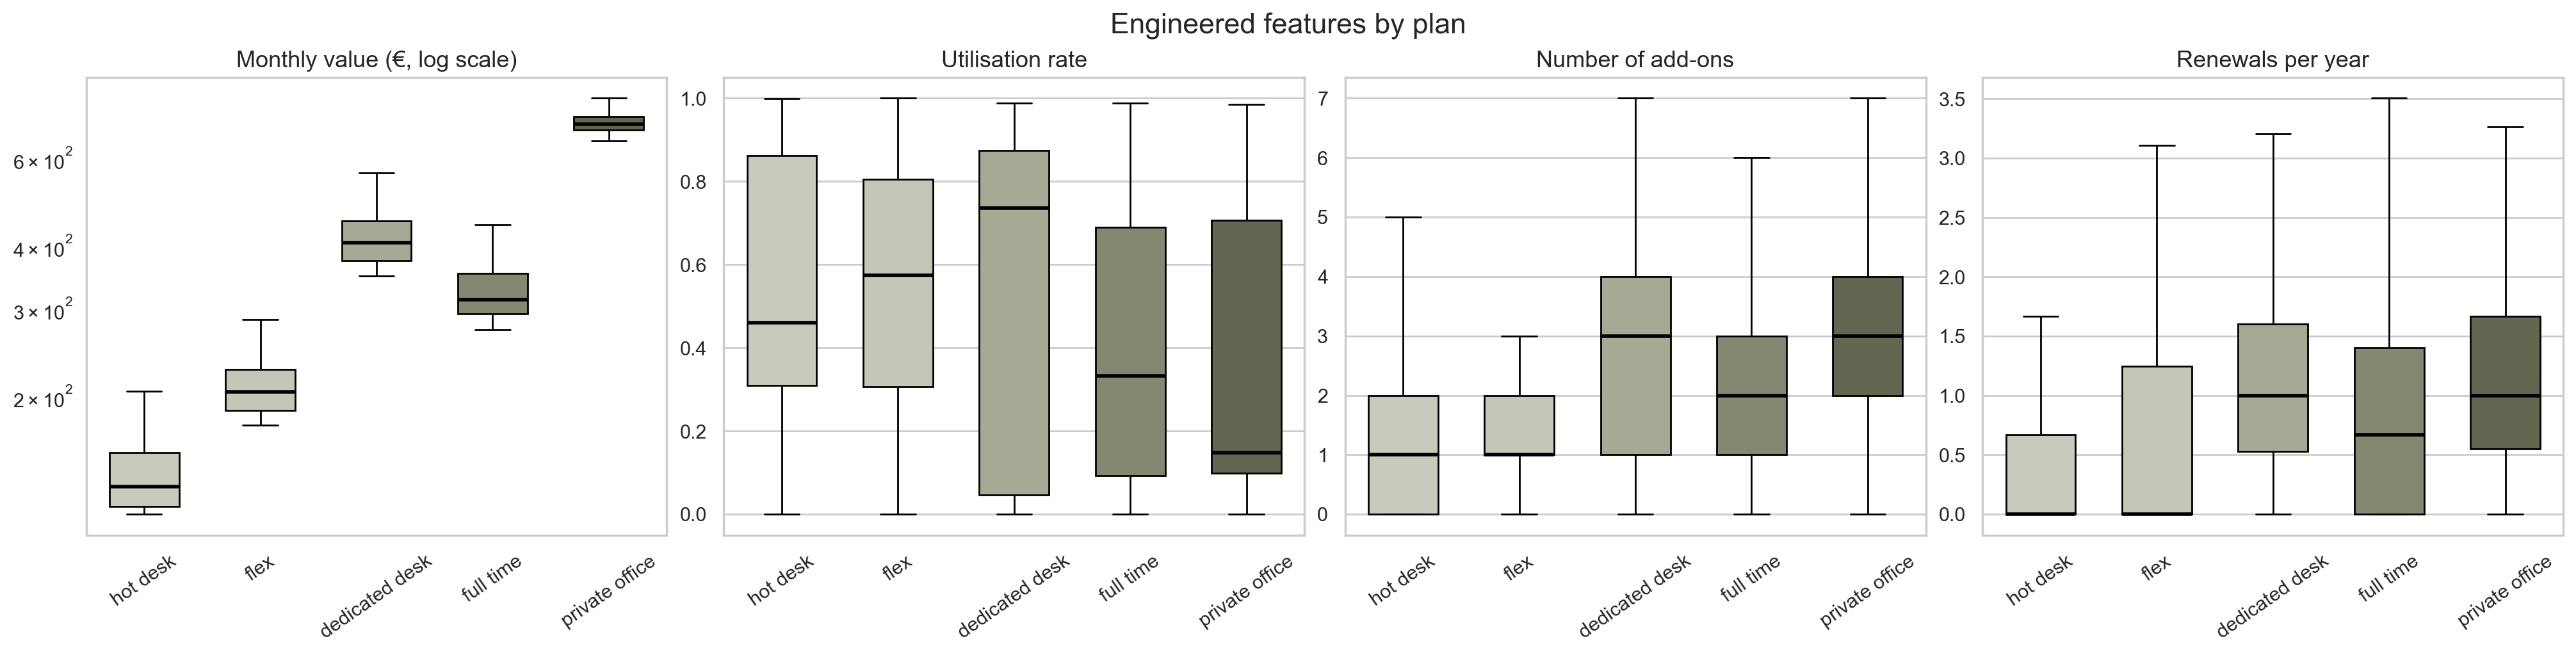

In [185]:
features_by_plan = ["revenue_per_month", "utilisation_rate", "total_addons_used", "renewals_per_year"]
titles = ["Monthly value (€, log scale)", "Utilisation rate", "Number of add-ons", "Renewals per year"]
palette = [TIER_COLORS[t] for t in TIER_ORDER]

fig, axes = plt.subplots(1, 4, figsize=(20, 5), layout="constrained")
for ax, feature, title in zip(axes, features_by_plan, titles):
    sns.boxplot(data=dataset, x="plan_tier", y=feature, order=TIER_ORDER, hue="plan_tier", hue_order=TIER_ORDER,
                palette=palette, legend=False, showfliers=False, width=0.6, linecolor="black",
                medianprops={"color": "black", "linewidth": 2}, ax=ax)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=35)
axes[0].set_yscale("log")
fig.suptitle("Engineered features by plan", fontsize=16)
plt.show()

Some features mainly reflect the plan, while others vary a lot inside it. `revenue_per_month` is clearly driven by the plan: each plan sits in its own narrow band, from a median of about 130 € on hot desk to about 700 € on private office. Interestingly, dedicated desk members are worth more per month than full time members (about 410 € against 310 €), even though `full time` is ranked higher in the plan order given in the metadata.

`utilisation_rate` behaves very differently. The spread inside each plan is huge, especially on dedicated desk, full time and private office, where members range from almost never coming to coming every day. This is exactly the kind of variable that can separate members beyond their plan. `total_addons_used` and `renewals_per_year` are somewhere in between: they increase with the plan, but still vary within each one.

### 3.3.12 Redundancy Check

Two features that carry the same information would count the same behaviour twice in a distance-based clustering. We check this with Spearman correlation, as in section 3.2.3, including the main original variables for comparison.

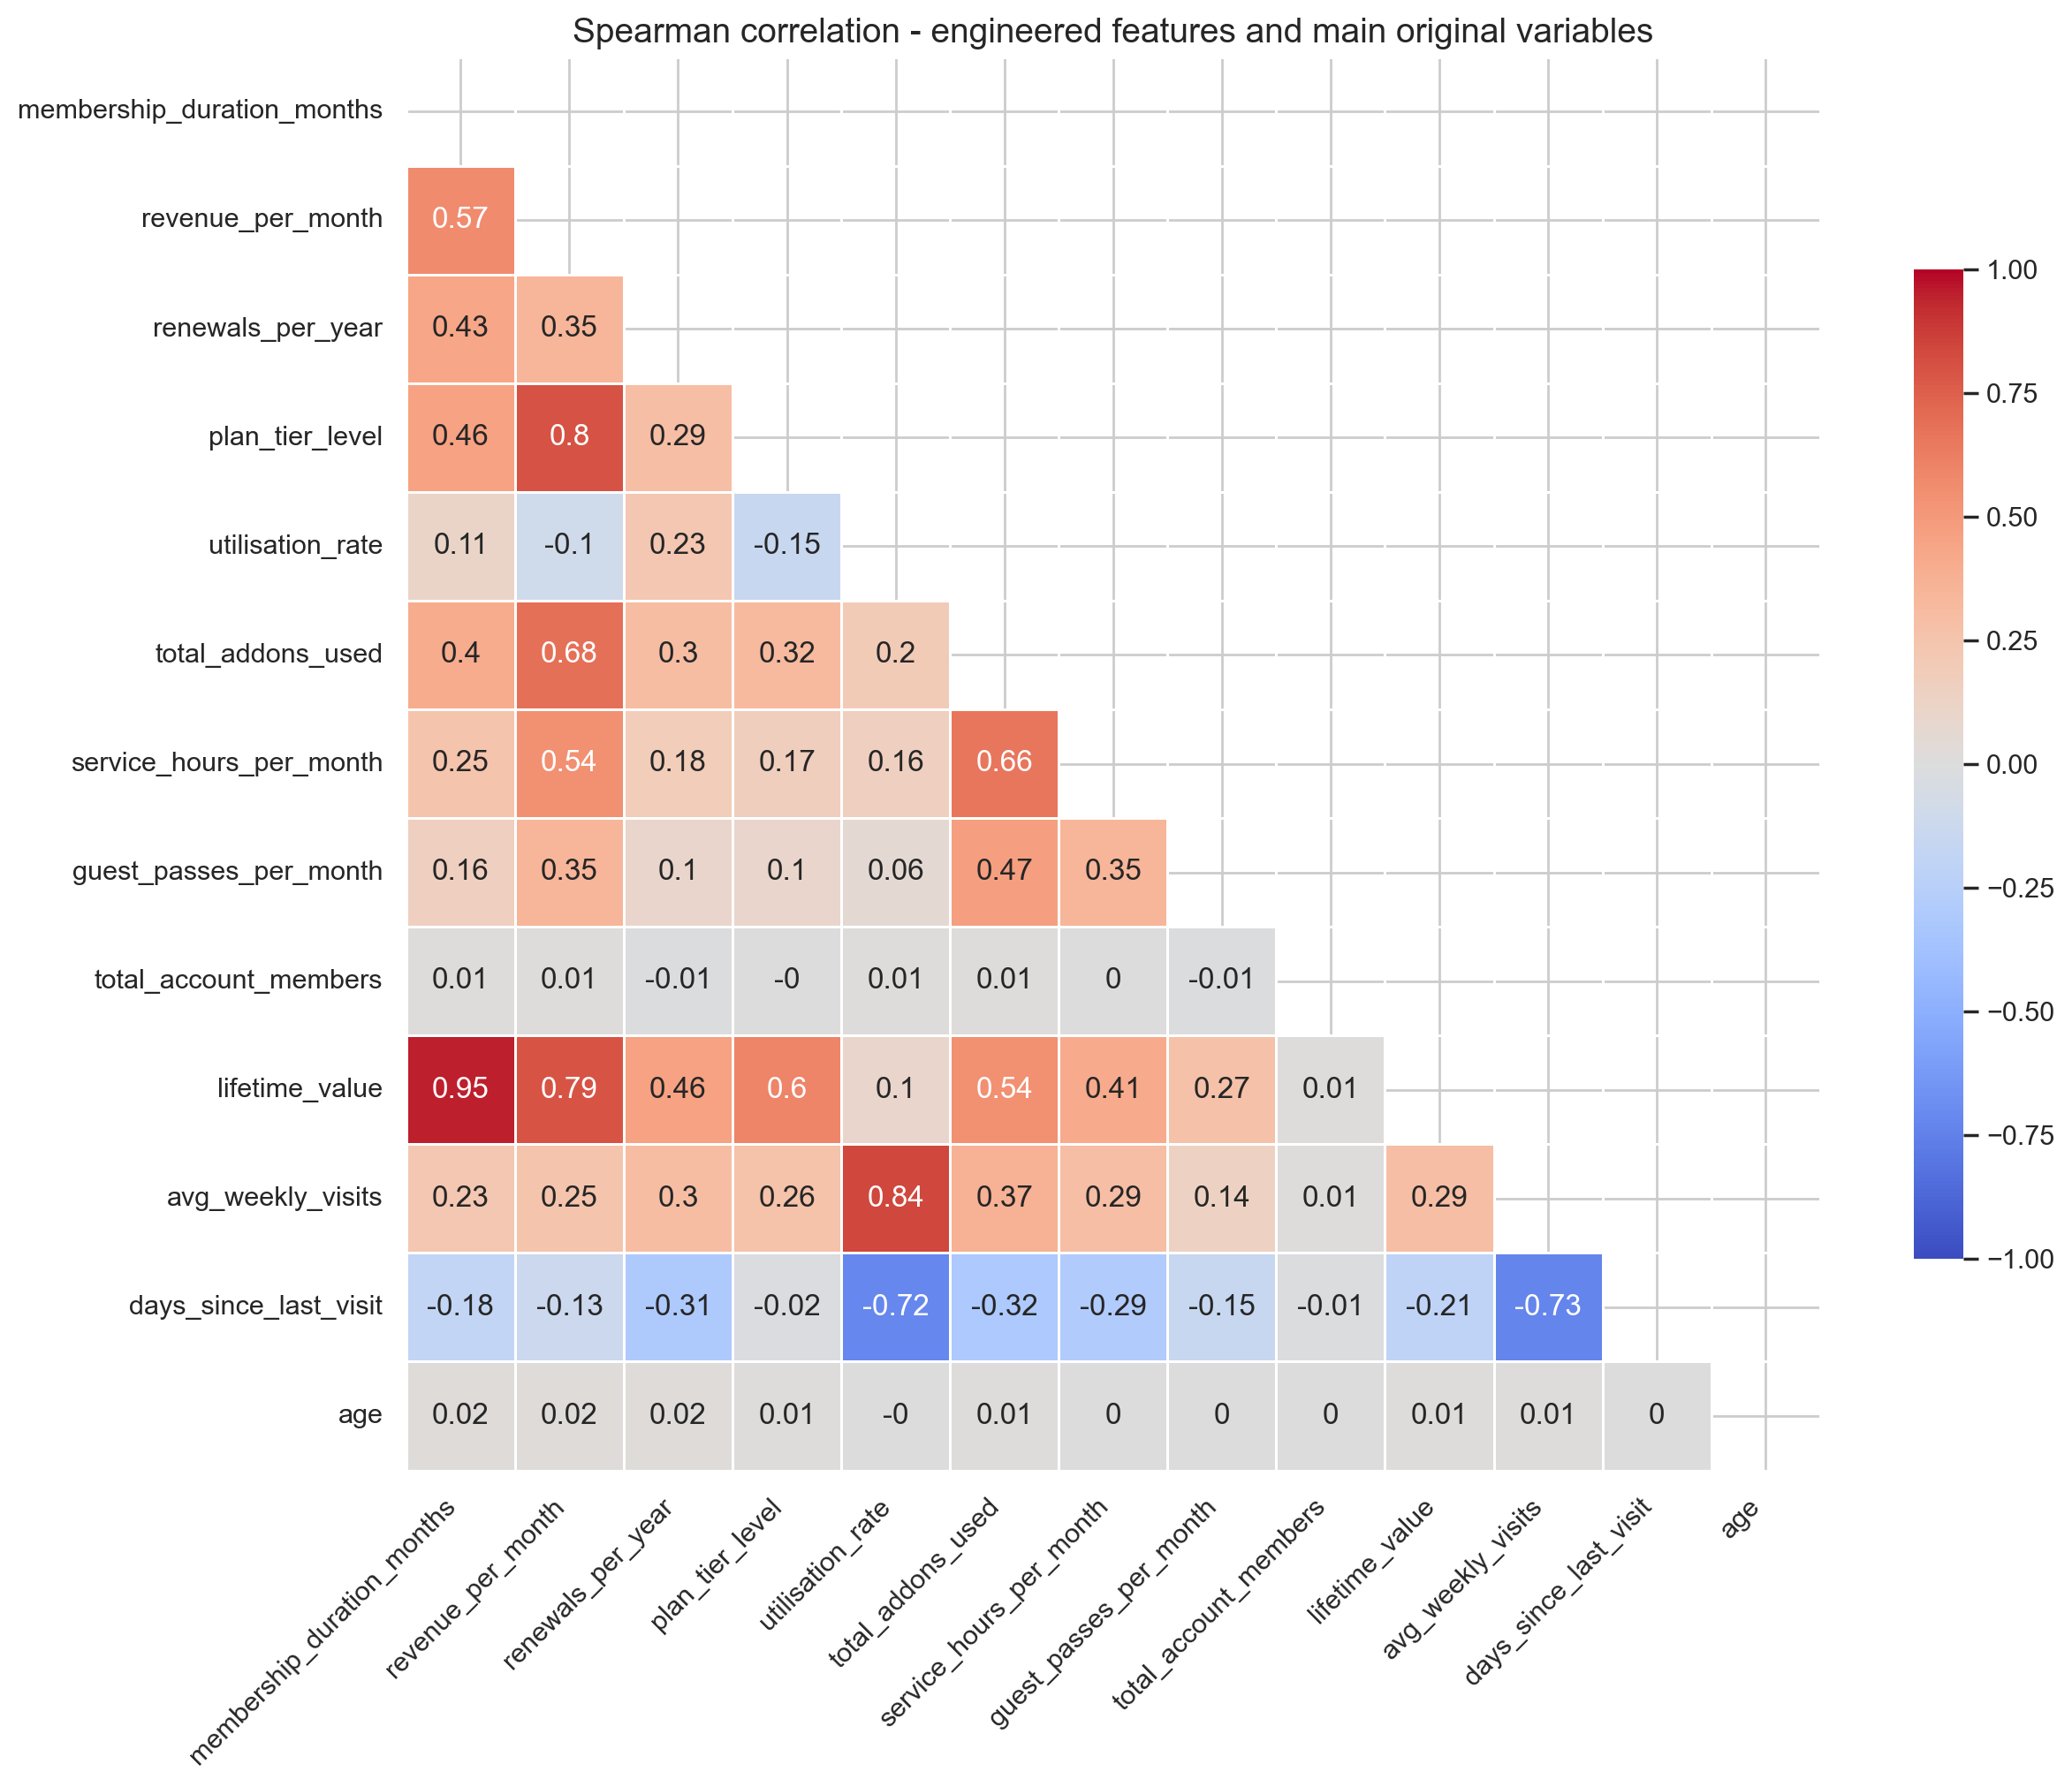

Spearman
lifetime_value        membership_duration_months      0.95
avg_weekly_visits     utilisation_rate                0.84
plan_tier_level       revenue_per_month               0.80
lifetime_value        revenue_per_month               0.79
days_since_last_visit avg_weekly_visits              -0.73
                      utilisation_rate               -0.72

In [186]:
fe_corr_columns = engineered_features + ["lifetime_value", "avg_weekly_visits", "days_since_last_visit", "age"]
fe_corr = dataset[fe_corr_columns].corr(method="spearman")
fe_mask = np.triu(np.ones_like(fe_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10), layout="constrained")
sns.heatmap(fe_corr.round(2), mask=fe_mask, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation - engineered features and main original variables", fontsize=14)
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")
plt.show()

# Pairs with |rho| >= 0.7
fe_pairs = fe_corr.where(~fe_mask).stack()
fe_pairs[fe_pairs.abs() >= 0.7].sort_values(key=abs, ascending=False).round(2).to_frame("Spearman")

Only a few pairs are strongly related:

- `membership_duration_months` and `lifetime_value` (0.95). This confirms that lifetime value mostly measures how long someone stayed, which is the reason for creating `revenue_per_month`.
- `utilisation_rate` and `avg_weekly_visits` (0.84). Both measure how often the member comes in, so only one of them should be used in the behavioural clustering. `utilisation_rate` has the advantage of being comparable across plans.
- `revenue_per_month` and `plan_tier_level` (0.80). The monthly value is largely the price of the plan, so in the value perspective these two would be partly redundant.
- `days_since_last_visit` is negatively related to both visit measures (around -0.7): members who come often were there recently.

The remaining engineered features (`total_addons_used`, `service_hours_per_month`, `guest_passes_per_month`, `renewals_per_year`, `total_account_members`) are only moderately related to the rest, so they bring information that the original variables did not capture directly.

### 3.3.13 Value vs. Engagement

The two perspectives side by side: how much a member is worth per month against how much of their plan they actually use.

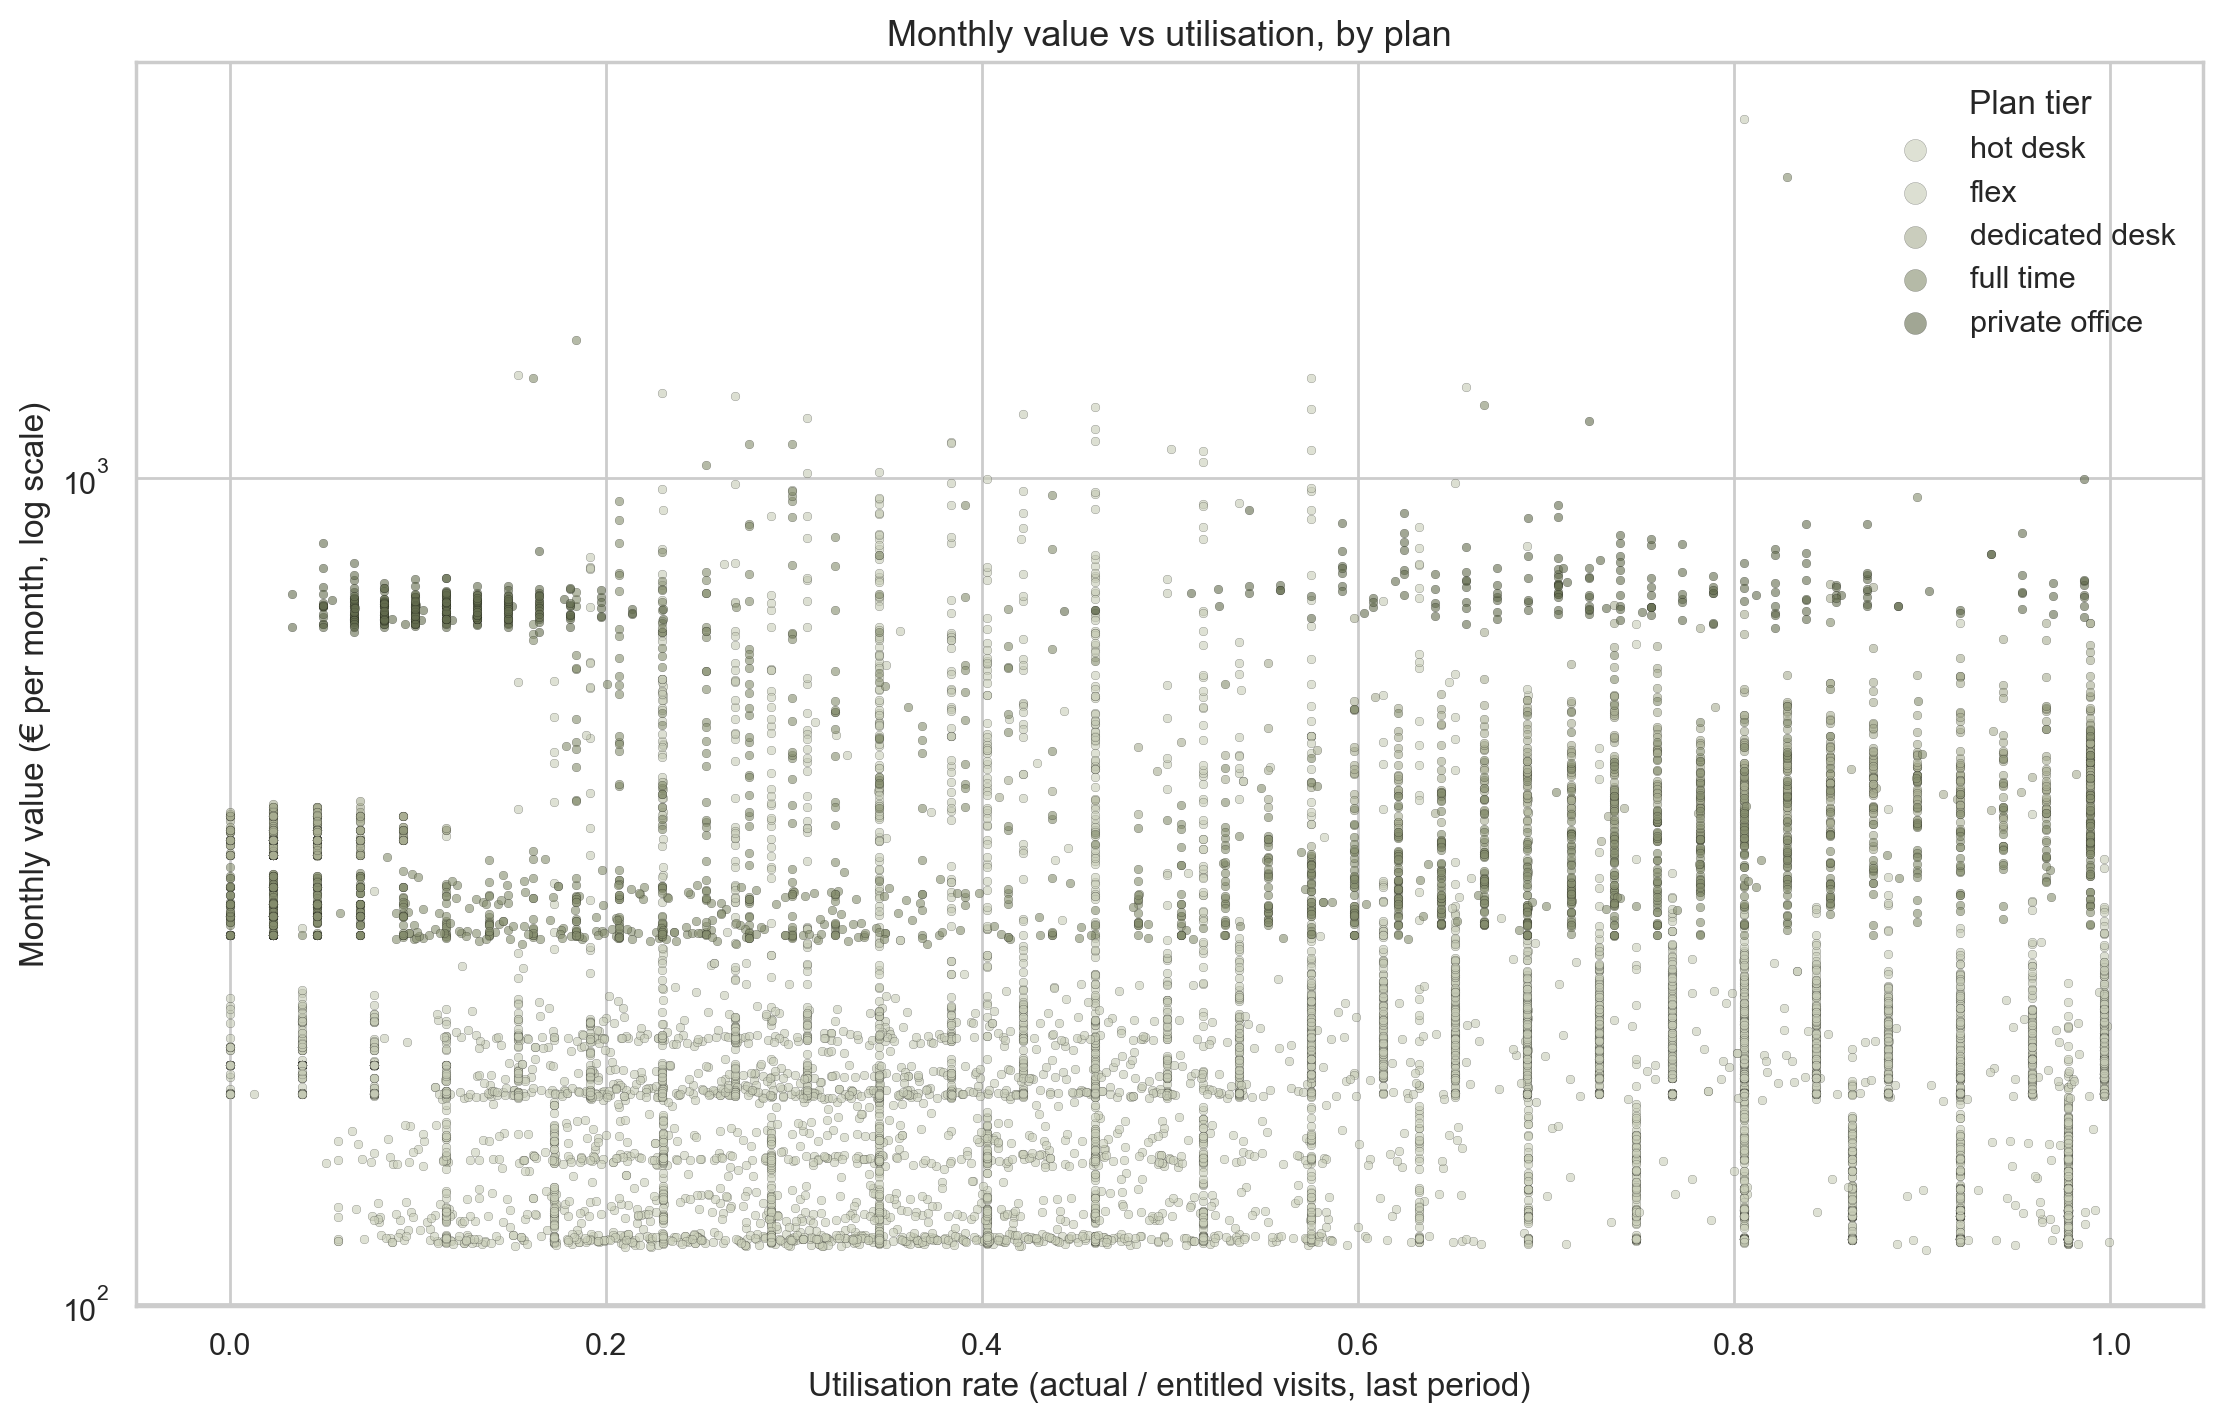

In [187]:
plot_data = dataset.dropna(subset=["revenue_per_month", "utilisation_rate", "plan_tier"])

fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
for tier in TIER_ORDER:
    subset = plot_data[plot_data["plan_tier"] == tier]
    ax.scatter(subset["utilisation_rate"], subset["revenue_per_month"], s=10, alpha=0.6, color=TIER_COLORS[tier],
               edgecolors="black", linewidths=0.1, label=tier)
ax.set_yscale("log")
ax.set_xlabel("Utilisation rate (actual / entitled visits, last period)")
ax.set_ylabel("Monthly value (€ per month, log scale)")
ax.set_title("Monthly value vs utilisation, by plan", fontsize=13)
ax.legend(title="Plan tier", markerscale=2.5, frameon=False, bbox_to_anchor=(1, 1))
plt.show()

Each plan forms a horizontal band, because the monthly value is mostly set by the plan price. Within every band, though, members are spread across the whole range of utilisation, from 0 to 1. The private office band is particularly clear: a dense group of members at very low utilisation, next to another group that uses most of their days. This is the main reason we expect value and behaviour to produce different segmentations, and why combining both perspectives should give a richer picture than either one on its own.

**Summary of the engineered features:**

| Perspective | Most promising features | Notes |
|---|---|---|
| Value | `revenue_per_month`, `membership_duration_months`, `renewals_per_year` | `revenue_per_month` and `plan_tier_level` overlap (ρ = 0.80); `renewals_per_year` needs the short-membership inconsistency checked |
| Behaviour | `utilisation_rate`, `total_addons_used`, `service_hours_per_month`, `guest_passes_per_month`, `days_since_last_visit` | `utilisation_rate` replaces `avg_weekly_visits`; the service features need a log transformation |
| Description only | `total_account_members`, `age`, `industry`, `is_active` | Useful to describe the clusters, but they barely separate members (section 2.6.2.3) |


## 3.4 Export the Clean Data

The cleaned dataset, including the engineered features and the outlier flags, is saved to `data/clean`, so the clustering notebook (Delivery 2) can load it directly instead of repeating the cleaning. The original file in `data/raw` is never modified.

A few things to keep in mind when loading it:

- The values set to missing during the cleaning are saved as empty cells. They are **not** imputed yet; that is the first step of the preprocessing.
- An empty `membership_end` means the membership is still active (see `is_active`), not that the date is missing.
- Dates are saved as `YYYY-MM-DD`; pass them to `parse_dates` when reading the file to get them back as dates.

In [188]:
# Save the cleaned dataset (same separator as the original file)
CLEAN_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
dataset.to_csv(CLEAN_DATA_PATH, sep=";", date_format="%Y-%m-%d")
print(f"Saved {len(dataset):,} members and {dataset.shape[1]} columns to {CLEAN_DATA_PATH}")

# Check that the file reads back with the same shape
clean_check = pd.read_csv(CLEAN_DATA_PATH, sep=";", index_col="member_id",
                          parse_dates=["membership_start", "membership_end", "last_badge_swipe"])
print(f"Read back: {clean_check.shape[0]:,} members and {clean_check.shape[1]} columns")

Saved 15,046 members and 43 columns to ..\data\clean\acdc_dataset_clean.csv
Read back: 15,046 members and 43 columns


# 4. Conclusions

TODO: key findings and what is left for preprocessing (filling missing values, encoding, scaling).